In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.fft import fft
import nest
import json
from collections import defaultdict
from itertools import product
import random
from nested_dict import nested_dict


/tmp/ipykernel_15670/2006677074.py:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd



              -- N E S T --
  Copyright (C) 2004 The NEST Initiative

 Version: 3.6.0
 Built: Sep 28 2023 11:53:34

 This program is provided AS IS and comes with
 NO WARRANTY. See the file LICENSE for details.

 Problems or suggestions?
   Visit https://www.nest-simulator.org

 Type 'nest.help()' to find out more about NEST.



In [2]:
# Model Params
complete_area_list = ['V1', 'V2', 'V3', 'V4', 'V3A', 'DP', 'V6', 'MT', 'V4t', 
                      'PIP', 'TEO', 'V6A', 'TEOm', '8m', '8l', 'MIP', 'F1', 
                      '45B', 'STPc', 'LIP', 'PBc', '8r', 'MST', 'F3', '7A', 'F5', 
                      'F4', '46d', '9-46v', 'VIP', '9-46d', 'TEpd', '46v', 'STPi', 
                      'F2', 'F7', 'PGa', 'F6', 'TEpv', 'STPr', 'IPa', 'TEad', 'TH-TF']

population_list = ['23E', '23I', '4E', '4I', '5E', '5I', '6E', '6I']



# -----------------------------------------------------------------------------
# Simulation controls
# -----------------------------------------------------------------------------

scaling_factor = 1
dt_sim_ms = 0.1
T_ms = 700.0             # Simulation time
record_interval_ms = 1.0   # original dtbinpop = 0.001 s
transient_ms = 100.0
seed = 456123

# -----------------------------------------------------------------------------
# Data
# -----------------------------------------------------------------------------

# Load the indegree and external indegree data
with open('visuomotor_connection_prob_data_1.json', 'r') as f:
    connection_probs_dict = json.load(f)

# import data from the model
with open('Model_data_2.json', 'r') as f:
    model_dat = json.load(f)

# import mean and sigma input data from the simulated Siegert model
with open('mu_values.json', 'r') as f:
    mu_sigma_dat = json.load(f)
 
# Load the indegree and external indegree data
with open('visuomotor_indegree_data_2.json', 'r') as f:
    indegree_dict = json.load(f)

distance_dict = model_dat['distances']
neuron_numbers = model_dat['neuron_numbers']   # Neuron numbers in 1mm^2 patch  add Scaling effect later in .py file




neuron_params = {
    'cm'        : 250,   # pF
    'i_offset'  : 0.0,   # nA
    'tau_m'     : 10.0,  # ms
    'tau_refrac': 2.0,   # ms
    'tau_syn_E' : 0.5,   # ms
    'tau_syn_I' : 0.5,   # ms
    'v_reset'   : -65.0, # mV
    'v_rest'    : -65.0, # mV
    'v_thresh'  : -50.0  # mV
}

rho_0 = 10.0             # Baseline firing rate at threshold (in Hz)
Delta_V = 5.0            # Softness of the threshold (in mV) - also called "noise level" or "threshold width"

V_reset = neuron_params["v_reset"] - neuron_params["v_rest"]  # 0 mV
V_T_star = neuron_params["v_thresh"] - neuron_params["v_rest"] # 15 mV
E_L = 0.0

C_m_pF = neuron_params["cm"]
tau_m_ms = neuron_params["tau_m"]
tau_syn_ex_ms = neuron_params["tau_syn_E"]
tau_syn_in_ms = neuron_params["tau_syn_I"]
t_ref_ms = neuron_params["tau_refrac"]

# Means and standard deviations of delays from given source populations (ms)
d_mean = {'E': 1.5, 'I': 0.75}
d_sd = {'E': 0.75, 'I': 0.375}

delay_E_ms = d_mean["E"]        # ms
delay_I_ms = d_mean["I"]        # ms

# Adaptation parameters
tau_sfa_ms = [100.0] # not used
q_sfa = [0.0] # not used

# Background rate per synapse
bg_rate = 10. # spikes/s

# Relative inhibitory synaptic weight
g = -14.

# Mean synaptic weight for all excitatory projections except L4e->L2/3e
w_mean = 87.8 # pA
w_ext = 87.8 # pA
# Mean synaptic weight for L4e->L2/3e connections 
# See p. 801 of the paper, second paragraph under 'Model Parameterization', 
# and the caption to Supplementary Fig. 7
w_234 = 2*w_mean # pA


In [43]:
neuron_numbers['F1']

{'23E': 8054.203541002283,
 '23I': 2271.8282385634243,
 '4E': 5800.1368076045355,
 '4I': 1450.100368189151,
 '5E': 15870.52261436963,
 '5I': 3484.970429753331,
 '6E': 11336.249669460385,
 '6I': 2321.588331057258,
 'total': 50589.600000000006}

In [4]:
mu_sigma_dat['V1']['23E']

18.89194329953651

In [5]:
def create_poisson_input(bg_rate, K_ext_dict, area_list, pop_list, verbose = False):
    """
    Create one Poisson generator per population.
    Rate is scaled by external indegree.
    """

    poisson_source = {}

    for area in area_list:
        poisson_source[area] = {}

        for pop in pop_list:

            K_ext = K_ext_dict[area][pop]['external']['external']   # external indegree

            rate = bg_rate * K_ext   # Hz

            pg = nest.Create("poisson_generator", 1)
            nest.SetStatus(pg, {"rate": rate})

            poisson_source[area][pop] = pg
            if verbose:
                print(f"Poisson: {area} {pop} | K_ext={K_ext:.1f} | rate={rate:.1f} Hz")

    return poisson_source

In [6]:
# Create populations

def create_mesoscopic_populations( mean_input_dict, neuron_numbers, rho_0, Delta_V, area_list, tau_syn_ex_ms, tau_syn_in_ms, population_list, verbose=False):
    """
    Build mesoscopic populations (gif_pop_psc_exp) for multi-area network.

    Returns:
        populations[area][pop] = NEST node
    """

    populations = {}

    for area in area_list:
        populations[area] = {}

        for pop in population_list:

            # ------------------------------------------------------------------
            # Population size (REAL values now)
            # ------------------------------------------------------------------
            N_pop_float = neuron_numbers[area][pop]
            N_pop = int(np.round(N_pop_float))

            # ------------------------------------------------------------------
            # External input
            # ------------------------------------------------------------------
            mu_mV = mean_input_dict[area][pop]
            I_e_pA = mu_mV * C_m_pF / tau_m_ms

            # ------------------------------------------------------------------
            # Create node
            # ------------------------------------------------------------------
            node = nest.Create("gif_pop_psc_exp", 1)

            nest.SetStatus(node, {
                "C_m": C_m_pF,
                "I_e": np.array([I_e_pA] , dtype=float),
                "lambda_0": rho_0,
                "Delta_V": Delta_V,
                "tau_m": tau_m_ms,
                "V_T_star": V_T_star,
                "V_reset": V_reset,
                "len_kernel": -1,  # -1 triggers automatic history size
                "N": N_pop,
                "t_ref": t_ref_ms,
                "tau_syn_ex": tau_syn_ex_ms,
                "tau_syn_in": tau_syn_in_ms,
                "E_L": E_L,
            })

            populations[area][pop] = node

            if verbose:
                print(
                    f"{area, pop} | ",
                    f"N={N_pop_float} | ",
                    f"mu={mu_mV:7.2f} mV | ",
                    f"I_e={I_e_pA:9.2f} pA"
                )


    return populations

In [7]:
J_psc = w_mean
J_psc

87.8

In [8]:
J_psp = J_psc * tau_syn_ex_ms / C_m_pF        # mV
J_psp


0.1756

In [9]:
p = 1
J_psp *= p
J_psp


0.1756

In [10]:
J_pA = J_psp * (C_m_pF / tau_syn_ex_ms)

J_pA


87.8

In [11]:
def weights_calculation( tau_syn_ex_ms, tau_syn_in_ms, C_m_pF, w_mean, g, conn_probs_dict, 
                                    cc_weights_factor, cc_weights_I_factor, scaling_factor, area_list, pop_list, meanfield_connectivity=True):

    synaptic_weights_dict = nested_dict()

    for target_area, target_pop, source_area, source_pop in product(area_list, pop_list, area_list, pop_list):

        p = conn_probs_dict[target_area][target_pop][source_area][source_pop]

        # ------------------------------------------------------------------
        # 1. Base PSC weight (like original Potjans weight_matrix)
        # ------------------------------------------------------------------
        if 'E' in source_pop:
            J_psc = w_mean                      # pA
            tau_syn = tau_syn_ex_ms
        else:
            J_psc = g * w_mean                  # pA
            tau_syn = tau_syn_in_ms

        # ------------------------------------------------------------------
        # 2. PSC → PSP (exact original formula)
        # Js *= (tau_syn * 1e-3) / cm * 1e3
        # cm must be in nF → convert from pF
        # ------------------------------------------------------------------
        #C_m_nF = C_m_pF 

        J_psp = J_psc * tau_syn / C_m_pF        # mV

        # ------------------------------------------------------------------
        # 3. Scaling factor (network downscaling)
        # ------------------------------------------------------------------
        J_psp /= scaling_factor

        # ------------------------------------------------------------------
        # 4. Mean-field connectivity
        # ------------------------------------------------------------------
        if meanfield_connectivity:
            J_psp *= p
            effective_p = 1.0
        else:
            effective_p = p

        # ------------------------------------------------------------------
        # 5. Convert to NEST units (pA)
        # J_syn_nestfactor = C_m / tau_syn
        # ------------------------------------------------------------------
        J_pA = J_psp * (C_m_pF / tau_syn)

        # ------------------------------------------------------------------
        # 6. Apply CC scaling (if multi-area)
        # ------------------------------------------------------------------
        if source_area != target_area:
            J_pA *= cc_weights_factor
            if 'I' in target_pop:
                J_pA *= cc_weights_I_factor
        # ------------------------------------------------------------------
        # 7. SPECIAL RULE: L4E → L23E (intra-area only)
        # ------------------------------------------------------------------
        if (source_area == target_area and
            source_pop == '4E' and
            target_pop == '23E'):

            J_pA *= 2.0

        # -----
        # ------------------------------------------------------------------
        # 7. Store result
        # ------------------------------------------------------------------
        synaptic_weights_dict[target_area][target_pop][source_area][source_pop] = J_pA

    return synaptic_weights_dict

In [12]:
def Delay_dict(distance_dictionary, speed, area_list):
    ''' Create a dictionary of delays between areas 
    
    Parameters:
    -----------
        distance_dictionary : Dictionary of distance between areas
        speed : inter-area speed

    Returns:
    -----------
        delay = s (distance) / v (interarea speed)'''

    delay_dict = {}
    for source_area in area_list:
        target_Dict = {}
        for target_area in area_list:
            target_Dict[target_area] = distance_dictionary[source_area][target_area] / speed
        
        delay_dict[source_area] = target_Dict

    return delay_dict

In [13]:
# Connect poisson generators to populations
def connect_poisson_input(
    populations,
    poisson_inputs,
    weight_ext_pA,
    delay_ms,
    area_list,
    pop_list
):
    """
    Connect Poisson generators to mesoscopic populations
    """

    for area in area_list:
        for pop in pop_list:

            pre = poisson_inputs[area][pop]
            post = populations[area][pop]

            nest.Connect(
                pre,
                post,
                "all_to_all",
                {
                    "weight": weight_ext_pA,
                    "delay": delay_ms
                }
            )

    print("Poisson input connected")

In [14]:
# Setup connections
def connect_mesoscopic_populations( populations, weights_dictionary, ex_delay, in_delay, 
                                   delay_dictionary, area_list, pop_list, verbose=False):
    """
    Connect mesoscopic populations using gif_pop_psc_exp model.

    populations[area][pop] = node
    weights_dictionary[...] = pA weights
    """

    connection_count = 0

    for target_area, target_pop, source_area, source_pop in product(
        area_list, pop_list, area_list, pop_list
    ):

        pre = populations[source_area][source_pop]
        post = populations[target_area][target_pop]

        weight = weights_dictionary[target_area][target_pop][source_area][source_pop]

        # Skip zero weights (important for speed)
        #if abs(weight) < 1e-12:
        #    continue

        # ------------------------------------------------------------------
        # DELAYS
        # ------------------------------------------------------------------
        if target_area == source_area:
            # intra-area
            if 'E' in source_pop:
                delay = ex_delay
            else:
                delay = in_delay
        else:
            # inter-area
            delay = delay_dictionary[target_area][source_area]

        # ------------------------------------------------------------------
        # CONNECT
        # ------------------------------------------------------------------
        syn_dict = {
            "weight": float(weight),   # must be scalar
            "delay": float(delay),
            "synapse_model": "static_synapse"
        }

        nest.Connect(pre, post, "all_to_all", syn_dict)

        connection_count += 1

        if verbose and connection_count < 20:  # avoid flooding output
            print(
                f"{source_area:6s}-{source_pop:4s} → "
                f"{target_area:6s}-{target_pop:4s} | "
                f"w={weight:8.2f} pA | d={delay:5.2f} ms"
            )

    print(f"\nTotal connections created: {connection_count}")

In [15]:
delay_dict = Delay_dict(distance_dict, 3.5, complete_area_list)

In [16]:
def create_recording_devices(
    populations,
    area_list,
    pop_list,
    record_interval_ms,
    verbose=False
):
    """
    Create and connect multimeters and spike recorders
    for each mesoscopic population.
    
    Returns:
        multimeters[area][pop]
        spike_recorders[area][pop]
    """

    multimeters = {}
    spike_recorders = {}

    for area in area_list:
        multimeters[area] = {}
        spike_recorders[area] = {}

        for pop in pop_list:

            node = populations[area][pop]

            # --------------------------------------------------------------
            # Multimeter
            # --------------------------------------------------------------
            mm = nest.Create("multimeter")

            nest.SetStatus(mm, {
                "record_from": ["n_events", "mean"],
                "interval": record_interval_ms,
            })

            nest.Connect(mm, node)

            multimeters[area][pop] = mm

            # --------------------------------------------------------------
            # Spike recorder
            # --------------------------------------------------------------
            sr = nest.Create("spike_recorder")

            nest.Connect(node, sr)

            spike_recorders[area][pop] = sr

            if verbose:
                print(f"Recording set: {area:6s} {pop:4s}")

    return multimeters, spike_recorders

In [17]:
#recorder = create_recording_devices(populations, complete_area_list, population_list, record_interval_ms=record_interval_ms)

In [18]:
def extract_mesoscopic_data(
    multimeters,
    spike_recorders,
    neuron_numbers,
    area_list,
    pop_list,
    record_interval_ms,
    T_ms,
    transient_ms=100.0,
    verbose=False
):
    """
    Extract firing rates from mesoscopic simulation.

    Returns:
        series[area][pop]  -> full time series
        summary[area][pop] -> mean/std rates
        time_axis          -> common time axis (ms)
    """

    dt_rec_s = record_interval_ms / 1000.0

    series = {}
    summary = {}

    for area in area_list:
        series[area] = {}
        summary[area] = {}

        for pop in pop_list:

            # --------------------------------------------------------------
            # Get devices
            # --------------------------------------------------------------
            mm = multimeters[area][pop]
            sr = spike_recorders[area][pop]

            mm_events = nest.GetStatus(mm)[0]["events"]
            sr_events = nest.GetStatus(sr)[0]["events"]

            # --------------------------------------------------------------
            # Multimeter data
            # --------------------------------------------------------------
            times_mm = np.asarray(mm_events["times"], dtype=float)
            n_events = np.asarray(mm_events["n_events"], dtype=float)
            mean_vals = np.asarray(mm_events["mean"], dtype=float)

            N_pop = int(np.round(neuron_numbers[area][pop]))

            # ✔ Correct rate from n_events
            rate_from_n_events = n_events / (N_pop * dt_rec_s)

            # ⚠️ mean is tricky → keep but don’t trust blindly
            rate_from_mean_candidate = mean_vals / (N_pop * dt_rec_s)

            # --------------------------------------------------------------
            # Spike recorder → ground truth
            # --------------------------------------------------------------
            spike_times = np.asarray(sr_events["times"], dtype=float)

            bins = np.arange(0.0, T_ms + record_interval_ms, record_interval_ms)
            spike_counts, _ = np.histogram(spike_times, bins=bins)

            rate_from_spikes = spike_counts / (N_pop * dt_rec_s)
            time_bins = bins[:-1] + 0.5 * record_interval_ms

            # --------------------------------------------------------------
            # Store full series
            # --------------------------------------------------------------
            series[area][pop] = {
                "times_mm": times_mm,
                "rate_from_n_events": rate_from_n_events,
                "rate_from_mean_candidate": rate_from_mean_candidate,
                "time_bins": time_bins,
                "rate_from_spikes": rate_from_spikes,
            }

            # --------------------------------------------------------------
            # Steady-state stats
            # --------------------------------------------------------------
            steady_spike = time_bins >= transient_ms
            steady_mm = times_mm >= transient_ms

            mean_spike = rate_from_spikes[steady_spike].mean()
            std_spike = rate_from_spikes[steady_spike].std()

            mean_ne = rate_from_n_events[steady_mm].mean()
            mean_mean = rate_from_mean_candidate[steady_mm].mean()

            summary[area][pop] = {
                "mean_rate_spikes_Hz": mean_spike,
                "std_rate_spikes_Hz": std_spike,
                "mean_rate_n_events_Hz": mean_ne,
                "mean_rate_mean_candidate_Hz": mean_mean,
                "total_spikes": spike_times.size
            }

            if verbose:
                print(
                    f"{area:6s} {pop:4s} | "
                    f"<rate>={mean_spike:6.2f} Hz | "
                    f"spikes={spike_times.size:7d}"
                )

    return series, summary, time_bins

In [19]:
def simulation_mesoscopic(
    sim_time_ms,
    neuron_numbers,
    mean_input_dict,
    inh_strength,
    delay_dict,
    area_list,
    population_list,  
    tau_syn_ex_ms = 0.5, 
    tau_syn_in_ms = 0.5, 
    bg_rate = 10,
    rho_0=10.0,
    Delta_V=5.0,
    record_interval_ms=1.0,
    transient_ms=100.0,
    seed=123
):
    """
    Full mesoscopic simulation using gif_pop_psc_exp
    """

    # ------------------------------------------------------------------
    # 1. NEST setup
    # ------------------------------------------------------------------
    nest.set_verbosity("M_WARNING")
    nest.ResetKernel()

    nest.SetKernelStatus({
        "resolution": 0.1,
        "print_time": True,
        "local_num_threads": 4,
        "rng_seed": seed
    })

    print("NEST initialized")

    # ------------------------------------------------------------------
    # 2.1 CREATE Sources
    # ------------------------------------------------------------------
    
    #poisson_sources = create_poisson_input(bg_rate, indegree_dict, area_list, population_list)
    
    print("Poisson sources created")

    # ------------------------------------------------------------------
    # 2.2 CREATE POPULATIONS
    # ------------------------------------------------------------------
    populations = create_mesoscopic_populations( mean_input_dict, neuron_numbers, rho_0, Delta_V,  tau_syn_ex_ms =tau_syn_ex_ms, tau_syn_in_ms = tau_syn_in_ms,   
                                                area_list=complete_area_list, population_list=population_list, verbose=False)

    print("Populations created")

    # ------------------------------------------------------------------
    # 3.1 SOURCES CONNECT
    # ------------------------------------------------------------------
    
    print("Connecting SOURCES to network...")

    #connect_poisson_input(populations=populations, poisson_inputs=poisson_sources, weight_ext_pA=w_ext, 
    #                      delay_ms=delay_E_ms, area_list=complete_area_list, pop_list=population_list)

    


    weights_dict = weights_calculation(tau_syn_ex_ms, tau_syn_in_ms, C_m_pF, w_mean=w_mean, g= inh_strength, conn_probs_dict=connection_probs_dict,
                    scaling_factor=1, area_list=complete_area_list, pop_list=population_list, cc_weights_factor=1, cc_weights_I_factor=1)
    # ------------------------------------------------------------------
    # 3.2 CONNECT POPULATIONS
    # ------------------------------------------------------------------
    
    print("Connecting network...")

    for tgt_area in area_list:
        for tgt_pop in population_list:
            for src_area in area_list:
                for src_pop in population_list:
                # --------------------------------------------------
                    # ISOLATE F1 FROM INCOMING PROJECTIONS
                    # --------------------------------------------------
    
                    # Skip connections from OTHER areas into F1
                    # but still allow F1 internal connectivity
                    #if tgt_area == 'F1' and src_area != 'F1':
                    #    continue

                    weight = weights_dict[tgt_area][tgt_pop][src_area][src_pop]

                    #if weight == 0:
                    #    continue

                    pre = populations[src_area][src_pop]
                    post = populations[tgt_area][tgt_pop]

                    # Delay logic
                    if tgt_area == src_area:
                        delay = 1.5 if 'E' in src_pop else 0.75
                    else:
                        delay = delay_dict[tgt_area][src_area]

                    nest.Connect(
                        pre,
                        post,
                        "all_to_all",
                        {
                            "weight": weight,
                            "delay": delay,
                            "synapse_model": "static_synapse"
                        }
                    )

    print("Connections done")

    # ------------------------------------------------------------------
    # 4. RECORDING
    # ------------------------------------------------------------------
    multimeters = {}
    spike_recorders = {}

    for area in area_list:
        multimeters[area] = {}
        spike_recorders[area] = {}

        for pop in population_list:

            node = populations[area][pop]

            mm = nest.Create("multimeter", {
                "record_from": ["n_events", "mean"],
                "interval": 1.0
            })

            sr = nest.Create("spike_recorder")

            nest.Connect(mm, node)
            nest.Connect(node, sr)

            multimeters[area][pop] = mm
            spike_recorders[area][pop] = sr

    print("Recording devices connected")

    # ------------------------------------------------------------------
    # 5. SIMULATION
    # ------------------------------------------------------------------
    print(f"Simulating {sim_time_ms} ms...")
    nest.Simulate(sim_time_ms)

    # ------------------------------------------------------------------
    # 6. EXTRACT DATA (CORRECT WAY)
    # ------------------------------------------------------------------
    
    #results = extract_mesoscopic_data(multimeters, spike_recorders, neuron_numbers, area_list=complete_area_list, pop_list=population_list, record_interval_ms=record_interval_ms,
    #                        T_ms=T_ms)

    # ------------------------------------------------------------------
    # 6. EXTRACT DATA (CORRECT WAY)
    # ------------------------------------------------------------------
    dt_s = record_interval_ms / 1000.0

    results = {}

    for area in area_list:
        results[area] = {}

        for pop in population_list:
            # Multimeter
            mm_events = nest.GetStatus(multimeters[area][pop])[0]["events"]

            times_mm = np.asarray(mm_events["times"], dtype=float)
            n_events = np.asarray(mm_events["n_events"])
            mean = np.asarray(mm_events["mean"])

            N_pop = neuron_numbers[area][pop]

            rate_1 = n_events / N_pop / 0.0001
            rate_2 = mean / N_pop / 0.0001

            rate_from_n_events = rate_1
            rate_from_mean = rate_2

            # spike recorder

            sr_events = nest.GetStatus(spike_recorders[area][pop])[0]["events"]

            spike_times = np.asarray(sr_events["times"], dtype=float)

            bins = np.arange(0.0, sim_time_ms + record_interval_ms, record_interval_ms)

            spike_counts, _ = np.histogram(spike_times, bins=bins)
            rate_from_spikes = spike_counts / N_pop / dt_s

            time_bins = (bins[:-1] + 0.5 * record_interval_ms)

            
            # TRANSIENT REMOVAL
            steady_mm = times_mm >= transient_ms
            steady_spk = time_bins >= transient_ms

            # SUMMARY STATISTICS
            results[area][pop] = {
                # Mean Rates
                "mean_rate_spikes_Hz": rate_from_spikes[steady_spk].mean(),
                #"std_rate_spikes_Hz": rate_from_spikes[steady_spk].std(),
                
                #"mean_rate_n_events_Hz": rate_from_n_events[steady_mm].mean(),
                #"std_rate_n_events_Hz": rate_from_n_events[steady_mm].std(),
                
                "mean_rate_mean_Hz": rate_from_mean[steady_mm].mean(),
                #"std_rate_mean_Hz":rate_from_mean[steady_mm].std(),
                
                # Full time series
                "times_mm": times_mm,
                #"rate_from_n_events": rate_from_n_events,
                "rate_from_mean": rate_from_mean,
                "time_bins": time_bins,
                "rate_from_spikes": rate_from_spikes,

                # Raw spike times
                #"spike_times": spike_times
                }

    
    
    print("Simulation finished")
 

    return results

In [20]:
synaptic_weights = weights_calculation(tau_syn_ex_ms, tau_syn_in_ms, C_m_pF, w_mean=w_mean, g=-18, conn_probs_dict=connection_probs_dict,
                    scaling_factor=1, area_list=complete_area_list, pop_list=population_list, cc_weights_factor=1, cc_weights_I_factor=1)

In [81]:
rho_0 = 10.0
Delta_V = 5.0
seed_val = 4
tau_syn_in_ms = 0.5
tau_syn_ex_ms = 0.5
g = -14
results = simulation_mesoscopic(sim_time_ms=1400, 
                                neuron_numbers=neuron_numbers, mean_input_dict= mu_sigma_dat, 
                                inh_strength=g,delay_dict= delay_dict, 
                                area_list= complete_area_list, population_list=population_list, 
                                tau_syn_ex_ms=tau_syn_ex_ms, tau_syn_in_ms = tau_syn_in_ms,rho_0=rho_0, Delta_V=Delta_V, seed=seed_val)

NEST initialized
Poisson sources created
Populations created
Connecting SOURCES to network...
Connecting network...
Connections done
Recording devices connected
Simulating 1400 ms...
Simulation finished


# Parameter exploration

In [ ]:
import json
import os
import numpy as np
from pathlib import Path


def load_experiment_log(filepath):
    if os.path.exists(filepath):
        with open(filepath, 'r') as f:
            try:
                data = json.load(f)
            except json.JSONDecodeError:
                data = {}
    else:
        data = {}
    return data


def save_experiment_log(data, filepath):
    Path(filepath).parent.mkdir(parents=True, exist_ok=True)
    with open(filepath, 'w') as f:
        json.dump(data, f, indent=2)


def log_experiment(filepath, g_value, rng_seed, mean_network_activity,
                    activity_per_pop, std_per_pop, median_per_pop,
                    pop_list, overwrite=False):
    """
    Log a single (g, rng_seed) experiment result into the JSON file.
    Per-population values are stored as {pop_name: value} dictionaries.

    Parameters
    ----------
    filepath : str
    g_value : float
    rng_seed : int
    mean_network_activity : float
    activity_per_pop, std_per_pop, median_per_pop : array-like (length = n_pops)
        Values ordered to match pop_list.
    pop_list : list of str
        Population names, e.g. ['23E','23I','4E','4I','5E','5I','6E','6I'].
        Required now, since it defines the keys of the per-pop dicts.
    overwrite : bool
        If False (default), existing (g, seed) entries are not overwritten.
    """
    data = load_experiment_log(filepath)

    g_key = str(g_value)
    seed_key = str(rng_seed)

    if g_key not in data:
        data[g_key] = {}

    if seed_key in data[g_key] and not overwrite:
        print(f"[SKIP] Entry for g={g_value}, seed={rng_seed} already exists. "
              f"Use overwrite=True to replace it.")
        return data

    activity_arr = np.asarray(activity_per_pop, dtype=float)
    std_arr = np.asarray(std_per_pop, dtype=float)
    median_arr = np.asarray(median_per_pop, dtype=float)

    entry = {
        "mean_network_activity": float(mean_network_activity),
        "Mean_activity_per_pop": {pop: float(val) for pop, val in zip(pop_list, activity_arr)},
        "std_per_pop": {pop: float(val) for pop, val in zip(pop_list, std_arr)},
        "median_per_pop": {pop: float(val) for pop, val in zip(pop_list, median_arr)},
    }

    data[g_key][seed_key] = entry

    save_experiment_log(data, filepath)
    print(f"[SAVED] g={g_value}, seed={rng_seed}")
    return data


def list_logged_seeds(filepath, g_value):
    data = load_experiment_log(filepath)
    g_key = str(g_value)
    return sorted(data.get(g_key, {}).keys(), key=int)


In [ ]:
# Data loading
# ------------------------------------------------------------------
# Extract mean rates from results
# ------------------------------------------------------------------
def extract_mean_matrix(results, area_list, population_list):
    matrix = np.zeros((len(population_list), len(area_list)))

    for i, pop in enumerate(population_list):
        for j, area in enumerate(area_list):
            try:
                matrix[i, j] = results[area][pop]['mean_rate_spikes_Hz']
            except KeyError:
                matrix[i, j] = 0.0

    return matrix

#matrix = extract_mean_matrix(results, complete_area_list, population_list)

pop_list = ['23E','23I','4E','4I','5E','5I','6E','6I']
log_path = "bistability_experiment_log.json"

g_values = -17

for seed in [1,2]:
    # skip if already done — avoids rerunning expensive simulations
    if str(seed) in list_logged_seeds(log_path, g_values):
        continue

    rates = simulation_mesoscopic(sim_time_ms=700, neuron_numbers=neuron_numbers, mean_input_dict= mu_sigma_dat, 
                            inh_strength=g,delay_dict= delay_dict, 
                            area_list= complete_area_list, population_list=population_list, 
                            tau_syn_ex_ms=tau_syn_ex_ms, tau_syn_in_ms = tau_syn_in_ms,rho_0=rho_0, Delta_V=Delta_V, seed=seed)


    matrix = extract_mean_matrix(results, complete_area_list, population_list)

    stimulated_rates = np.array([np.mean(matrix[i]) for i in range(8)])
    stimulated_stds = np.array([np.std(matrix[i]) for i in range(8)])
    median_data = np.array([np.median(matrix[i]) for i in range(8)])

    
    log_experiment(
        filepath=log_path,
        g_value=g_values,
        rng_seed=seed,
        mean_network_activity=matrix.mean(),
        activity_per_pop=stimulated_rates,
        std_per_pop=stimulated_stds,        # or per-pop std if you compute it differently
        median_per_pop=median_data,
        pop_list=pop_list,
        overwrite=True
    )


NEST initialized
Poisson sources created
Populations created
Connecting SOURCES to network...
Connecting network...
Connections done
Recording devices connected
Simulating 700 ms...

[ 100% ] Model time: 700.0 ms, Real-time factor: 20.0132
Simulation finished
[SAVED] g=-17, seed=1
NEST initialized
Poisson sources created
Populations created
Connecting SOURCES to network...
Connecting network...


KeyboardInterrupt: 

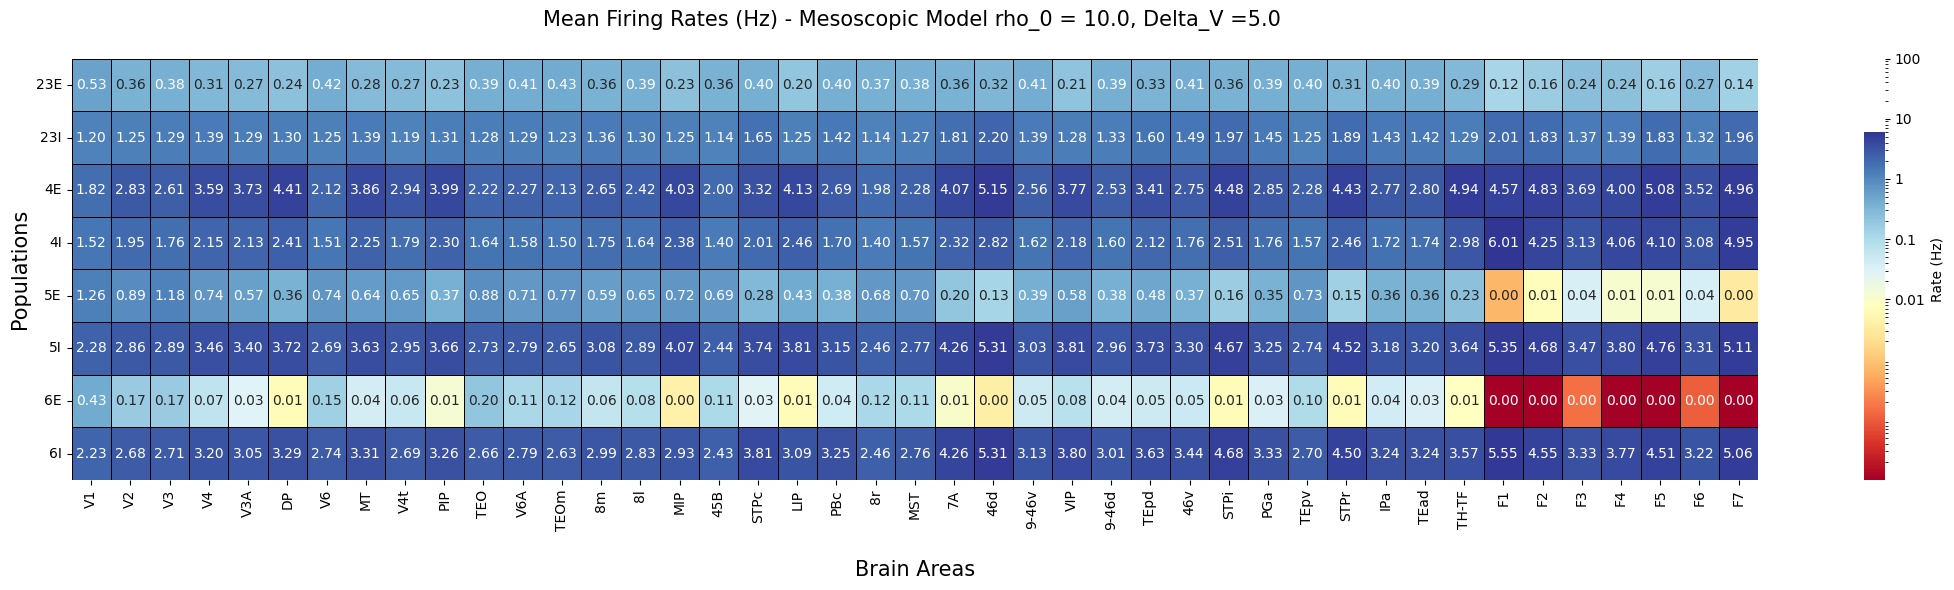

In [46]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors

# ------------------------------------------------------------------
# Extract mean rates from results
# ------------------------------------------------------------------
def extract_mean_matrix(results, area_list, population_list):
    matrix = np.zeros((len(population_list), len(area_list)))

    for i, pop in enumerate(population_list):
        for j, area in enumerate(area_list):
            try:
                matrix[i, j] = results[area][pop]['mean_rate_spikes_Hz']
            except KeyError:
                matrix[i, j] = 0.0

    return matrix

# ------------------------------------------------------------------
# Define axes
# ------------------------------------------------------------------
areas = ['V1', 'V2', 'V3', 'V4', 'V3A', 'DP', 'V6', 'MT', 'V4t', 
         'PIP', 'TEO', 'V6A', 'TEOm', '8m', '8l', 'MIP', 
         '45B', 'STPc', 'LIP', 'PBc', '8r', 'MST', '7A', 
         '46d', '9-46v', 'VIP', '9-46d', 'TEpd', '46v', 'STPi', 
         'PGa', 'TEpv', 'STPr', 'IPa', 'TEad', 'TH-TF',  
         'F1', 'F2','F3', 'F4', 'F5', 'F6', 'F7']

#areas = complete_area_list

populations = ['23E', '23I', '4E', '4I', '5E', '5I', '6E', '6I']

# ------------------------------------------------------------------
# Build matrix
# ------------------------------------------------------------------
matrix = extract_mean_matrix(results, areas, populations)

# Avoid log(0)
matrix_no_zeros = np.where(matrix <= 0, 1e-5, matrix)

# ------------------------------------------------------------------
# Plot heatmap
# ------------------------------------------------------------------
def plot_heatmap(matrix, show_annotations=True):

    plt.figure(figsize=(22, 6))

    cmap = plt.cm.RdYlBu
    norm = mcolors.LogNorm(vmin=matrix_no_zeros.min(), vmax=matrix_no_zeros.max())

    ax = sns.heatmap(
        matrix_no_zeros,
        cmap=cmap,
        norm=norm,
        annot=show_annotations,
        fmt=".2f",
        xticklabels=areas,
        yticklabels=populations,
        linewidths=0.5,
        linecolor='black'
    )

    plt.yticks(rotation=0)
    plt.xlabel("\nBrain Areas", fontsize=15)
    plt.ylabel("Populations", fontsize=15)
    plt.title(f"Mean Firing Rates (Hz) - Mesoscopic Model rho_0 = {rho_0}, Delta_V ={Delta_V} \n", fontsize=15)

    # Colorbar formatting
    cbar = ax.collections[0].colorbar
    cbar.set_label("Rate (Hz)")
    cbar.set_ticks([1e-2, 1e-1, 1, 10, 100])
    cbar.ax.set_yticklabels(['0.01', '0.1', '1', '10', '100'])

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------------
# Call plot
# ------------------------------------------------------------------
plot_heatmap(matrix, show_annotations=True)

In [ ]:
matrix

array([[5.33571525e-01, 3.59121363e-01, 3.77021253e-01, 3.08238783e-01,
        2.71592835e-01, 2.38347616e-01, 4.12506901e-01, 2.77390856e-01,
        2.71119598e-01, 2.26799661e-01, 3.82077955e-01, 4.04128943e-01,
        4.17066292e-01, 3.58839706e-01, 3.91404153e-01, 2.24843788e-01,
        3.58169308e-01, 4.05757299e-01, 2.08723891e-01, 3.98117752e-01,
        3.58222329e-01, 3.67815297e-01, 3.61684797e-01, 3.13919206e-01,
        4.07294864e-01, 2.02610985e-01, 3.91029363e-01, 3.31558197e-01,
        4.17601544e-01, 3.64361104e-01, 3.85267360e-01, 3.99925897e-01,
        3.00168902e-01, 4.01099759e-01, 3.77422216e-01, 3.00977677e-01,
        1.18778556e-01, 1.66985978e-01, 2.43190029e-01, 2.33554919e-01,
        1.58209011e-01, 2.69392026e-01, 1.39247583e-01],
       [1.19490962e+00, 1.25204777e+00, 1.28503546e+00, 1.38637990e+00,
        1.28620974e+00, 1.30438710e+00, 1.24207310e+00, 1.38830107e+00,
        1.18826820e+00, 1.30581734e+00, 1.28075967e+00, 1.28603267e+00,
       

In [ ]:
HA_matrix = np.array([[1.25536097e+01, 1.84570747e+01, 1.56957838e+01, 1.41957789e+01,
        1.70465206e+01, 1.99432764e+01, 3.12190983e+01, 1.12326237e+01,
        1.52433266e+01, 1.38945725e+01, 1.26725959e+01, 2.51999693e+01,
        2.51871646e+01, 2.90444785e+01, 2.43978244e+01, 1.38320018e+01,
        2.78902821e+01, 3.48144914e+01, 1.76915894e+01, 3.94426765e+01,
        3.51120776e+01, 2.25428282e+01, 2.40071540e+01, 1.87843161e+01,
        4.27515535e+01, 1.73382840e+01, 4.03477363e+01, 1.73923102e+01,
        4.18390250e+01, 4.01037760e+01, 3.95493846e+01, 2.25660983e+01,
        2.69965370e+01, 2.75655995e+01, 3.14191191e+01, 3.45768202e+01,
        7.52011042e+01, 4.76552411e+01, 4.92271401e+01, 5.77305135e+01,
        2.18348590e+01, 4.16559461e+01, 2.70775780e+01],
       [1.04581117e+01, 1.54856256e+01, 2.01240770e+01, 1.41834515e+01,
        1.68326749e+01, 2.68169299e+01, 3.17174545e+01, 1.73791380e+01,
        1.97272803e+01, 2.19925312e+01, 1.55383059e+01, 3.40325321e+01,
        3.27264941e+01, 3.37340491e+01, 3.11257848e+01, 2.69213345e+01,
        4.27219272e+01, 3.80875517e+01, 1.55924884e+01, 4.14859696e+01,
        3.93264699e+01, 3.03543432e+01, 2.93461724e+01, 1.96041296e+01,
        5.49568697e+01, 2.39440086e+01, 4.50374363e+01, 1.78424048e+01,
        3.97532691e+01, 2.46530259e+01, 4.11290364e+01, 2.50676266e+01,
        3.23744554e+01, 3.65448669e+01, 3.73372337e+01, 2.68748347e+01,
        3.54692307e+01, 3.49704445e+01, 4.64045004e+01, 2.83468370e+01,
        2.07003924e+01, 4.07656287e+01, 3.12555714e+01],
       [2.02672112e+01, 2.17332090e+01, 3.07783615e+01, 2.90804524e+01,
        4.26720851e+01, 3.39317273e+01, 6.95553985e+00, 2.67902335e+01,
        3.14567222e+01, 4.46149712e+01, 1.26280449e+01, 1.42531508e+01,
        5.80620362e+00, 7.88283516e+00, 7.80991328e+00, 5.04798877e+01,
        1.18495932e+01, 4.16383387e+00, 4.96832742e+01, 1.09370376e+01,
        1.01103018e+01, 1.16720260e+01, 8.40595306e+00, 4.90323441e+00,
        8.32494917e+00, 4.61293891e+01, 1.06210775e+01, 9.63503294e+00,
        4.40941489e+00, 9.41041347e+00, 5.93357769e+00, 1.26095857e+01,
        8.22921358e+00, 1.73559115e+01, 8.35965665e+00, 4.17164470e+01,
        3.44500495e+01, 2.80088351e+01, 2.67809156e+01, 5.17727826e+01,
        1.96817851e+01, 2.62356943e+01, 2.74680693e+01],
       [1.83921501e+01, 3.14150563e+01, 2.11146118e+01, 3.45766192e+01,
        3.83432622e+01, 4.41214231e+01, 2.75789353e+01, 3.29857731e+01,
        2.63328829e+01, 3.43741120e+01, 2.50483256e+01, 2.90281369e+01,
        2.36556331e+01, 2.19197248e+01, 2.86738072e+01, 4.29417275e+01,
        2.48180058e+01, 3.04548233e+01, 6.20149320e+01, 3.22243635e+01,
        3.33331777e+01, 2.55200889e+01, 2.54165589e+01, 1.53421238e+01,
        3.48063125e+01, 4.60273129e+01, 3.41127085e+01, 2.42917915e+01,
        3.82174958e+01, 3.59684910e+01, 3.17935030e+01, 2.93555030e+01,
        2.53119904e+01, 2.74846939e+01, 2.96528219e+01, 5.72460800e+01,
        8.97788430e+01, 4.69256372e+01, 5.66376747e+01, 1.09369112e+02,
        4.08269915e+01, 4.62745203e+01, 4.43247406e+01],
       [3.87119108e+01, 3.47670787e+01, 6.49042278e+01, 5.61941096e+01,
        7.50011641e+01, 6.77369664e+01, 7.84484291e+01, 4.91821831e+01,
        5.94022214e+01, 6.52900439e+01, 5.65073315e+01, 8.46636694e+01,
        7.06562476e+01, 7.95131010e+01, 7.69161449e+01, 9.84877280e+01,
        9.11020862e+01, 8.43305267e+01, 7.62571773e+01, 8.94623850e+01,
        9.41538226e+01, 9.83527858e+01, 6.59405087e+01, 3.46462369e+01,
        1.02025135e+02, 8.21371702e+01, 9.08273228e+01, 3.65721317e+01,
        8.37997579e+01, 4.87961943e+01, 7.81845585e+01, 7.91445044e+01,
        4.78031043e+01, 8.07989336e+01, 7.67347513e+01, 7.22437117e+01,
        7.89167459e+01, 3.69880738e+01, 4.68877648e+01, 5.72423891e+01,
        4.43654911e+01, 2.88860550e+01, 3.75323132e+01],
       [1.42634246e+01, 1.91107638e+01, 2.45354806e+01, 2.64248587e+01,
        3.29922673e+01, 3.51381765e+01, 3.42719583e+01, 2.36331200e+01,
        2.85680673e+01, 3.15902638e+01, 1.99249862e+01, 2.93642966e+01,
        3.06438236e+01, 2.94909365e+01, 3.06880707e+01, 4.54257734e+01,
        4.23237791e+01, 3.28605502e+01, 3.39515488e+01, 4.46516939e+01,
        4.65435342e+01, 2.88437172e+01, 3.11547686e+01, 2.09886823e+01,
        3.82595552e+01, 3.88011845e+01, 3.60298750e+01, 2.09576021e+01,
        3.77568357e+01, 4.06680141e+01, 3.75279289e+01, 3.12449894e+01,
        3.01962877e+01, 2.84400558e+01, 3.57309784e+01, 4.37997458e+01,
        6.66763190e+01, 4.62386348e+01, 4.90561505e+01, 5.71470815e+01,
        3.34220365e+01, 4.26460946e+01, 2.95687912e+01],
       [4.85624025e+00, 3.81030139e+00, 4.82151206e+00, 1.17483907e+01,
        5.76329095e+00, 4.94824711e-01, 9.60588004e+00, 7.71776428e+00,
        5.57349131e+00, 3.72398591e+00, 1.22744300e+01, 1.47264305e+01,
        2.77957389e+00, 6.21695901e+00, 8.67701220e+00, 3.28592007e-02,
        5.73715756e+00, 1.01815113e+01, 5.86774511e+00, 7.61849940e+00,
        1.24150740e+01, 6.83431838e+00, 2.97977690e+00, 5.62438626e-01,
        5.48417643e+00, 9.38581669e+00, 7.36325460e+00, 1.61664719e+01,
        9.04025091e+00, 8.91922431e+00, 9.72712700e+00, 7.91960385e+00,
        4.64802498e+00, 1.44657982e+01, 1.17552415e+01, 4.84539245e+00,
        1.85055322e+00, 1.70594275e-02, 1.68980078e+00, 1.66681278e+00,
        0.00000000e+00, 4.22444939e-02, 1.67310138e+00],
       [1.14801565e+01, 1.82834417e+01, 2.08032424e+01, 1.93619404e+01,
        2.63359959e+01, 2.95720186e+01, 3.13323174e+01, 2.13904105e+01,
        2.17852252e+01, 2.59943841e+01, 2.85255431e+01, 3.24463464e+01,
        2.91412338e+01, 3.08581420e+01, 3.17200766e+01, 2.21764147e+01,
        3.97924874e+01, 3.95844695e+01, 2.25300183e+01, 4.11210398e+01,
        4.79166630e+01, 4.34139824e+01, 3.06279606e+01, 2.21713349e+01,
        5.06085260e+01, 3.21202202e+01, 4.09922212e+01, 2.25934003e+01,
        4.53788784e+01, 3.58043173e+01, 4.29006419e+01, 3.21560775e+01,
        2.69504672e+01, 3.18239862e+01, 3.83176928e+01, 3.42369423e+01,
        6.08577605e+01, 4.27078354e+01, 5.10405283e+01, 4.64595655e+01,
        2.57304136e+01, 3.46542387e+01, 3.22288682e+01]])

LA_matrix = np.array([[5.33571525e-01, 3.59121363e-01, 3.77021253e-01, 3.08238783e-01,
        2.71592835e-01, 2.38347616e-01, 4.12506901e-01, 2.77390856e-01,
        2.71119598e-01, 2.26799661e-01, 3.82077955e-01, 4.04128943e-01,
        4.17066292e-01, 3.58839706e-01, 3.91404153e-01, 2.24843788e-01,
        3.58169308e-01, 4.05757299e-01, 2.08723891e-01, 3.98117752e-01,
        3.58222329e-01, 3.67815297e-01, 3.61684797e-01, 3.13919206e-01,
        4.07294864e-01, 2.02610985e-01, 3.91029363e-01, 3.31558197e-01,
        4.17601544e-01, 3.64361104e-01, 3.85267360e-01, 3.99925897e-01,
        3.00168902e-01, 4.01099759e-01, 3.77422216e-01, 3.00977677e-01,
        1.18778556e-01, 1.66985978e-01, 2.43190029e-01, 2.33554919e-01,
        1.58209011e-01, 2.69392026e-01, 1.39247583e-01],
       [1.19490962e+00, 1.25204777e+00, 1.28503546e+00, 1.38637990e+00,
        1.28620974e+00, 1.30438710e+00, 1.24207310e+00, 1.38830107e+00,
        1.18826820e+00, 1.30581734e+00, 1.28075967e+00, 1.28603267e+00,
        1.22419345e+00, 1.36147547e+00, 1.29408870e+00, 1.25013914e+00,
        1.14060821e+00, 1.65063617e+00, 1.25708779e+00, 1.41917897e+00,
        1.14094963e+00, 1.27193239e+00, 1.81412926e+00, 2.20480713e+00,
        1.38874445e+00, 1.27669547e+00, 1.32104560e+00, 1.60103677e+00,
        1.48435416e+00, 1.97068192e+00, 1.45127811e+00, 1.25124321e+00,
        1.89159578e+00, 1.42199971e+00, 1.42634231e+00, 1.28792179e+00,
        2.02113284e+00, 1.84898660e+00, 1.36790893e+00, 1.39219806e+00,
        1.83476111e+00, 1.31954088e+00, 1.96666898e+00],
       [1.82082864e+00, 2.81729464e+00, 2.60059330e+00, 3.58852424e+00,
        3.76501200e+00, 4.45722088e+00, 2.12156104e+00, 3.85356438e+00,
        2.94614317e+00, 3.98566691e+00, 2.22079005e+00, 2.26862061e+00,
        2.14221357e+00, 2.65660079e+00, 2.42939315e+00, 4.01709897e+00,
        2.00249075e+00, 3.31974147e+00, 4.17478761e+00, 2.69019806e+00,
        1.97802298e+00, 2.29064523e+00, 4.08897544e+00, 5.19689702e+00,
        2.57099795e+00, 3.76053480e+00, 2.52483957e+00, 3.41643079e+00,
        2.72652748e+00, 4.50037354e+00, 2.86044186e+00, 2.28317177e+00,
        4.46723226e+00, 2.76819646e+00, 2.80935727e+00, 4.95678622e+00,
        4.57316799e+00, 4.87468827e+00, 3.68127387e+00, 3.95029689e+00,
        5.12009875e+00, 3.55794909e+00, 4.97365706e+00],
       [1.51752815e+00, 1.94847699e+00, 1.75779250e+00, 2.15533513e+00,
        2.13846906e+00, 2.41423522e+00, 1.51074572e+00, 2.24846957e+00,
        1.79002603e+00, 2.30746606e+00, 1.63706295e+00, 1.58098027e+00,
        1.50447123e+00, 1.75144308e+00, 1.63853929e+00, 2.38341728e+00,
        1.39694107e+00, 2.00601031e+00, 2.45792609e+00, 1.70142201e+00,
        1.39651498e+00, 1.57059143e+00, 2.31716719e+00, 2.81983058e+00,
        1.62416889e+00, 2.17892752e+00, 1.60312378e+00, 2.12104364e+00,
        1.75367658e+00, 2.51701188e+00, 1.76288692e+00, 1.57360525e+00,
        2.46781946e+00, 1.72411921e+00, 1.74296319e+00, 2.98448973e+00,
        6.09268172e+00, 4.27714622e+00, 3.11829945e+00, 4.05272022e+00,
        4.09621193e+00, 3.09308587e+00, 4.95679496e+00],
       [1.27192563e+00, 8.88983480e-01, 1.18611962e+00, 7.43947209e-01,
        5.48932410e-01, 3.63249763e-01, 6.95715380e-01, 6.39779333e-01,
        6.30091821e-01, 3.54785628e-01, 8.69481158e-01, 7.03232572e-01,
        7.52866250e-01, 5.92255362e-01, 6.47641790e-01, 7.02263834e-01,
        6.61326987e-01, 2.66587796e-01, 4.22588322e-01, 3.87400176e-01,
        6.81030746e-01, 6.77250846e-01, 1.97662142e-01, 1.22715351e-01,
        3.93071875e-01, 5.44843726e-01, 3.62694342e-01, 4.78055801e-01,
        3.72708592e-01, 1.61056148e-01, 3.53194022e-01, 7.20770188e-01,
        1.53876858e-01, 3.56351618e-01, 3.56997848e-01, 2.30417389e-01,
        4.20065982e-04, 6.01361331e-03, 3.50326033e-02, 1.04609467e-02,
        1.13239148e-02, 3.96153153e-02, 3.61267195e-03],
       [2.27352615e+00, 2.85371456e+00, 2.88619946e+00, 3.45894994e+00,
        3.41051471e+00, 3.72127635e+00, 2.68642203e+00, 3.63334784e+00,
        2.95049370e+00, 3.65584906e+00, 2.72821339e+00, 2.79166244e+00,
        2.64266667e+00, 3.07315235e+00, 2.88418431e+00, 4.05951661e+00,
        2.44558386e+00, 3.74319425e+00, 3.82709481e+00, 3.14898518e+00,
        2.45123301e+00, 2.77595277e+00, 4.27119523e+00, 5.28894828e+00,
        3.02577522e+00, 3.81469205e+00, 2.95764076e+00, 3.72100265e+00,
        3.29330862e+00, 4.68711240e+00, 3.24761909e+00, 2.73661666e+00,
        4.52108296e+00, 3.17751786e+00, 3.19339746e+00, 3.63722881e+00,
        5.34772591e+00, 4.69056266e+00, 3.46117277e+00, 3.79578286e+00,
        4.77861661e+00, 3.32218996e+00, 5.13986872e+00],
       [4.22951479e-01, 1.73431212e-01, 1.64719046e-01, 6.46756384e-02,
        2.87391911e-02, 5.65750507e-03, 1.35952440e-01, 4.01950141e-02,
        5.54830751e-02, 1.51816057e-02, 1.93799069e-01, 1.18297196e-01,
        1.22487196e-01, 6.05706871e-02, 7.70631681e-02, 4.56604278e-03,
        1.07510262e-01, 2.43654078e-02, 5.85029338e-03, 4.59424758e-02,
        1.14156960e-01, 1.09000677e-01, 1.13201678e-02, 3.22398379e-03,
        4.41364996e-02, 7.81793069e-02, 3.75623750e-02, 4.41068884e-02,
        4.92560233e-02, 6.90727364e-03, 3.37584130e-02, 9.74999091e-02,
        6.85025515e-03, 3.78994959e-02, 3.11407525e-02, 8.49831657e-03,
        0.00000000e+00, 0.00000000e+00, 2.24976804e-04, 0.00000000e+00,
        0.00000000e+00, 1.18001380e-04, 0.00000000e+00],
       [2.22073229e+00, 2.67633514e+00, 2.72023884e+00, 3.19235533e+00,
        3.05699519e+00, 3.29753376e+00, 2.74789929e+00, 3.31384140e+00,
        2.69385127e+00, 3.25950998e+00, 2.66436559e+00, 2.78469371e+00,
        2.63020533e+00, 2.98354127e+00, 2.82589804e+00, 2.92593306e+00,
        2.42670748e+00, 3.81581959e+00, 3.08860540e+00, 3.24999300e+00,
        2.46844079e+00, 2.75523109e+00, 4.25751265e+00, 5.32100589e+00,
        3.12570472e+00, 3.80220339e+00, 3.01254509e+00, 3.61526652e+00,
        3.44424854e+00, 4.68144923e+00, 3.33060635e+00, 2.70126681e+00,
        4.51074060e+00, 3.24663396e+00, 3.24819339e+00, 3.57063147e+00,
        5.54936169e+00, 4.57017923e+00, 3.32367914e+00, 3.75981770e+00,
        4.51930343e+00, 3.23822924e+00, 5.08626415e+00]])

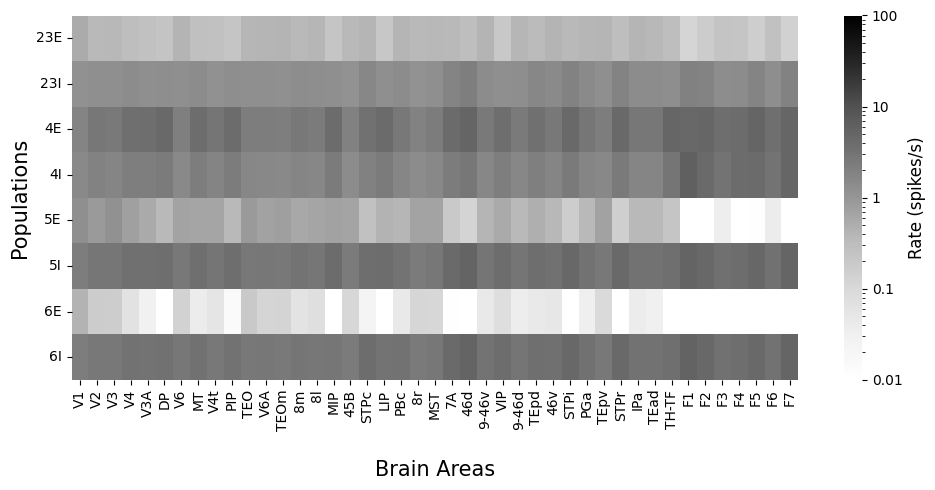

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors

# ------------------------------------------------------------------
# Extract mean rates from results
# ------------------------------------------------------------------
def extract_mean_matrix(results, area_list, population_list):
    matrix = np.zeros((len(population_list), len(area_list)))

    for i, pop in enumerate(population_list):
        for j, area in enumerate(area_list):
            try:
                matrix[i, j] = results[area][pop]['mean_rate_spikes_Hz']
            except KeyError:
                matrix[i, j] = 0.0

    return matrix

# ------------------------------------------------------------------
# Define axes
# ------------------------------------------------------------------
areas = ['V1', 'V2', 'V3', 'V4', 'V3A', 'DP', 'V6', 'MT', 'V4t', 
         'PIP', 'TEO', 'V6A', 'TEOm', '8m', '8l', 'MIP', 
         '45B', 'STPc', 'LIP', 'PBc', '8r', 'MST', '7A', 
         '46d', '9-46v', 'VIP', '9-46d', 'TEpd', '46v', 'STPi', 
         'PGa', 'TEpv', 'STPr', 'IPa', 'TEad', 'TH-TF',  
         'F1', 'F2','F3', 'F4', 'F5', 'F6', 'F7']

populations = ['23E', '23I', '4E', '4I', '5E', '5I', '6E', '6I']

# ------------------------------------------------------------------
# Plot heatmap with custom colormap and fixed value bounds
# ------------------------------------------------------------------
def plot_heatmap(results_dict, state_title, cmap_name='YlOrBr', show_annotations=True):

    matrix = extract_mean_matrix(results_dict, areas, populations)
    matrix_no_zeros = np.where(matrix <= 0, 1e-5, matrix)

    matrix_no_zeros = LA_matrix
    #plt.figure(figsize=(22, 6))
    plt.figure(figsize=(10, 5))

    # Select the colormap matching Option 1
    cmap = plt.get_cmap(cmap_name)
    
    # Keeping log normalization uniform across plots for easy comparison
    norm = mcolors.LogNorm(vmin=1e-2, vmax=100)

    ax = sns.heatmap(
        matrix_no_zeros,
        cmap=cmap,
        norm=norm,
        annot=show_annotations,
        fmt=".2f",
        xticklabels=areas,
        yticklabels=populations,
        #linewidths=0.5,
        #linecolor='grey'  # Softened line color for cleaner look
    )

    plt.yticks(rotation=0)
    plt.xlabel("\nBrain Areas", fontsize=15)
    plt.ylabel("Populations", fontsize=15)
    #plt.title(f"Mean Firing Rates (Hz) - {state_title} State\n", fontsize=16, fontweight='bold')

    # Colorbar formatting
    cbar = ax.collections[0].colorbar
    cbar.set_label("Rate (spikes/s)", fontsize=12)
    cbar.set_ticks([1e-2, 1e-1, 1, 10, 100])
    cbar.ax.set_yticklabels(['0.01', '0.1', '1', '10', '100'])

    plt.tight_layout()
    plt.savefig('output/Low_activity_state.png', dpi=300)
    plt.show()

# ------------------------------------------------------------------
# How to call for both states:
# ------------------------------------------------------------------

# 1. Low-Activity State Plot (Greys)
plot_heatmap(results, state_title="Low-Activity (LA)", show_annotations=False, cmap_name='Greys')

# 2. High-Activity State Plot (Orange/Amber)
#plot_heatmap(results, state_title="High-Activity (HA)", cmap_name='YlOrBr', show_annotations=False)

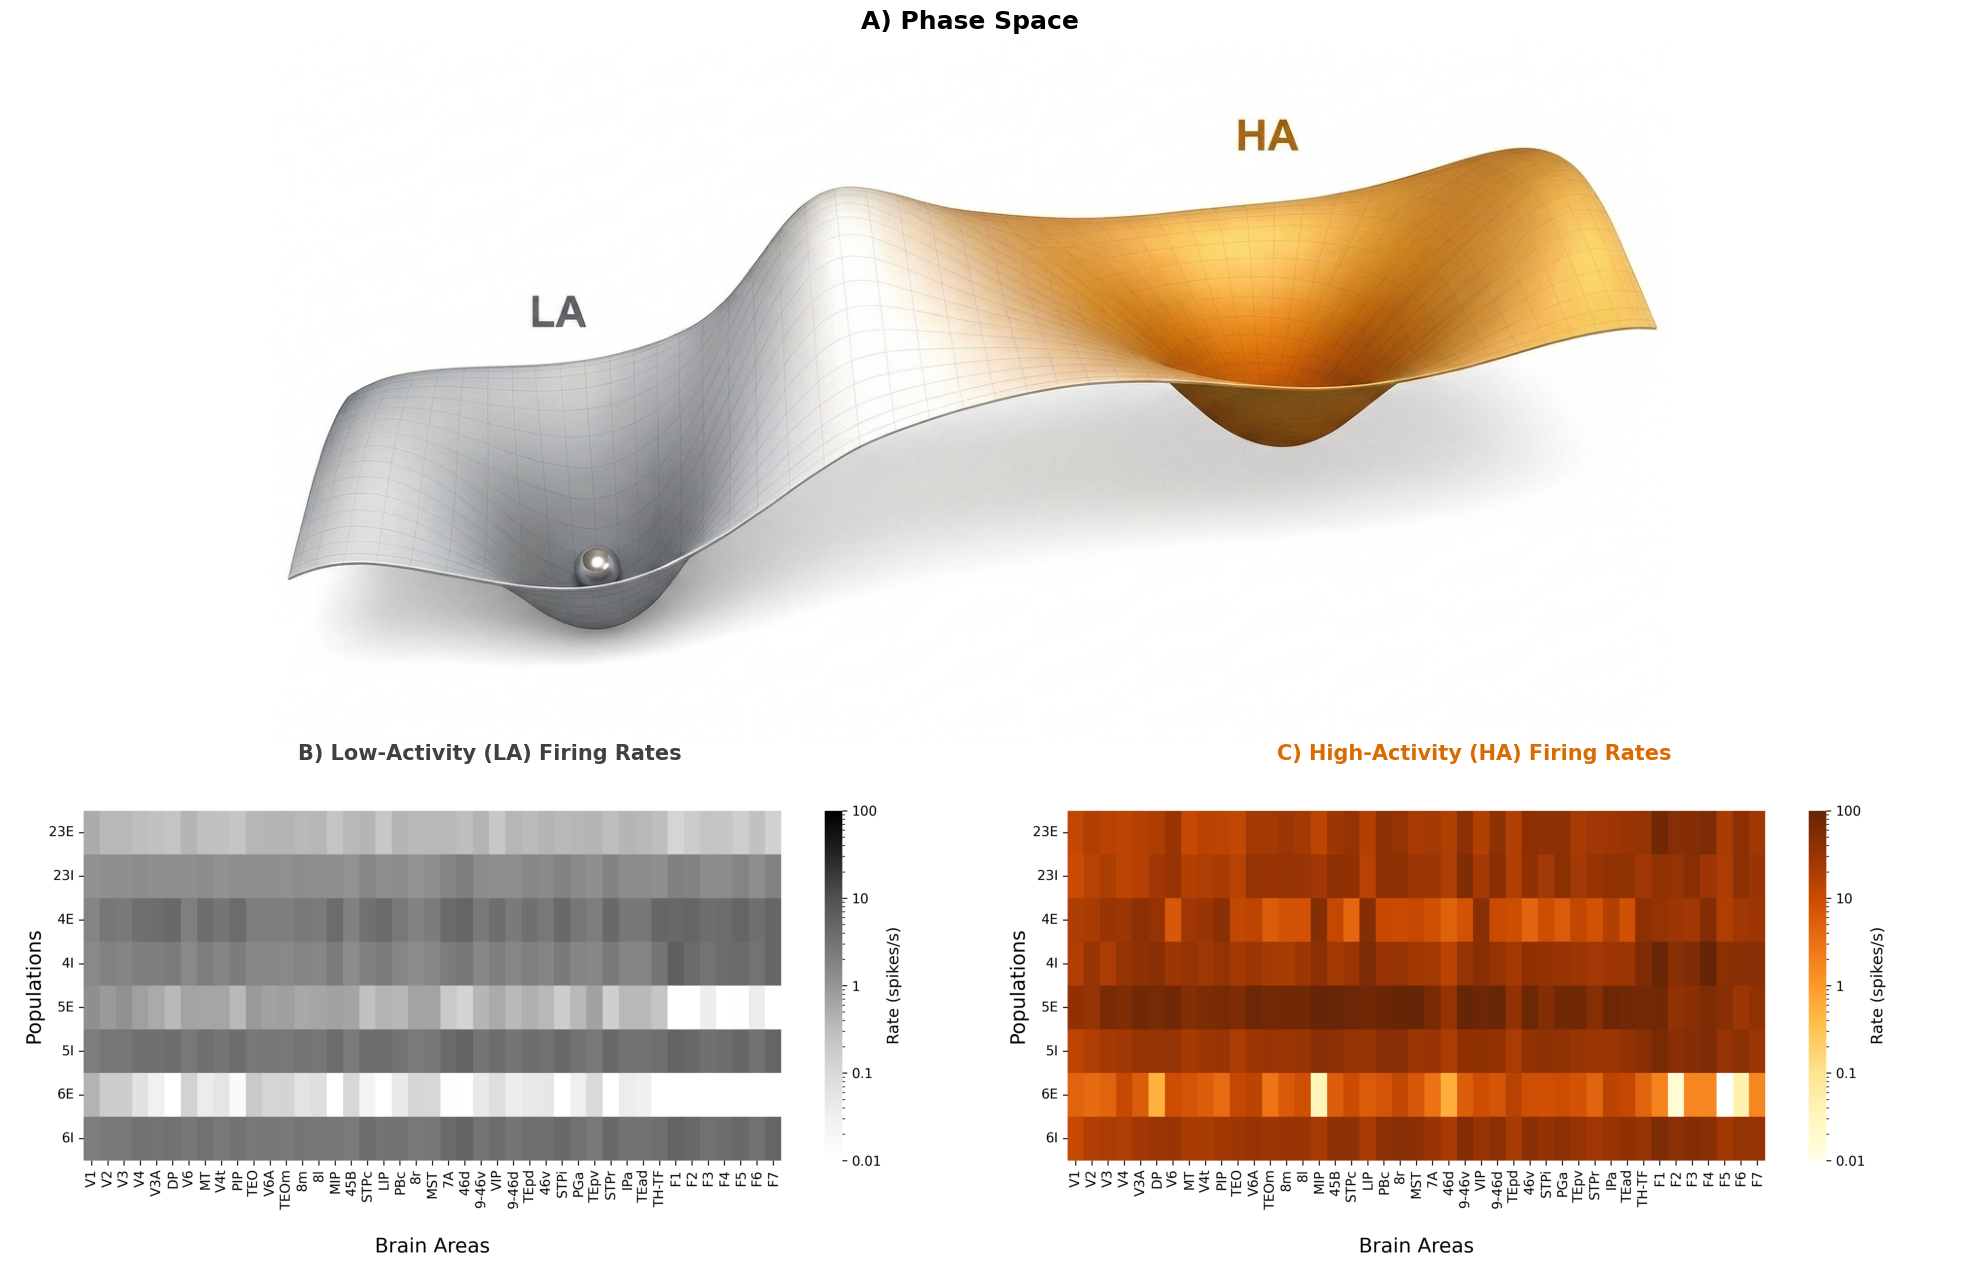

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# ==============================================================================
# ADJUSTMENT CONTROLS (Modify these parameters to fit your preference!)
# ==============================================================================

# 1. Phase Space Plot (Top Image)
TOP_HORIZ_SHIFT = 0.0    # Move right (+) or left (-)
TOP_WIDTH       = 0.90    # Width scaling (0.1 to 1.0)
TOP_HEIGHT      = 0.50    # Height scaling
TOP_BOTTOM_POS  = 0.45    # Vertical placement from bottom of canvas

# 2. Low Activity Heatmap (Bottom Left)
LA_LEFT_POS     = 0.1    # Left position
LA_BOTTOM_POS   = 0.05    # Vertical position
LA_WIDTH        = 0.40    # Width of heatmap
LA_HEIGHT       = 0.38    # Height of heatmap

# 3. High Activity Heatmap (Bottom Right)
HA_LEFT_POS     = 0.51    # Left position
HA_BOTTOM_POS   = 0.05    # Vertical position
HA_WIDTH        = 0.40    # Width of heatmap
HA_HEIGHT       = 0.38    # Height of heatmap

# ==============================================================================
# COMPOSITE PLOT GENERATION
# ==============================================================================

# Create base canvas
fig = plt.figure(figsize=(24, 14))

# ------------------------------------------------------------------
# TOP PANEL: Phase Space Diagram
# ------------------------------------------------------------------
# [left, bottom, width, height] in normalized figure coordinates (0 to 1)
ax_top_bounds = [0.05 + TOP_HORIZ_SHIFT, TOP_BOTTOM_POS, TOP_WIDTH, TOP_HEIGHT]
ax_top = fig.add_axes(ax_top_bounds)

phase_space_img = mpimg.imread('output/P1.png')
ax_top.imshow(phase_space_img)
ax_top.axis('off')
ax_top.set_title("A) Phase Space", fontsize=18, fontweight='bold', loc='center')

# ------------------------------------------------------------------
# BOTTOM LEFT PANEL: Low Activity (LA) Heatmap
# ------------------------------------------------------------------
ax_la_bounds = [LA_LEFT_POS, LA_BOTTOM_POS, LA_WIDTH, LA_HEIGHT]
ax_la = fig.add_axes(ax_la_bounds)

la_img = mpimg.imread('output/Low_activity_state.png')
ax_la.imshow(la_img)
ax_la.axis('off')
ax_la.set_title("B) Low-Activity (LA) Firing Rates\n", fontsize=15, fontweight='bold', color='#404040', loc='center')

# ------------------------------------------------------------------
# BOTTOM RIGHT PANEL: High Activity (HA) Heatmap
# ------------------------------------------------------------------
ax_ha_bounds = [HA_LEFT_POS, HA_BOTTOM_POS, HA_WIDTH, HA_HEIGHT]
ax_ha = fig.add_axes(ax_ha_bounds)

ha_img = mpimg.imread('output/High_activity_state.png')
ax_ha.imshow(ha_img)
ax_ha.axis('off')
ax_ha.set_title("C) High-Activity (HA) Firing Rates\n", fontsize=15, fontweight='bold', color='#D96B00', loc='center')

# ------------------------------------------------------------------
# SAVE HIGH RESOLUTION COMPOSITE PDF
# ------------------------------------------------------------------
plt.savefig('output/bistability.png', bbox_inches='tight', dpi=500)
plt.show()

In [ ]:
matrix.mean()

34.8124022621028

In [ ]:
1 = 35
2 = 37
3 = 33
4 = 1.852
5 = 36
6 = 1.850
7 = 1.853
8 = 1.852
9 = 1.851
10 = 1.853
11 = 1.852
12 = 36.76
13 = 1.852
14 = 1.852
15 = 1.853
16 = 1.853
17 = 1.850
18 = 1.851
19 = 1.853
20 = 34.799
21 = 1.853
22 = 1.851

SyntaxError: cannot assign to literal here. Maybe you meant '==' instead of '='? (4022840728.py, line 1)

In [ ]:
# ------------------------------------------------------------------
# Extract rates from results
# ------------------------------------------------------------------
def extract_mean_matrix(results, area_list, population_list):

    for i, pop in enumerate(population_list):
        for j, area in enumerate(area_list):
            try:
                matrix[i, j] = results[area][pop]["mean_rate_1"]
            except KeyError:
                matrix[i, j] = 0.0

    return matrix

In [24]:
def Mean_Rate_comparison(Rates_1, Neurons_List, Rates_2=None, compare=False, values=False, data = False, Title='Comparison of Stimulated and Non-Stimulated Average Firing Rates Across Layers'):
    """
    Function to visualize the mean firing rate of neurons across layers.
    
    Parameters:
    - Rates_1: Firing rates for the first group (stimulated).
    - Rates_2: Firing rates for the second group (non-stimulated). Optional if compare=False.
    - Neurons_List: List of neuron layers (used for labeling).
    - compare: If True, compare both stimulated (Rates_1) and non-stimulated (Rates_2).
    - values: If True, print the table of mean and std values.
    - Title: Title for the plot.  (You can choose your own title)
    """
    
    # Combine data for all layers into one list each for stimulated and non-stimulated
    stimulated_rates = [np.mean(Rates_1[i]) for i in range(8)]
    stimulated_stds = [np.std(Rates_1[i]) for i in range(8)]

    #stimulated_rates = Rates_1
    #stimulated_stds = np.zeros(8)

    

    if compare and Rates_2 is not None:
        non_stimulated_rates = [np.mean(Rates_2[i][2500:]) for i in range(8)]
        non_stimulated_stds = [np.std(Rates_2[i][2500:]) for i in range(8)]
    
    # Print Table of values if requested
    if values:
        # Print table headers
        print(f"{'Neuron Layer':<15}{'Stimulated Mean':<20}{'Stimulated Std':<20}")
        if compare and Rates_2 is not None:
            print(f"{'Non-Stimulated Mean':<25}{'Non-Stimulated Std':<20}")
        print("-" * 100)
    
        
        # Iterate through the neuron layers and print each layer's values
        for i in range(8):
            row = f"{Neurons_List[i]:<15}{stimulated_rates[i]:<20.4f}{stimulated_stds[i]:<20.4f}"
            if compare and Rates_2 is not None:
                row += f"{non_stimulated_rates[i]:<25.4f}{non_stimulated_stds[i]:<20.4f}"
            print(row)

    # Create a plot for the firing rates
    fig, ax = plt.subplots(figsize=(10, 5))
    
    # Set the width of the bars
    bar_width = 0.35
    index = np.arange(len(stimulated_rates))

    if compare and Rates_2 is not None:
        # Plot both stimulated and non-stimulated rates
        bars1 = ax.bar(index, stimulated_rates, bar_width, color='mediumblue', label='Stimulated', yerr=stimulated_stds, capsize=5)
        bars2 = ax.bar(index + bar_width, non_stimulated_rates, bar_width, color='crimson', label='Non-stimulated', yerr=non_stimulated_stds, capsize=5)

        # Adding text labels on the bars
        for bar in bars1:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width() / 2.0, height,
                    f'{height:.2f}', ha='center', va='bottom', color='blue', fontsize=10, fontweight='bold')

        for bar in bars2:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width() / 2.0, height,
                    f'{height:.2f}', ha='center', va='bottom', color='red', fontsize=10, fontweight='bold')
    
    else:
        # Plot only the stimulated rates with different colors for even and odd indices
        colors = ['steelblue' if i % 2 == 0 else 'lightcoral' for i in range(len(stimulated_rates))]
        bars1 = ax.bar(index, stimulated_rates, bar_width, color=colors, yerr=stimulated_stds, capsize=5)
        
        # Adding text labels on the bars
        for bar in bars1:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width() / 2.0, height,
                    f'{height:.2f}', ha='center', va='bottom', color='black', fontsize=10, fontweight='bold')

    # Adding titles and labels
    ax.set_title(Title)
    ax.set_xlabel('Population', fontsize = 12)
    ax.set_ylabel('Firing rates (spikes/s)', fontsize = 12)
    ax.set_xticks(index + (bar_width / 2 if compare and Rates_2 is not None else 0))
    ax.set_xticklabels(Neurons_List, rotation=0)
    ax.legend()
    ax.grid(alpha = 0.4)

    # Adjust layout for better spacing
    plt.tight_layout()
    
    # Save figure with title in the filename if custom title is provided
   # if Title != 'Comparison of Stimulated and Non-Stimulated Average Firing Rates Across Layers':
   #     plt.savefig(f"{Title}.png", format='png')
   #     #print("Hello World")
    
    plt.show()
    if data:
        print(f'Mean Firing rates across pops = {stimulated_rates}', '\n', f'Standarad deviation of Firing rates across pops = {stimulated_stds}')
        



In [ ]:
np.max(matrix)

5.950162845698868

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


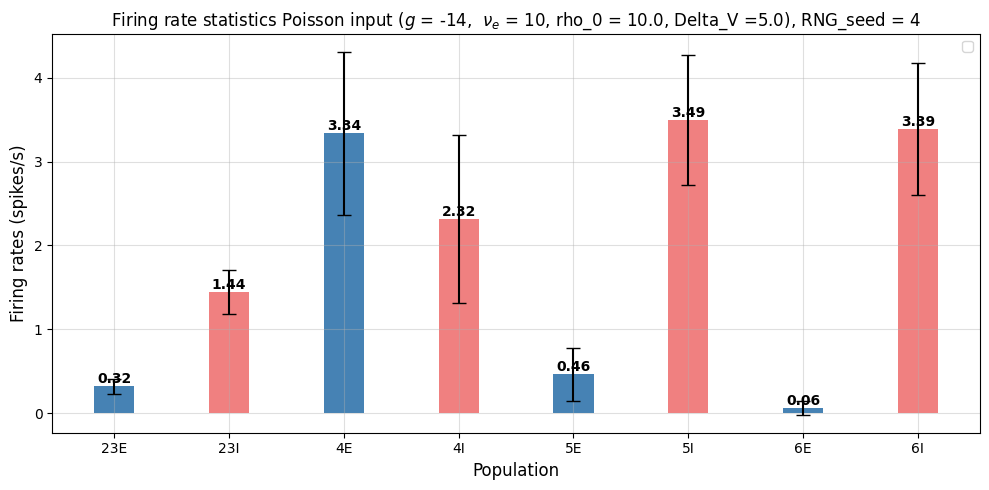

Mean Firing rates across pops = [0.3223847821019665, 1.4407426753969117, 3.335631110124828, 2.3159153703287, 0.4615930572947318, 3.493428286089803, 0.06118869474811159, 3.3866388909010268] 
 Standarad deviation of Firing rates across pops = [0.09037150938614819, 0.2630622784039275, 0.9751171758759712, 0.9966695170713864, 0.3117158725374764, 0.7777818245840334, 0.07809285692409895, 0.7868084316937581]


In [25]:

population_list = ['23E', '23I', '4E', '4I', '5E', '5I', '6E', '6I']


Mean_Rate_comparison(matrix, population_list, data=True, Title=f'Firing rate statistics Poisson input ($g$ = {g},  $ \\nu_e$ = 10, rho_0 = {rho_0}, Delta_V ={Delta_V}), RNG_seed = {seed_val}')

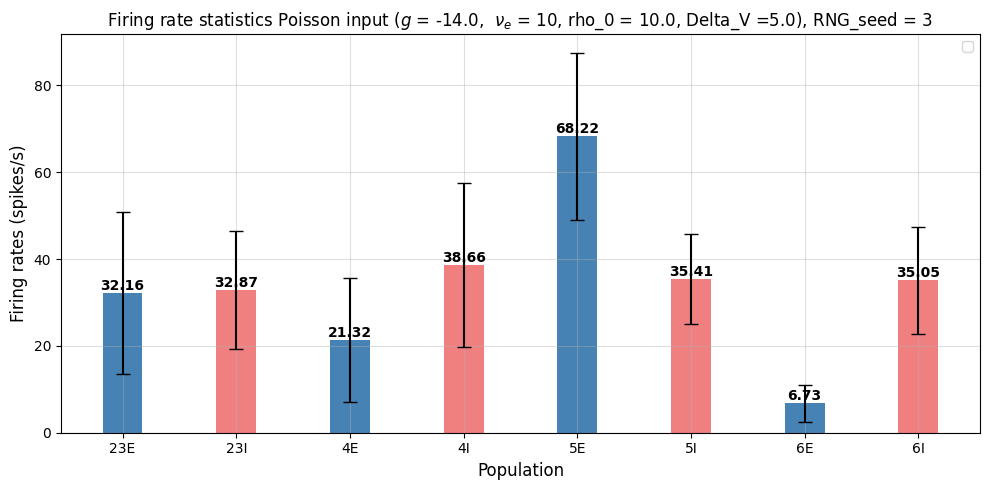

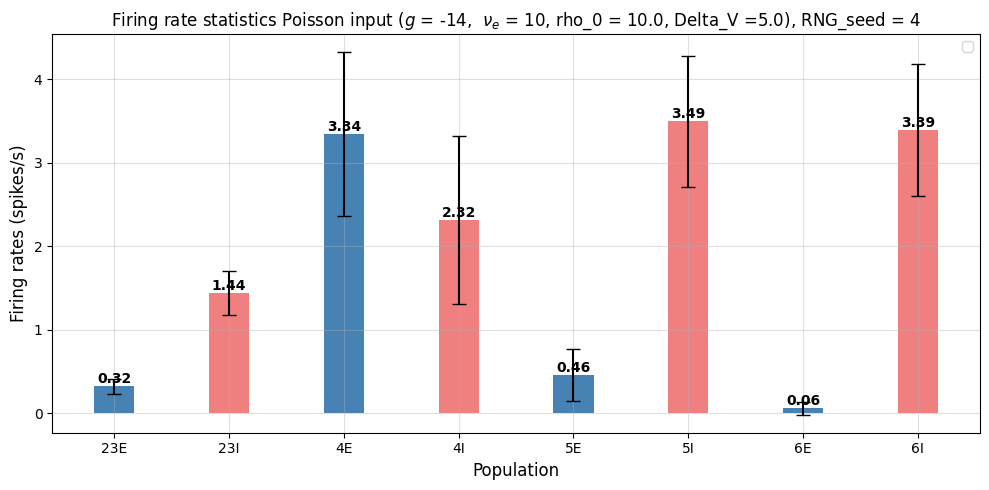

In [26]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np

def Mean_Rate_comparison_2(Rates_1, Neurons_List, Rates_2=None, compare=False,
                          values=False, data=False, log_scale=False, plot_type='bar',
                          Title='Mean firing rate across populations, averaged over areas'):
    """
    plot_type: 'bar' (mean +/- SD bars) or 'box' (boxplot showing full distribution across areas)
    """
    stimulated_rates = np.array([np.mean(Rates_1[i]) for i in range(8)])
    stimulated_stds = np.array([np.std(Rates_1[i]) for i in range(8)])
    median_data = np.array([np.median(Rates_1[i]) for i in range(8)])
    if compare and Rates_2 is not None:
        non_stimulated_rates = np.array([np.mean(Rates_2[i][2500:]) for i in range(8)])
        non_stimulated_stds = np.array([np.std(Rates_2[i][2500:]) for i in range(8)])

    if values:
        print(f"{'Population':<12}{'Mean (sp/s)':<15}{'SD (sp/s)':<15}")
        print("-" * 42)
        for i in range(8):
            print(f"{Neurons_List[i]:<12}{stimulated_rates[i]:<15.4f}{stimulated_stds[i]:<15.4f}")

    fig, ax = plt.subplots(figsize=(12, 7))
    bar_width = 0.35
    index = np.arange(8)
    is_excitatory = np.array(['E' in pop for pop in Neurons_List])
    colors = np.where(is_excitatory, 'steelblue', 'lightcoral')

    if plot_type == 'box':
        box_data = [Rates_1[i] for i in range(8)]
        bp = ax.boxplot(box_data, positions=index, widths=0.5, patch_artist=True,
                         showmeans=True, meanprops={'marker':'D','markerfacecolor':'Yellow',
                                                     'markeredgecolor':'black','markersize':6},
                         medianprops={'color':'black','linewidth':1.2},
                         flierprops={'marker':'x','markersize':5,'markerfacecolor':'gray','alpha':0.6})
        for patch, c in zip(bp['boxes'], colors):
            patch.set_facecolor(c)
            patch.set_alpha(0.75)
        # overlay individual area points with jitter
        rng = np.random.default_rng(1)
        for i in range(8):
            jitter = rng.uniform(-0.12, 0.12, size=len(Rates_1[i]))
            #ax.scatter(index[i] + jitter, Rates_1[i], marker = '.',color='black', s=15, alpha=0.3, zorder=3)
        legend_handles = [Patch(color='steelblue', label='Excitatory'),
                           Patch(color='lightcoral', label='Inhibitory'),
                           plt.Line2D([0],[0], marker='D', color='w', markerfacecolor='Yellow', markeredgecolor='black',
                                      markersize=6, label='Mean')]
                           #plt.Line2D([0],[0], marker='o', color='w', markerfacecolor='black',
                           #           markersize=5, alpha=0.6, label='Individual areas')]
        ax.legend(handles=legend_handles, frameon=True,fontsize=11, loc='upper left')
        xticks_pos = index

    else:  # bar
        if compare and Rates_2 is not None:
            bars1 = ax.bar(index, stimulated_rates, bar_width, color='mediumblue',
                            label='Stimulated', yerr=stimulated_stds, capsize=4,
                            error_kw={'elinewidth': 1, 'alpha': 0.7})
            bars2 = ax.bar(index + bar_width, non_stimulated_rates, bar_width, color='crimson',
                            label='Non-stimulated', yerr=non_stimulated_stds, capsize=4,
                            error_kw={'elinewidth': 1, 'alpha': 0.7})
            for bars, col in [(bars1, 'blue'), (bars2, 'red')]:
                for bar in bars:
                    h = bar.get_height()
                    ax.text(bar.get_x() + bar.get_width()/2, h, f'{h:.2f}',
                            ha='center', va='bottom', color=col, fontsize=9, fontweight='bold')
            ax.legend(frameon=False)
            xticks_pos = index + bar_width/2
        else:
            bars1 = ax.bar(index, stimulated_rates, bar_width, color=colors,
                            yerr=stimulated_stds, capsize=4,
                            error_kw={'elinewidth': 1, 'alpha': 0.7})
            for bar in bars1:
                h = bar.get_height()
                ax.text(bar.get_x() + bar.get_width()/2, h, f'{h:.2f}',
                        ha='center', va='bottom', color='black', fontsize=9, fontweight='bold')
            ax.legend(handles=[Patch(color='steelblue', label='Excitatory'),
                                Patch(color='lightcoral', label='Inhibitory')], frameon=False)
            xticks_pos = index

    # Layer grouping labels
    #layer_groups = [('L2/3', 0, 1), ('L4', 2, 3), ('L5', 4, 5), ('L6', 6, 7)]
    #ymax = ax.get_ylim()[1]
    #for name, i0, i1 in layer_groups:
    #    xpos = (xticks_pos[i0] + xticks_pos[i1]) / 2
    #    ax.text(xpos, -0.08, name, ha='center', va='top', fontsize=10, fontweight='bold',
    #           transform=ax.get_xaxis_transform())

    if log_scale:
        ax.set_yscale('log')
        ax.set_ylabel('Firing rate (spikes/s, log scale)', fontsize=14)
    else:
        ax.set_ylabel('Firing rate (spikes/s)', fontsize=14)

    #ax.set_title(Title, fontsize=12)
    ax.set_xlabel('Population', fontsize=14, labelpad=20)
    ax.set_xticks(xticks_pos)
    ax.set_xticklabels(Neurons_List, rotation=0)
    ax.grid(alpha=0.3, axis='y')
    ax.set_axisbelow(True)
    #cap = 'Boxplots show median, IQR, and range across areas; diamonds = mean' if plot_type=='box' else 'Error bars: SD across areas'
    #plt.figtext(0.5, -0.03, cap, ha='center', fontsize=9, style='italic')

    plt.tight_layout()
    plt.savefig('mean_rate_boxplot_mesoscopic_HA.eps', dpi=200, bbox_inches='tight')
    plt.show()
    plt.close()

    if data:
        print(f'Mean Firing rates across pops = {stimulated_rates.tolist()}')
        print(f'Standard deviation across pops = {stimulated_stds.tolist()}')
        print(f'Median data across pops = {median_data.tolist()}')



The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


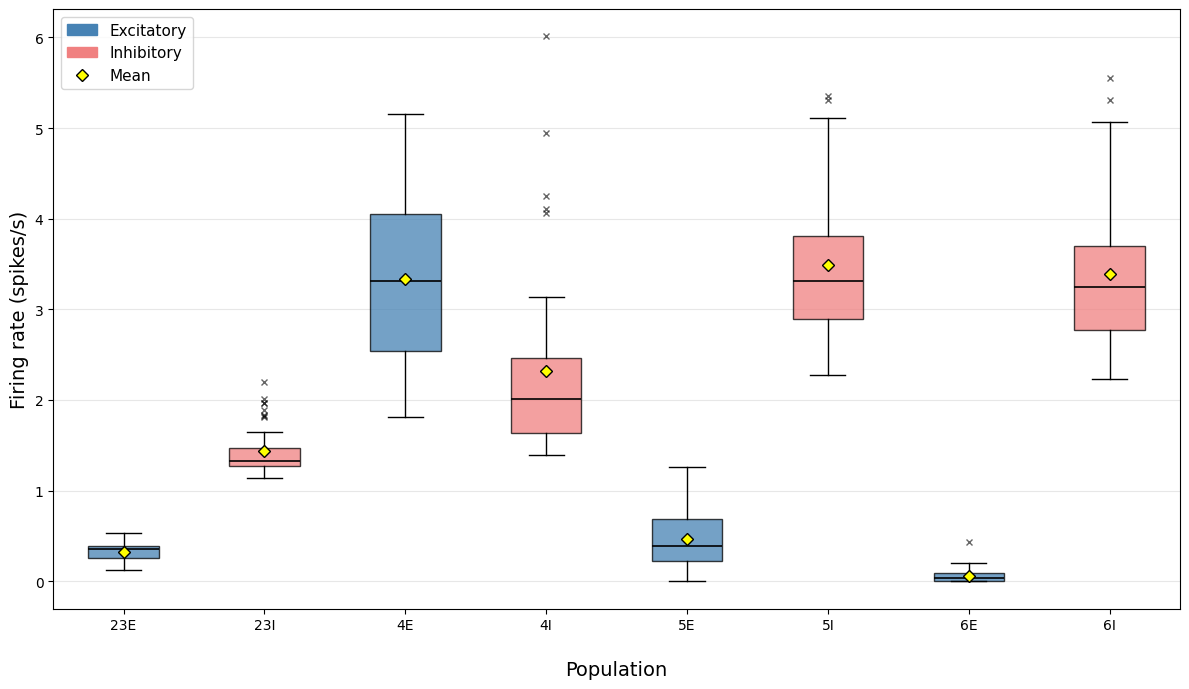

Mean Firing rates across pops = [0.3223847821019665, 1.4407426753969117, 3.335631110124828, 2.3159153703287, 0.4615930572947318, 3.493428286089803, 0.06118869474811159, 3.3866388909010268]
Standard deviation across pops = [0.09037150938614819, 0.2630622784039275, 0.9751171758759712, 0.9966695170713864, 0.3117158725374764, 0.7777818245840334, 0.07809285692409895, 0.7868084316937581]
Median data across pops = [0.3562843878802597, 1.3256861664190023, 3.315006229026466, 2.0059283208846574, 0.3931440380224205, 3.3104088320187484, 0.03970030627717306, 3.243082145164013]


In [27]:
Mean_Rate_comparison_2(matrix, population_list, plot_type='box',
                      Title='Mean firing rate across populations, averaged over areas (F1-F7)', data=True)

# Or keep the original bar chart:
#Mean_Rate_comparison(Rates_1, population_list, plot_type='bar', log_scale=True)

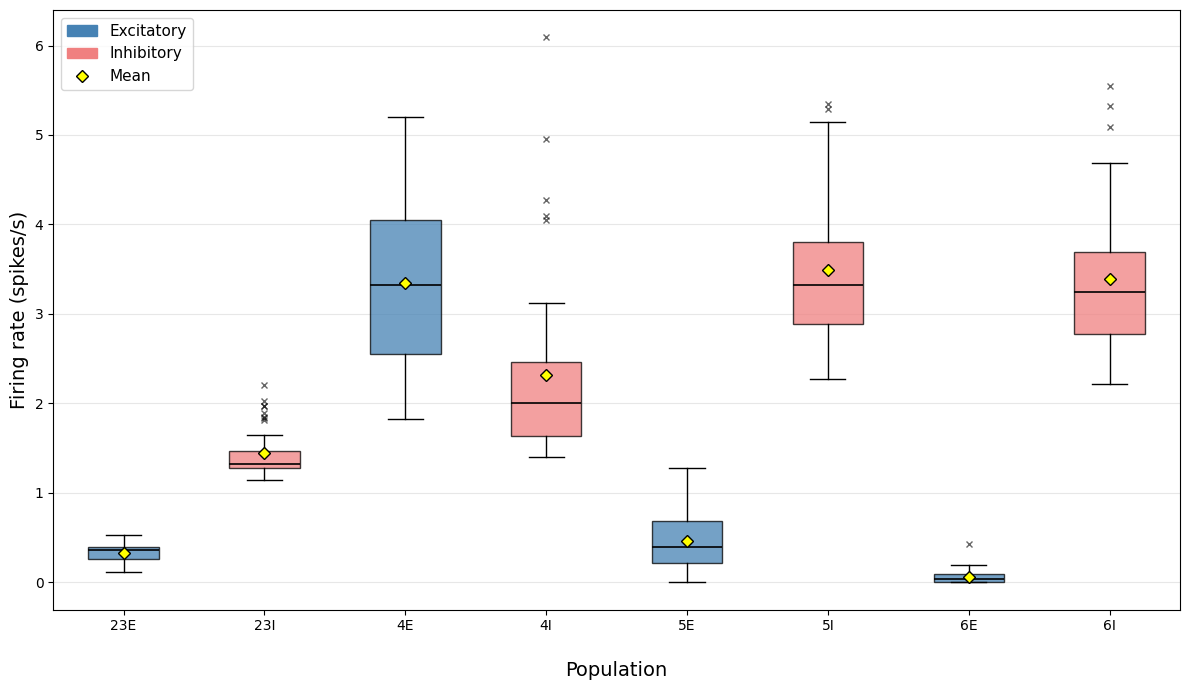

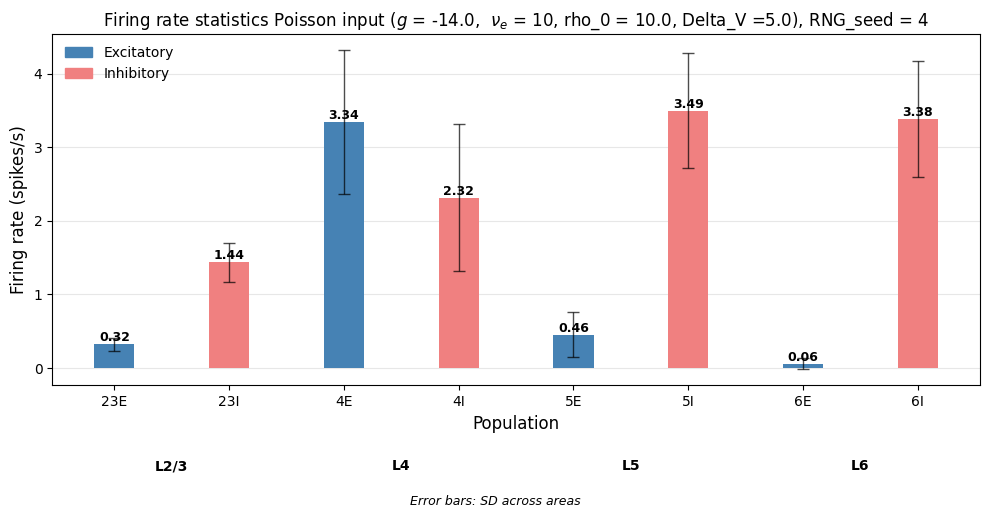

Mean Firing rates across pops = [0.3226030734628244, 1.4379259949367245, 3.3430412012837287, 2.3165664301492366, 0.4559564086036912, 3.494716665499464, 0.0591411137108798, 3.3848513630089445]
Standard deviation across pops = [0.08932024051314603, 0.26551606733092253, 0.9822359340832635, 0.9971639906937008, 0.3071139503954337, 0.7778154055691209, 0.07532436292538798, 0.7888638273645849]


In [ ]:
Mean_Rate_comparison(matrix, population_list, data=True, Title=f'Firing rate statistics Poisson input ($g$ = {g},  $ \\nu_e$ = 10, rho_0 = {rho_0}, Delta_V ={Delta_V}), RNG_seed = {seed_val}')


In [26]:
def Mean_Rate_comparison(Rates_1, Neurons_List, Rates_2=None, area = 'F1', compare=False, values=False, data = False, Title='Comparison of Stimulated and Non-Stimulated Average Firing Rates Across Layers'):
    """
    Function to visualize the mean firing rate of neurons across layers.
    
    Parameters:
    - Rates_1: Firing rates for the first group (stimulated).
    - Rates_2: Firing rates for the second group (non-stimulated). Optional if compare=False.
    - Neurons_List: List of neuron layers (used for labeling).
    - compare: If True, compare both stimulated (Rates_1) and non-stimulated (Rates_2).
    - values: If True, print the table of mean and std values.
    - Title: Title for the plot.  (You can choose your own title)
    """
    
    # Combine data for all layers into one list each for stimulated and non-stimulated
    stimulated_rates = [np.mean(Rates_1[area][i]['rate_from_mean'][100:]) for i in Neurons_List]
    stimulated_stds = [np.std(Rates_1[area][i]['rate_from_mean'][100:]) for i in Neurons_List]

    #stimulated_rates = Rates_1
    #stimulated_stds = np.zeros(8)

    

    if compare and Rates_2 is not None:
        non_stimulated_rates = [np.mean(Rates_2[i]) for i in range(8)]
        non_stimulated_stds = [np.std(Rates_2[i]) for i in range(8)]
    
    # Print Table of values if requested
    if values:
        # Print table headers
        print(f"{'Neuron Layer':<15}{'Stimulated Mean':<20}{'Stimulated Std':<20}")
        if compare and Rates_2 is not None:
            print(f"{'Non-Stimulated Mean':<25}{'Non-Stimulated Std':<20}")
        print("-" * 100)
    
        
        # Iterate through the neuron layers and print each layer's values
        for i in range(8):
            row = f"{Neurons_List[i]:<15}{stimulated_rates[i]:<20.4f}{stimulated_stds[i]:<20.4f}"
            if compare and Rates_2 is not None:
                row += f"{non_stimulated_rates[i]:<25.4f}{non_stimulated_stds[i]:<20.4f}"
            print(row)

    # Create a plot for the firing rates
    fig, ax = plt.subplots(figsize=(10, 5))
    
    # Set the width of the bars
    bar_width = 0.35
    index = np.arange(len(stimulated_rates))

    if compare and Rates_2 is not None:
        # Plot both stimulated and non-stimulated rates
        #bars1 = ax.bar(index, stimulated_rates, bar_width, color='steelblue', label='Stimulated', yerr=stimulated_stds, capsize=5)
        #bars2 = ax.bar(index + bar_width, non_stimulated_rates, bar_width, color='lightcoral', label='Non-stimulated', yerr=non_stimulated_stds, capsize=5)

        ## Adding text labels on the bars
        #for bar in bars1:
        #    height = bar.get_height()
        #    ax.text(bar.get_x() + bar.get_width() / 2.0, height,
        #            f'{height:.2f}', ha='center', va='bottom', color='blue', fontsize=10, fontweight='bold')

        #for bar in bars2:
        #    height = bar.get_height()
        #    ax.text(bar.get_x() + bar.get_width() / 2.0, height,
        #            f'{height:.2f}', ha='center', va='bottom', color='red', fontsize=10, fontweight='bold')
    

        # Plot only the stimulated rates with different colors for even and odd indices
        colors_1 = ['cornflowerblue' if i % 2 == 0 else 'lightcoral' for i in range(len(stimulated_rates))]
        colors_2 = ['steelblue' if i % 2 == 0 else 'indianred' for i in range(len(stimulated_rates))]
        label_1 = ['E_sim' if i % 2 == 0 else 'I_sim' for i in range(len(stimulated_rates))]
        label_2 = ['E_lit' if i % 2 == 0 else 'I_lit' for i in range(len(stimulated_rates))]

        bars1 = ax.bar(index, stimulated_rates, bar_width, color=colors_1, yerr=stimulated_stds, capsize=5, label = 'Simulation')
        bars2 = ax.bar(index + bar_width, non_stimulated_rates, bar_width, color=colors_2, label= 'Literature', yerr=non_stimulated_stds, capsize=5)
        
        # Adding text labels on the bars
        for bar in bars1:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width() / 2.0, height,
                    f'{height:.2f}', ha='center', va='bottom', color='black', fontsize=10, fontweight='bold')

        for bar in bars2:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width() / 2.0, height,
                    f'{height:.2f}', ha='center', va='bottom', color='black', fontsize=10, fontweight='bold')

        
    else:
        # Plot only the stimulated rates with different colors for even and odd indices
        colors = ['steelblue' if i % 2 == 0 else 'lightcoral' for i in range(len(stimulated_rates))]
        bars1 = ax.bar(index, stimulated_rates, bar_width, color=colors, yerr=stimulated_stds, capsize=5)
        
        # Adding text labels on the bars
        for bar in bars1:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width() / 2.0, height,
                    f'{height:.2f}', ha='center', va='bottom', color='black', fontsize=10, fontweight='bold')

    # Adding titles and labels
    ax.set_title(Title)
    ax.set_xlabel('Rate units', fontsize = 13)
    ax.set_ylabel('Average Rate (spikes/s)', fontsize = 13)
    ax.set_xticks(index + (bar_width / 2 if compare and Rates_2 is not None else 0))
    ax.set_xticklabels(Neurons_List, rotation=0)
    ax.legend(loc = 'upper left')
    ax.grid(alpha = 0.4)

    # Adjust layout for better spacing
    plt.tight_layout()
    
    # Save figure with title in the filename if custom title is provided
    if Title != 'Comparison of Stimulated and Non-Stimulated Average Firing Rates Across Layers':
        plt.savefig(f"{Title}.png", format='png')
        #print("Hello World")
    
    plt.show()
    if data:
        return stimulated_rates



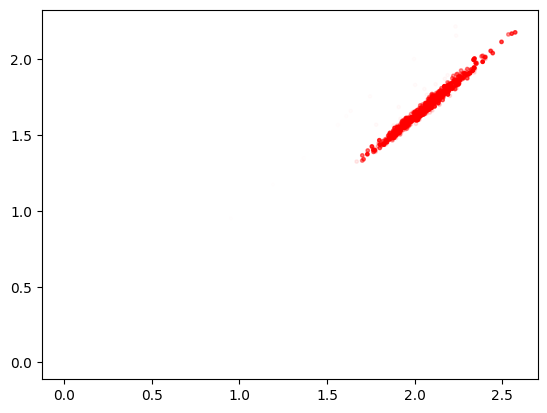

In [ ]:
t = np.arange(0, 699, 1)

r1 = results['V1']['4E']['rate_from_mean']
r2 = results['V1']['4I']['rate_from_mean']
# make a color map to visualize time
timecolors = np.array([(1 , 0 , 0, i)  for i in t / t[-1]])

plt.scatter(r1, r2, color = timecolors, s=6)
#plt.plot(r1[0,0], r2[1,0], 'bx')
#plt.semilogx()
#plt.semilogy()
#plt.xlim(1.7, 2.6)
#plt.ylim(1.2, 2.3)

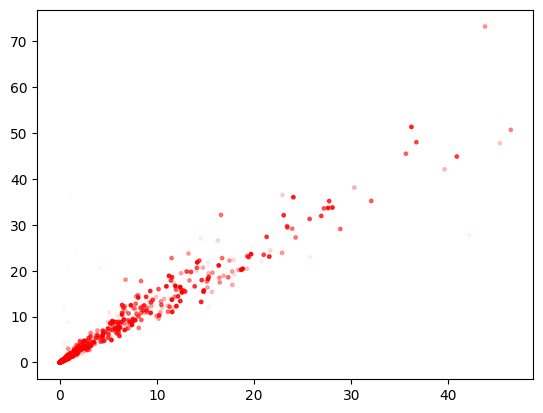

In [ ]:
list_area = ['V1', 'V2', 'DP', '46v', '7A', 'F1']

mean_activities = np.zeros((len(list_area), len(population_list)))


for i, area in enumerate(list_area):
    for j, pop in enumerate(population_list):
        mean_activities[i][j] = results[area][pop]['mean_rate_spikes_Hz']


In [ ]:
Vals = np.zeros(len(list_area))
for i in range(len(list_area)):
    Vals[i] = np.mean(mean_activities[i])

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


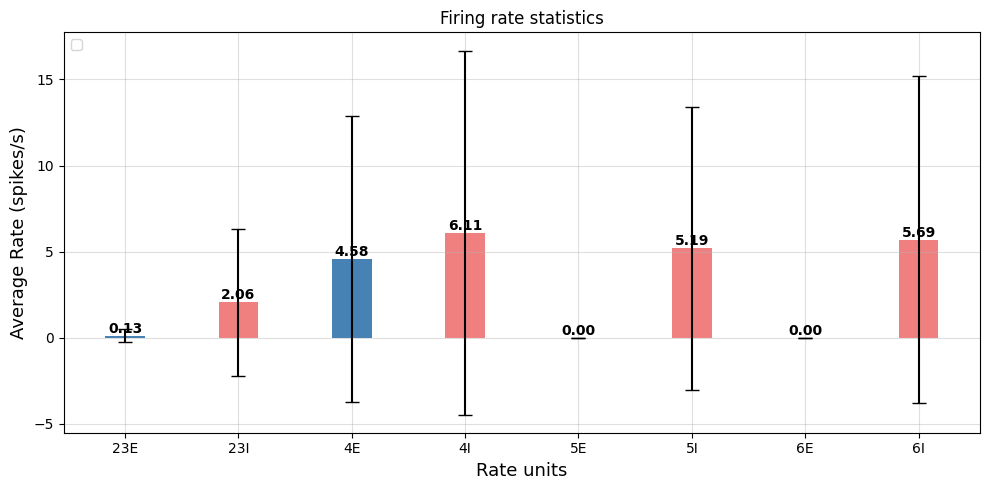

In [27]:


#Rates_1 = Simulation_2[0]['Rates']
#times = Simulation_2[0]['times']
#Neurons_List = Simulation_2[0]['Neurons'][0:8]
#

Mean_Rate_comparison(Rates_1=results, area='F1', Neurons_List=population_list, Title='Firing rate statistics')

In [ ]:
neuron_numbers['F1']

{'23E': 8054.203541002283,
 '23I': 2271.8282385634243,
 '4E': 5800.1368076045355,
 '4I': 1450.100368189151,
 '5E': 15870.52261436963,
 '5I': 3484.970429753331,
 '6E': 11336.249669460385,
 '6I': 2321.588331057258,
 'total': 50589.600000000006}

In [ ]:
{'23E': 8054.203541002283,
 '23I': 2271.8282385634243,
 '4E': 5800.1368076045355,
 '4I': 1450.100368189151,
 '5E': 15870.52261436963,
 '5I': 3484.970429753331,
 '6E': 11336.249669460385,
 '6I': 2321.588331057258,
 'total': 50589.600000000006}

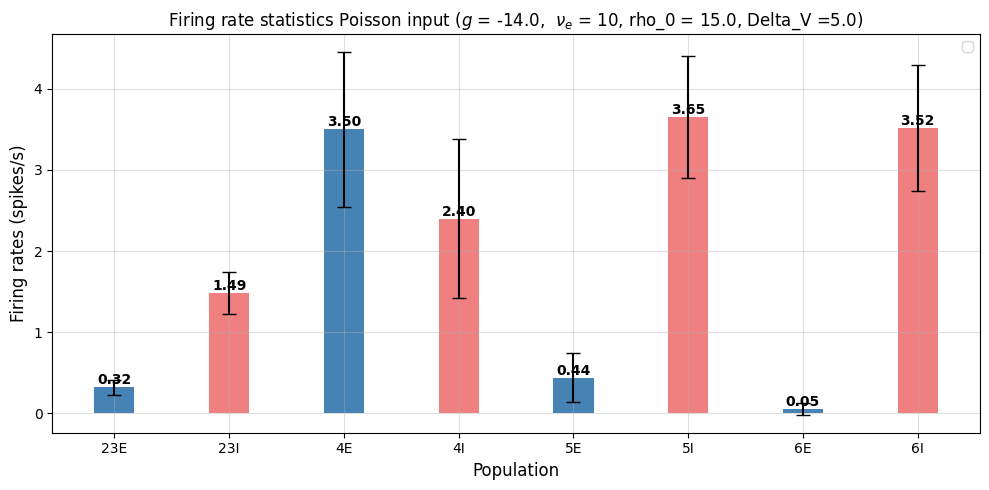

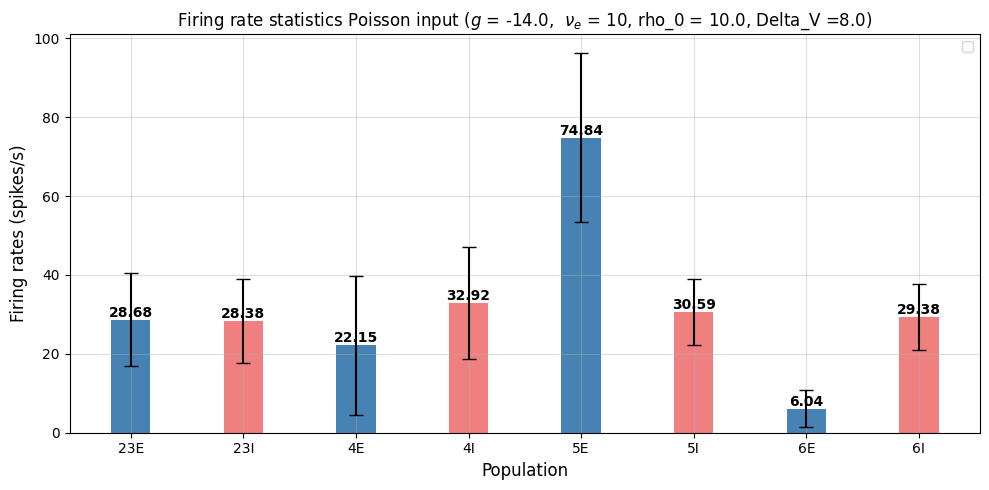

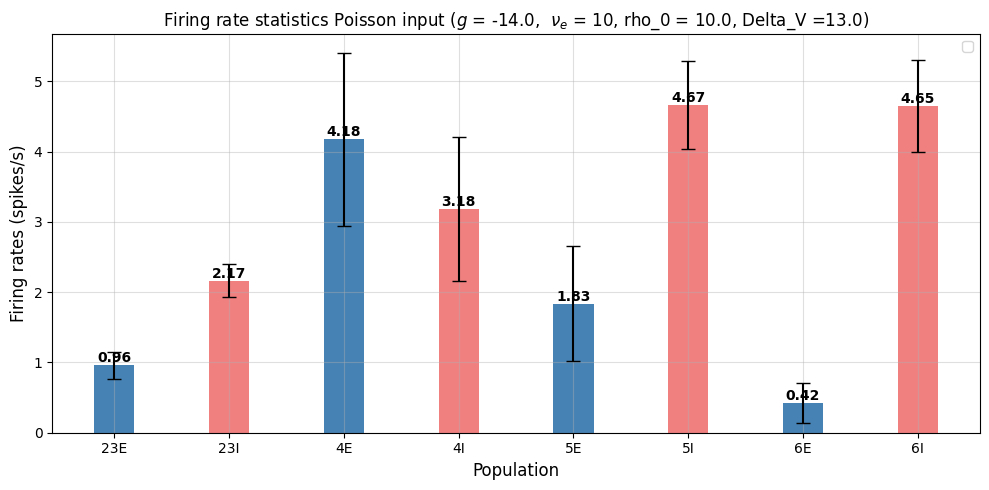

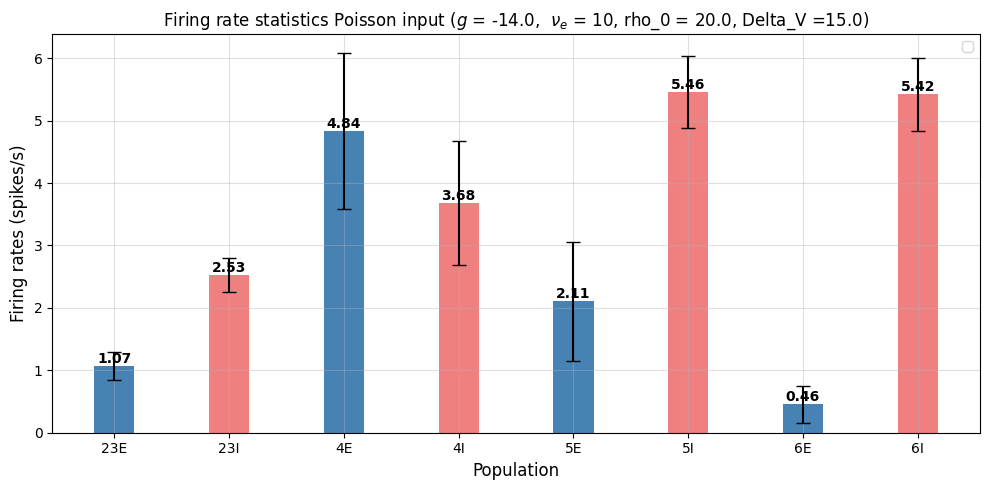

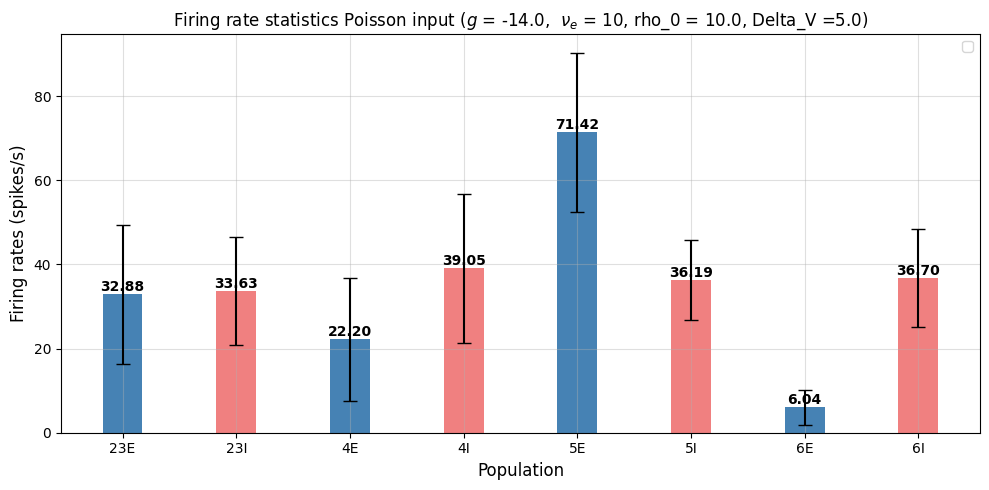

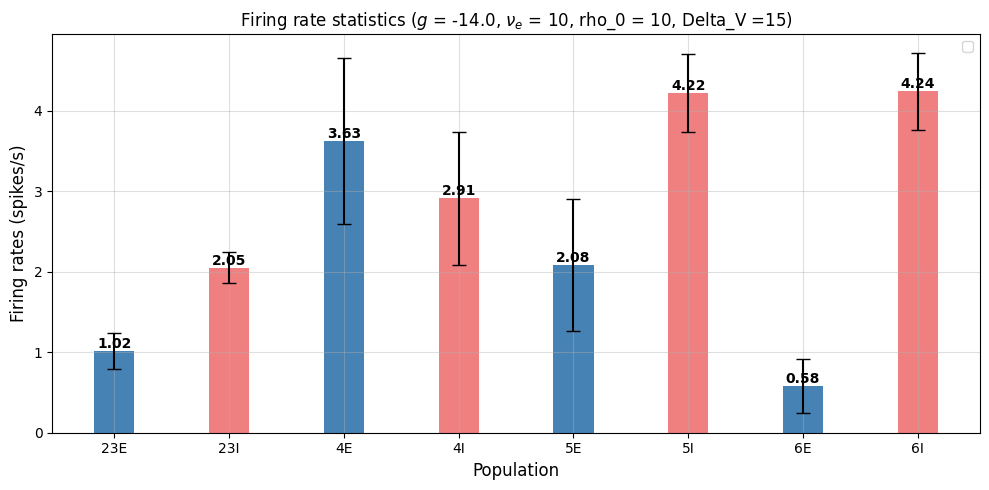

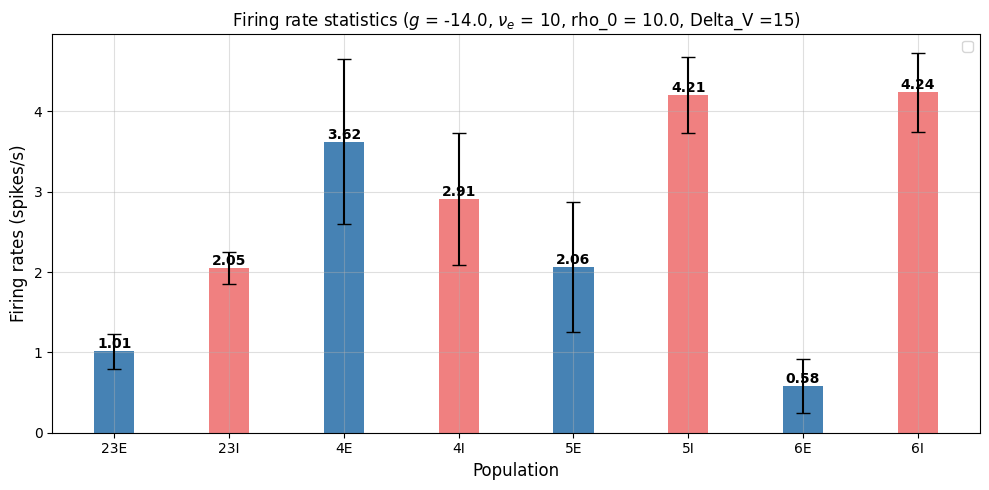

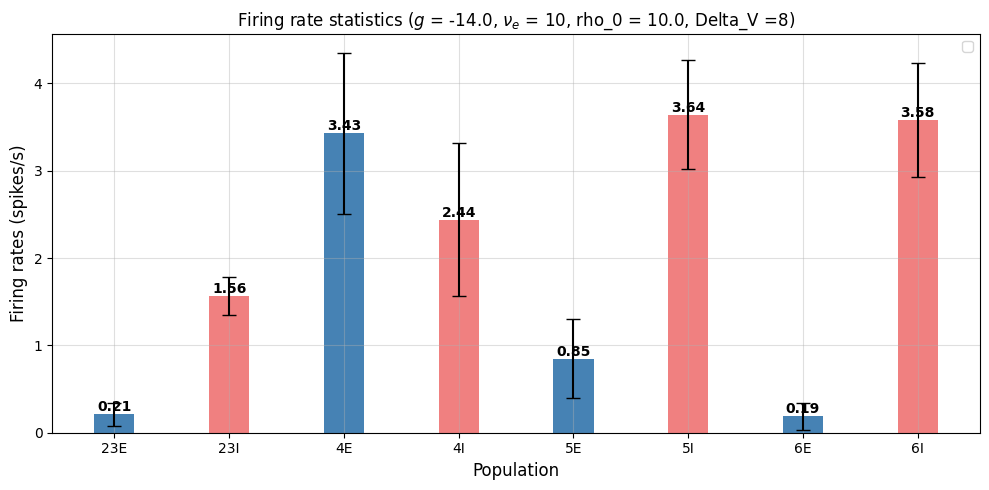

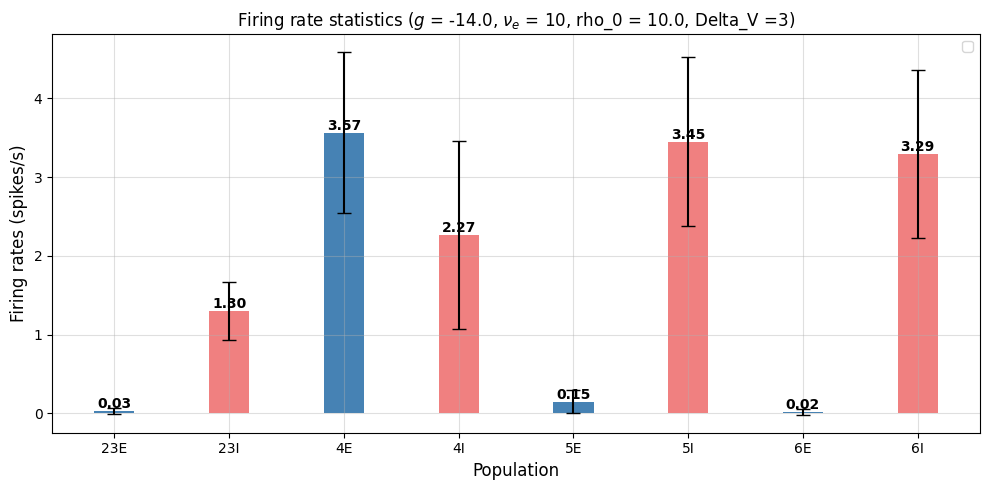

In [ ]:
# Rate_dynamics

def plot_rate_dynamics(firing_rates_dictionary, times, areas, pops, title = 'Rate Dynamics', figure_size=(18,6)):
    """
    Plot rate dynamics for specified areas and populations.

    Parameters:
    ----------
    firing_rates_dictionary : dict
        Dictionary with structure firing_rates_dictionary[area][pop]
    times : array-like
        Time vector corresponding to rate data
    gain, beta, theta : float
        Parameters for sigmoidal transfer function
    areas : str or list of str
        One or more area names to include
    pops : str or list of str
        One or more population names to include
    """
    if isinstance(areas, str):
        areas = [areas]
    if isinstance(pops, str):
        pops = [pops]

    plt.figure(figsize=figure_size)

    for area in areas:
        for pop in pops:
            if area in firing_rates_dictionary and pop in firing_rates_dictionary[area]:
                rate = firing_rates_dictionary[area][pop]['rate_series']
                #transformed_rate = sigmoidal_transfer_function(rate, gain, beta, theta)
                plt.plot(times, rate, linewidth=0.7, label=f'{area}:{pop}')
            else:
                print(f"Warning: {area}:{pop} not found in data.")

    plt.xlabel('Time (ms)')
    plt.ylabel('Average Firing Rate (a.u.)')
    plt.title(title)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()



In [ ]:
time_series = results['F1']['23E']['times']


plot_rate_dynamics(results, time_series,areas=['F1', 'V3', 'V3A'], pops='4E', 
                                          title=f'Rate Dynamics (Poisson input) rho_0 = {rho_0}, Delta_V = {Delta_V}' )


KeyError: 'times'

In [28]:
def plot_population_activity(
    results,
    areas,
    pops,
    transient_ms=0.0,
    show_spikes=True,
    show_mean=True,
    smooth=False,
    smoothing_window=5,
    figure_size=(18,6),
    title="Population Activity"
):
    """
    Plot population activities from mesoscopic simulation.

    Parameters
    ----------
    results : dict
        Simulation results dictionary

    areas : str or list
    pops : str or list

    show_spikes : bool
        Plot spike-derived activity A_N(t)

    show_mean : bool
        Plot multimeter mean activity Abar(t)

    smooth : bool
        Apply moving average smoothing

    smoothing_window : int
        Window size for smoothing
    """

    if isinstance(areas, str):
        areas = [areas]

    if isinstance(pops, str):
        pops = [pops]

    plt.figure(figsize=figure_size)

    for area in areas:
        for pop in pops:

            data = results[area][pop]

            # --------------------------------------------
            # Spike-derived activity
            # --------------------------------------------
            if show_spikes:

                t_spk = data["time_bins"]
                A_spk = data["rate_from_spikes"]

                mask = t_spk >= transient_ms

                t_spk = t_spk[mask]
                A_spk = A_spk[mask]

                if smooth:
                    kernel = np.ones(smoothing_window) / smoothing_window
                    A_spk = np.convolve(
                        A_spk,
                        kernel,
                        mode='same'
                    )

                plt.plot(
                    t_spk,
                    A_spk,
                    linewidth=1.0,
                    alpha=0.9,
                    color = 'darkblue',
                    label=f"{area}:{pop}  $A_N(t)$"
                )

            # --------------------------------------------
            # Mean-field activity
            # --------------------------------------------
            if show_mean:

                t_mm = data["times_mm"]
                A_mean = data["rate_from_mean"]

                mask = t_mm >= transient_ms

                t_mm = t_mm[mask]
                A_mean = A_mean[mask]

                if smooth:
                    kernel = np.ones(smoothing_window) / smoothing_window
                    A_mean = np.convolve(
                        A_mean,
                        kernel,
                        mode='same'
                    )

                plt.plot(
                    t_mm,
                    A_mean,
                    linewidth=1.5,
                    color = 'skyblue',
                    label=f"{area}:{pop}  $\\bar A(t)$"
                )

    plt.xlabel("Time (ms)")
    plt.ylabel("Average activity (Spikes/s)")
    plt.title(title)
    #plt.ylim(0, 6)
    #plt.xlim(-20, 200)

    plt.grid(True)
    plt.legend()

    plt.tight_layout()
    plt.show()

In [ ]:
print('F1 = ', results['F1']['4E']['rate_from_spikes'][0], 'V1 = ', results['V1']['4E']['rate_from_spikes'][0])

F1 =  0.0 V1 =  0.0


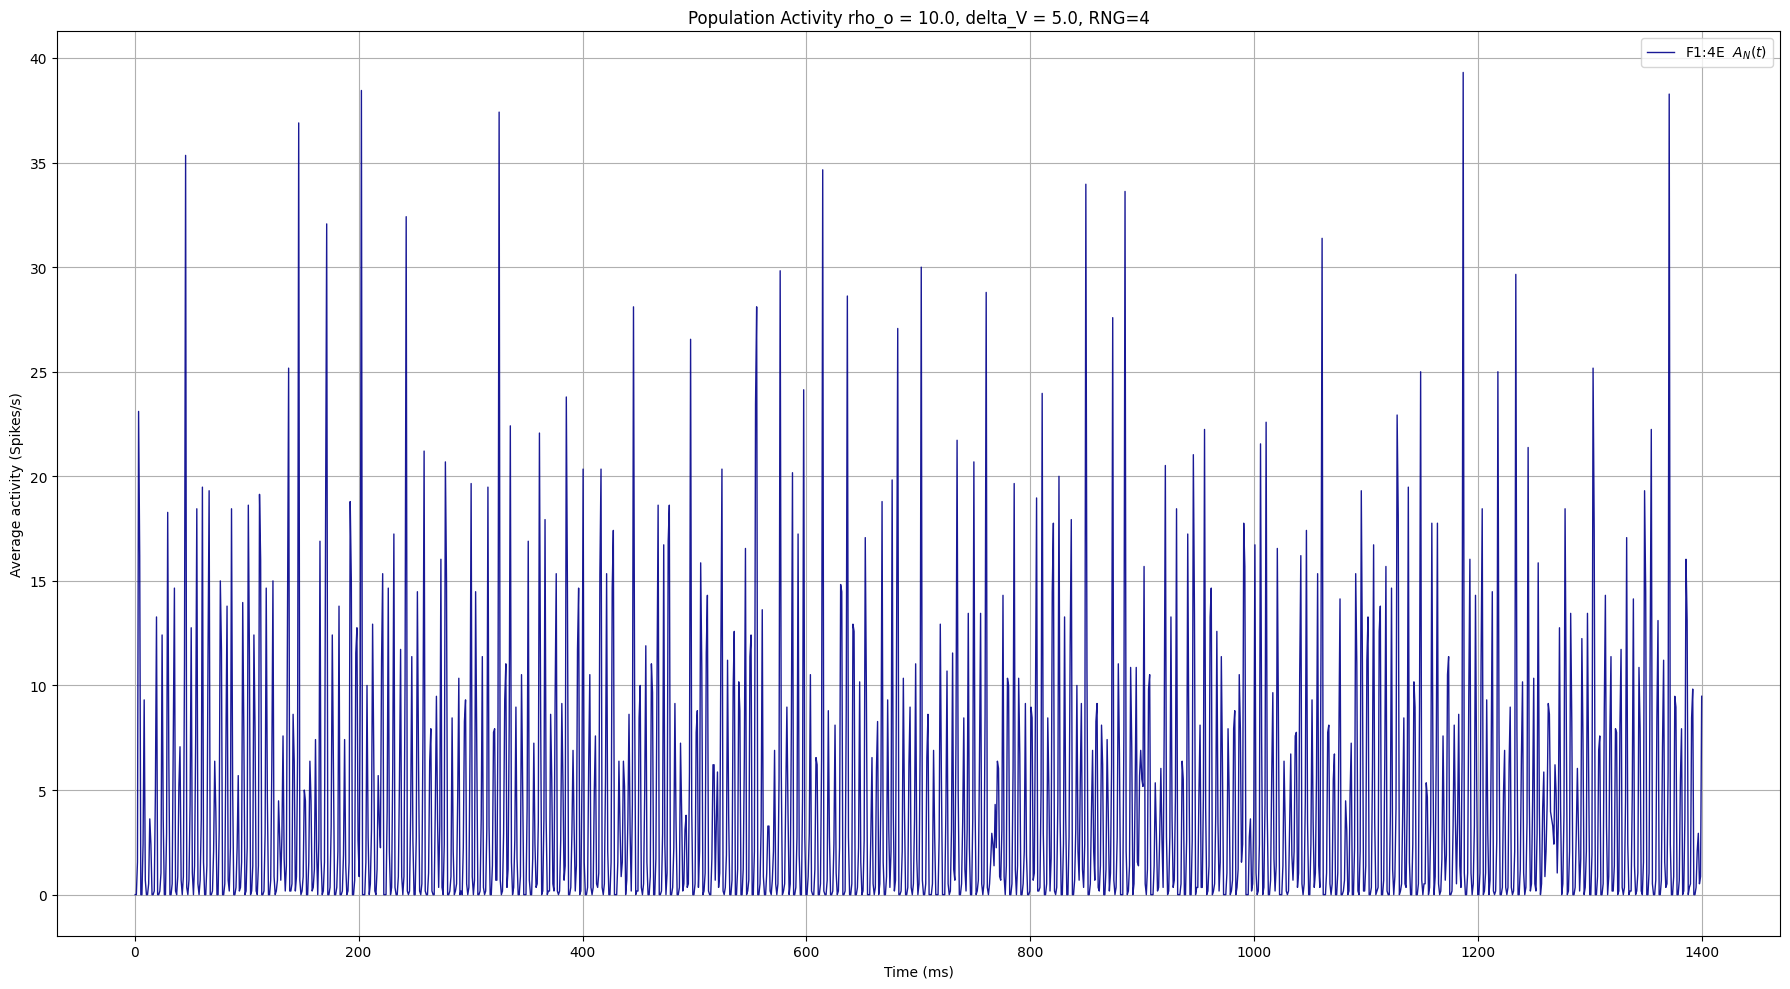

In [29]:
plot_population_activity(
    results,
    areas=['F1'],
    pops=['4E'],
    show_spikes=True,
    show_mean=False,
    title=f'Population Activity rho_o = {rho_0}, delta_V = {Delta_V}, RNG={seed_val}',
    figure_size=(18, 10)
)

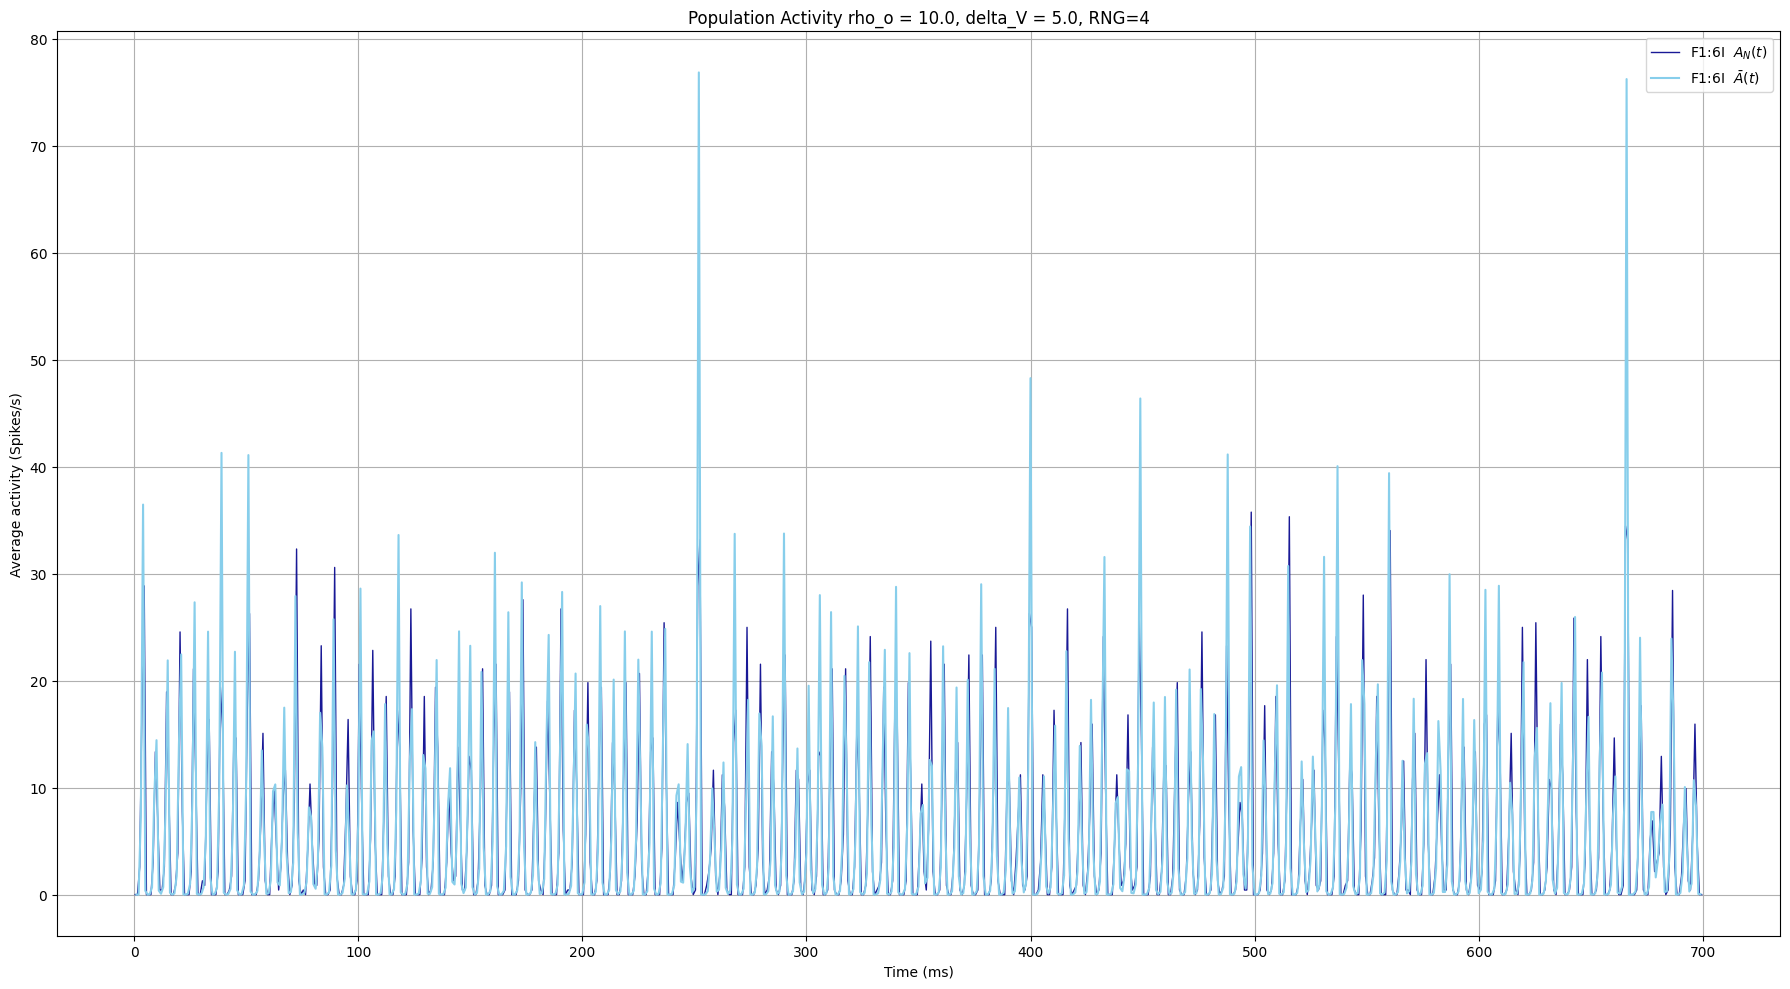

In [30]:
def plot_population_activity(
    results,
    areas,
    pops,
    transient_ms=0.0,
    show_spikes=True,
    show_mean=True,
    smooth=False,
    smoothing_window=5,
    figure_size=(18,6),
    title="Population Activity",
    show_individual=True,      # NEW: toggle individual pop traces on/off
    show_area_average=True,    # NEW: toggle the population-averaged trace
    show_std_band=True         # NEW: shaded band = std across populations
):
    if isinstance(areas, str):
        areas = [areas]
    if isinstance(pops, str):
        pops = [pops]

    plt.figure(figsize=figure_size)

    for area in areas:

        # --------------------------------------------
        # Collect all population traces first (needed for averaging)
        # --------------------------------------------
        spk_traces, mean_traces = [], []
        t_spk_ref, t_mm_ref = None, None

        for pop in pops:
            data = results[area][pop]

            if show_spikes:
                t_spk = data["time_bins"]
                A_spk = data["rate_from_spikes"]
                mask = t_spk >= transient_ms
                t_spk_masked = t_spk[mask]
                A_spk_masked = A_spk[mask]

                if smooth:
                    kernel = np.ones(smoothing_window) / smoothing_window
                    A_spk_masked = np.convolve(A_spk_masked, kernel, mode='same')

                spk_traces.append(A_spk_masked)
                t_spk_ref = t_spk_masked

                if show_individual:
                    plt.plot(t_spk_masked, A_spk_masked, linewidth=0.7, alpha=0.35,
                              color='darkblue', label=f"{area}:{pop}  $A_N(t)$" if len(pops)==1 else None)

            if show_mean:
                t_mm = data["times_mm"]
                A_mean = data["rate_from_mean"]
                mask = t_mm >= transient_ms
                t_mm_masked = t_mm[mask]
                A_mean_masked = A_mean[mask]

                if smooth:
                    kernel = np.ones(smoothing_window) / smoothing_window
                    A_mean_masked = np.convolve(A_mean_masked, kernel, mode='same')

                mean_traces.append(A_mean_masked)
                t_mm_ref = t_mm_masked

                if show_individual:
                    plt.plot(t_mm_masked, A_mean_masked, linewidth=0.3, alpha=0.3,
                              color='skyblue', label=f"{area}:{pop}  $\\bar A(t)$" if len(pops)==1 else None)

        # --------------------------------------------
        # Area-averaged activity: mean across populations at each timepoint
        # --------------------------------------------
        if show_area_average and show_spikes and spk_traces:
            spk_stack = np.array(spk_traces)              # shape: (n_pops, n_timepoints)
            avg_spk = spk_stack.mean(axis=0)
            std_spk = spk_stack.std(axis=0)

            plt.plot(t_spk_ref, avg_spk, linewidth=2.2, color='navy',
                      label=f"{area} population-averaged $A_N(t)$")
            if show_std_band:
                plt.fill_between(t_spk_ref, avg_spk - std_spk, avg_spk + std_spk,
                                  color='navy', alpha=0.15)

        if show_area_average and show_mean and mean_traces:
            mean_stack = np.array(mean_traces)
            avg_mean = mean_stack.mean(axis=0)
            std_mean = mean_stack.std(axis=0)

            plt.plot(t_mm_ref, avg_mean, linewidth=2.2, color='deepskyblue',
                      label=f"{area} population-averaged $\\bar A(t)$")
            if show_std_band:
                plt.fill_between(t_mm_ref, avg_mean - std_mean, avg_mean + std_mean,
                                  color='deepskyblue', alpha=0.15)

    plt.xlabel("Time (ms)")
    plt.ylabel("Average activity (spikes/s)")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

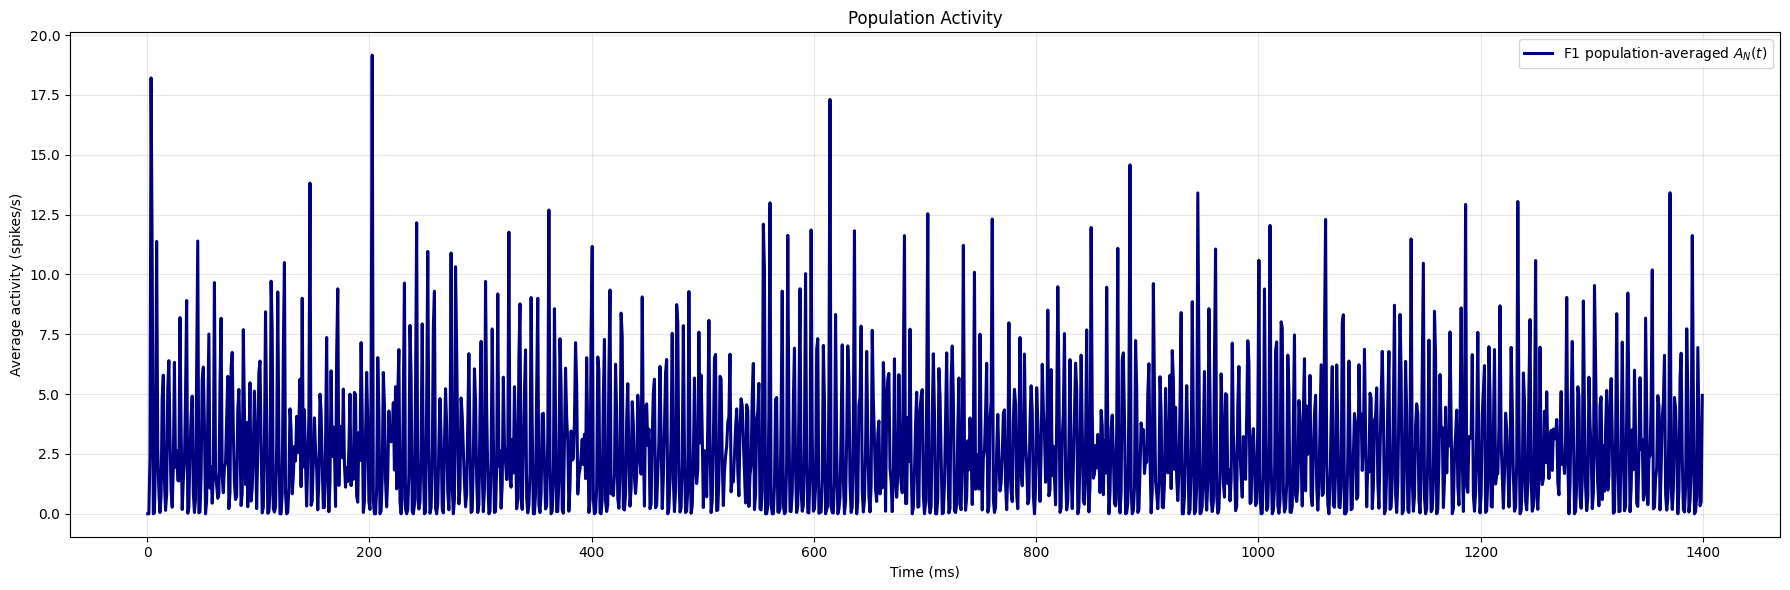

In [31]:
plot_population_activity(
    results,
    ['F1'],
    population_list,
    transient_ms=0.0,
    show_spikes=True,
    show_mean=False,
    smooth=True,
    smoothing_window=1,
    figure_size=(18,6),
    title="Population Activity",
    show_individual=False,      # NEW: toggle individual pop traces on/off
    show_area_average=True,    # NEW: toggle the population-averaged trace
    show_std_band=False         # NEW: shaded band = std across populations
)

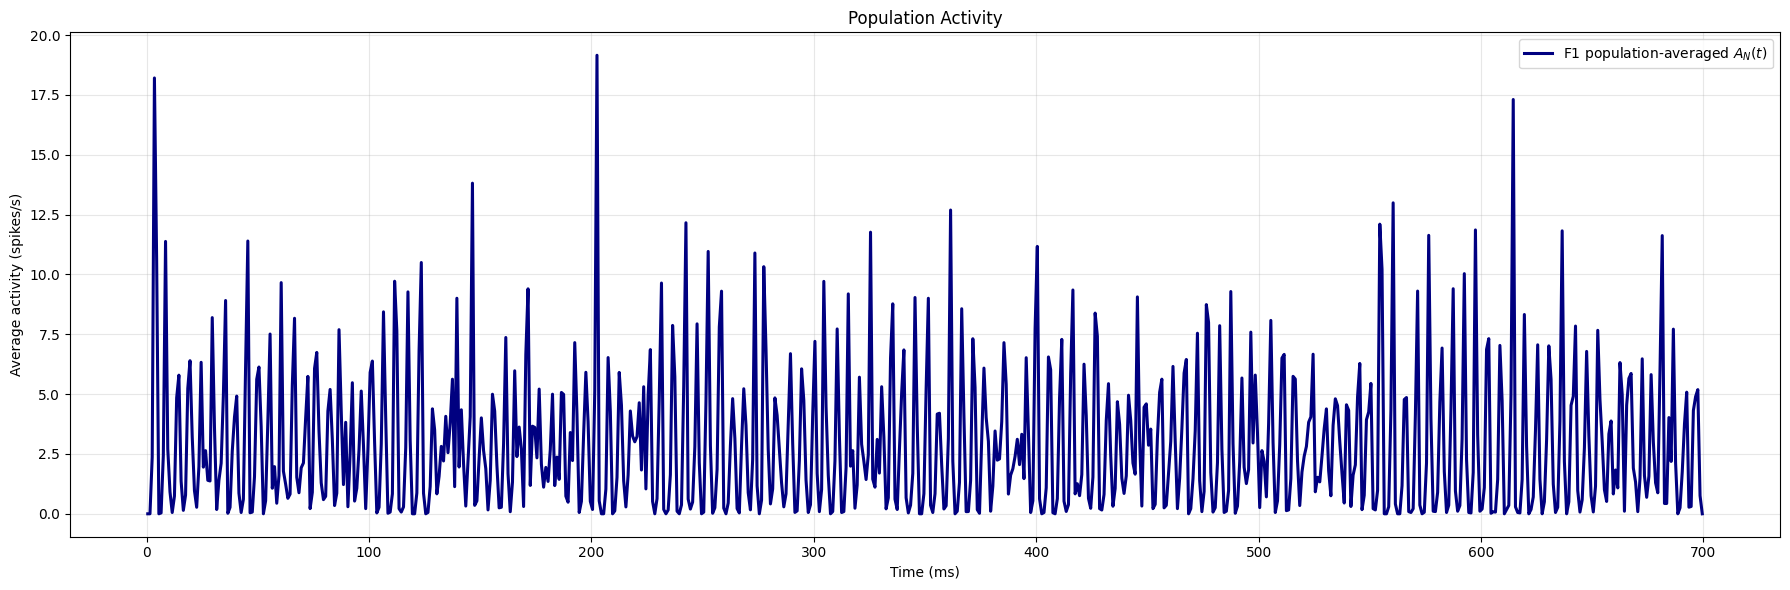

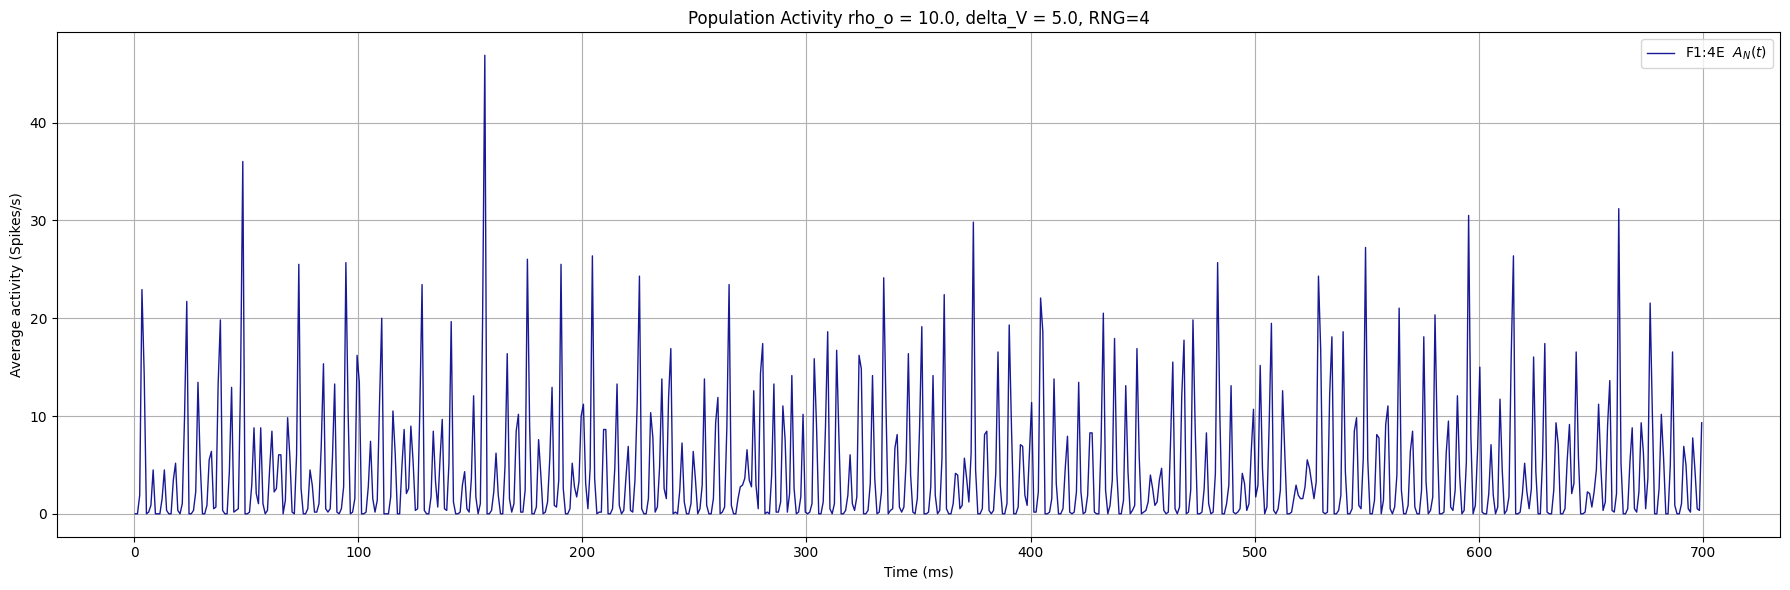

In [34]:
import numpy as np
import pandas as pd

# ============================================================
# 1. Burst detection (threshold-based, applied to rate traces)
# ============================================================
def detect_bursts(x, thresh_percentile=75, min_dur=1):
    """Detect burst episodes where rate exceeds a percentile threshold."""
    thresh = np.percentile(x, thresh_percentile)
    above = x > thresh
    bursts, start = [], None
    for i, a in enumerate(above):
        if a and start is None:
            start = i
        elif not a and start is not None:
            if i - start >= min_dur:
                bursts.append((start, i))
            start = None
    if start is not None:
        bursts.append((start, len(above)))
    durations = [e - s for s, e in bursts]
    inter_burst = [bursts[i+1][0] - bursts[i][1] for i in range(len(bursts) - 1)]
    duty_cycle = above.sum() / len(x)
    return {'threshold': thresh, 'n_bursts': len(bursts), 'burst_durations': durations,
            'inter_burst_intervals': inter_burst, 'duty_cycle': duty_cycle, 'bursts': bursts}


# ============================================================
# 2. Burstiness coefficient B (Goh & Barabasi normalized index)
#    B -> 1: bursty, B ~ 0: Poisson-like, B -> -1: periodic
# ============================================================
def burstiness_coefficient(intervals):
    intervals = np.asarray(intervals, dtype=float)
    if len(intervals) < 2:
        return np.nan
    mu, sigma = intervals.mean(), intervals.std()
    return (sigma - mu) / (sigma + mu)


# ============================================================
# 3. Sliding-window mean/variance (non-stationarity check)
# ============================================================
def sliding_stats(x, window=20, step=5):
    means, stds, centers = [], [], []
    for start in range(0, len(x) - window, step):
        seg = x[start:start + window]
        means.append(seg.mean())
        stds.append(seg.std())
        centers.append(start + window // 2)
    return np.array(centers), np.array(means), np.array(stds)


# ============================================================
# 4. Autocorrelation function + power spectral density
# ============================================================
def acf(x, max_lag=50):
    x = x - x.mean()
    n = len(x)
    result = np.correlate(x, x, mode='full')[n - 1:]
    result /= result[0]
    return result[:max_lag]

def power_spectrum(x, dt=1.0):
    x = x - x.mean()
    n = len(x)
    freqs = np.fft.rfftfreq(n, d=dt)
    psd = np.abs(np.fft.rfft(x)) ** 2 / n
    return freqs, psd


# ============================================================
# 5. Hidden Markov Model state fitting (optional: needs hmmlearn)
#    pip install hmmlearn
# ============================================================
def fit_hmm(x, n_states=2, n_iter=200, random_state=0):
    try:
        from hmmlearn.hmm import GaussianHMM
    except ImportError:
        return None, None
    X = x.reshape(-1, 1)
    model = GaussianHMM(n_components=n_states, covariance_type='diag',
                         n_iter=n_iter, random_state=random_state)
    model.fit(X)
    states = model.predict(X)
    means = model.means_.flatten()
    return model, {'states': states, 'means': means, 'logL': model.score(X)}


# ============================================================
# 6. Hartigan's dip test for bimodality (optional: needs diptest)
#    pip install diptest
# ============================================================
def hartigan_dip_test(data):
    try:
        import diptest
    except ImportError:
        return None
    dip, pval = diptest.diptest(np.asarray(data))
    return {'dip_statistic': dip, 'p_value': pval}


# ============================================================
# 7. Master function: run full battery on one node's trace
# ============================================================
def analyze_node(x, label='', thresh_percentile=75, hmm_states=2):
    x = np.asarray(x, dtype=float)
    bstats = detect_bursts(x, thresh_percentile=thresh_percentile)
    B = burstiness_coefficient(bstats['inter_burst_intervals'])
    centers, means, stds = sliding_stats(x)
    acf_vals = acf(x, max_lag=min(50, len(x)//2))
    freqs, psd = power_spectrum(x)
    hmm_model, hmm_res = fit_hmm(x, n_states=hmm_states)

    summary = {
        'label': label,
        'mean_rate': x.mean(),
        'std_rate': x.std(),
        'max_rate': x.max(),
        'n_bursts': bstats['n_bursts'],
        'duty_cycle': bstats['duty_cycle'],
        'burstiness_B': B,
        'mean_burst_duration': np.mean(bstats['burst_durations']) if bstats['burst_durations'] else np.nan,
        'sliding_var_range': stds.max() - stds.min() if len(stds) else np.nan,
        'hmm_state_means': hmm_res['means'].tolist() if hmm_res else None,
        'hmm_logL': hmm_res['logL'] if hmm_res else None,
    }
    detail = {'burst_info': bstats, 'sliding': (centers, means, stds),
              'acf': acf_vals, 'psd': (freqs, psd), 'hmm': hmm_res}
    return summary, detail


# ============================================================
# 8. Batch runner across the full 344-node dictionary
# ============================================================
def analyze_all_nodes(results, area_list, population_list, transient_cut=50,
                       thresh_percentile=75, hmm_states=2):
    """
    results: dict[area][pop]['rate_from_spikes'] -> np.array
    transient_cut: number of initial ms/bins to discard as transient
    Returns a tidy DataFrame, one row per (area, population).
    """
    rows = []
    for area in area_list:
        for pop in population_list:
            try:
                trace = results[area][pop]['rate_from_spikes']
            except KeyError:
                continue
            trace = np.asarray(trace, dtype=float)[transient_cut:]
            if len(trace) < 20:
                continue
            summary, _ = analyze_node(trace, label=f'{area}_{pop}',
                                       thresh_percentile=thresh_percentile,
                                       hmm_states=hmm_states)
            summary['area'] = area
            summary['population'] = pop
            rows.append(summary)
    return pd.DataFrame(rows)


# ============================================================
# 9. Bistability test across seeds (network-mean rate per seed)
# ============================================================
def bistability_dip_test(seed_mean_rates):
    """seed_mean_rates: array-like of one scalar mean rate per seed."""
    data = np.log10(np.asarray(seed_mean_rates) + 1e-3)  # log-scale separates decades
    return hartigan_dip_test(data)

In [35]:
#complete_area_list = ['V1', 'V2', ..., 'TH-TF']  # your 43 areas
population_list = ['23E', '23I', '4E', '4I', '5E', '5I', '6E', '6I']

# Run on the full 344-node dictionary (discard first ~50 ms transient)
df = analyze_all_nodes(results, ['F1'], ['4E'], transient_cut=50)

# Sort by burstiness to see which nodes are most bursty
df_sorted = df.sort_values('burstiness_B', ascending=False)
print(df_sorted[['area', 'population', 'mean_rate', 'burstiness_B', 'duty_cycle', 'n_bursts']].head(20))

# Test bistability across seeds using your network-mean rates
#seed_rates = [35, 37, 33, 1.852, 36, 1.850, ]  # your 22 seed values
#dip_result = bistability_dip_test(seed_rates)
#print(dip_result)  # significant p-value (< 0.05) supports genuine bimodality

  area population  mean_rate  burstiness_B  duty_cycle  n_bursts
0   F1         4E     4.5626     -0.331704    0.248889       233


In [36]:
import matplotlib.pyplot as plt
import numpy as np

def plot_burstiness_relationships(df, area_col='area', pop_col='population',
                                    highlight_thresh_B=0.3, highlight_thresh_rate=None,
                                    annotate_top_n=10, figsize=(14, 6), save_path=None):
    """
    Plot burstiness (B) vs mean_rate and B vs duty_cycle side by side.

    Parameters
    ----------
    df : pd.DataFrame
        Output of analyze_all_nodes(), must contain columns:
        'burstiness_B', 'mean_rate', 'duty_cycle', area_col, pop_col
    highlight_thresh_B : float
        B values above this are highlighted as candidate "driver" nodes
    highlight_thresh_rate : float or None
        Optional mean_rate threshold for a second highlight criterion
    annotate_top_n : int
        Number of most-bursty nodes to label with area_pop names
    figsize : tuple
        Figure size
    save_path : str or None
        If provided, saves the figure to this path (e.g. 'burst_scatter.png')
    """
    fig, axes = plt.subplots(1, 2, figsize=figsize)

    # Color by population type if E/I is encoded in population names
    is_excitatory = df[pop_col].astype(str).str.contains('E', case=False)
    colors = np.where(is_excitatory, '#d62728', '#1f77b4')  # red=E, blue=I

    driver_mask = df['burstiness_B'] >= highlight_thresh_B
    if highlight_thresh_rate is not None:
        driver_mask &= df['mean_rate'] >= highlight_thresh_rate

    # --- Panel 1: B vs mean_rate ---
    ax = axes[0]
    ax.scatter(df.loc[~driver_mask, 'mean_rate'], df.loc[~driver_mask, 'burstiness_B'],
               c=colors[~driver_mask.values], alpha=0.5, s=35, edgecolors='none', label='_nolegend_')
    ax.scatter(df.loc[driver_mask, 'mean_rate'], df.loc[driver_mask, 'burstiness_B'],
               c=colors[driver_mask.values], alpha=0.9, s=70, edgecolors='black', linewidths=0.8,
               label='Candidate drivers')
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.axhline(highlight_thresh_B, color='red', linestyle=':', linewidth=0.8, alpha=0.6)
    ax.set_xlabel('Mean rate (spikes/s)')
    ax.set_ylabel('Burstiness coefficient (B)')
    ax.set_title('Burstiness vs. Mean Firing Rate')
    ax.set_xscale('log')

    # --- Panel 2: B vs duty_cycle ---
    ax2 = axes[1]
    ax2.scatter(df.loc[~driver_mask, 'duty_cycle'], df.loc[~driver_mask, 'burstiness_B'],
                c=colors[~driver_mask.values], alpha=0.5, s=35, edgecolors='none')
    ax2.scatter(df.loc[driver_mask, 'duty_cycle'], df.loc[driver_mask, 'burstiness_B'],
                c=colors[driver_mask.values], alpha=0.9, s=70, edgecolors='black', linewidths=0.8)
    ax2.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax2.axhline(highlight_thresh_B, color='red', linestyle=':', linewidth=0.8, alpha=0.6)
    ax2.set_xlabel('Duty cycle (fraction of time active)')
    ax2.set_ylabel('Burstiness coefficient (B)')
    ax2.set_title('Burstiness vs. Duty Cycle')

    # Annotate the top-N most bursty nodes on both panels
    top_nodes = df.nlargest(annotate_top_n, 'burstiness_B')
    for _, row in top_nodes.iterrows():
        label = f"{row[area_col]}_{row[pop_col]}"
        axes[0].annotate(label, (row['mean_rate'], row['burstiness_B']),
                          fontsize=7, xytext=(4, 4), textcoords='offset points')
        axes[1].annotate(label, (row['duty_cycle'], row['burstiness_B']),
                          fontsize=7, xytext=(4, 4), textcoords='offset points')

    # Legend for E/I coloring
    from matplotlib.lines import Line2D
    legend_elems = [
        Line2D([0], [0], marker='o', color='w', markerfacecolor='#d62728', markersize=8, label='Excitatory'),
        Line2D([0], [0], marker='o', color='w', markerfacecolor='#1f77b4', markersize=8, label='Inhibitory'),
        Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', markeredgecolor='black',
               markersize=9, label=f'B ≥ {highlight_thresh_B} (candidate driver)')
    ]
    fig.legend(handles=legend_elems, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.05), frameon=False)

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=200, bbox_inches='tight')
    plt.show()
    return fig, axes

/tmp/ipykernel_15670/3697377626.py:60: RuntimeWarning:divide by zero encountered in divide
/tmp/ipykernel_15670/3697377626.py:60: RuntimeWarning:invalid value encountered in divide
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


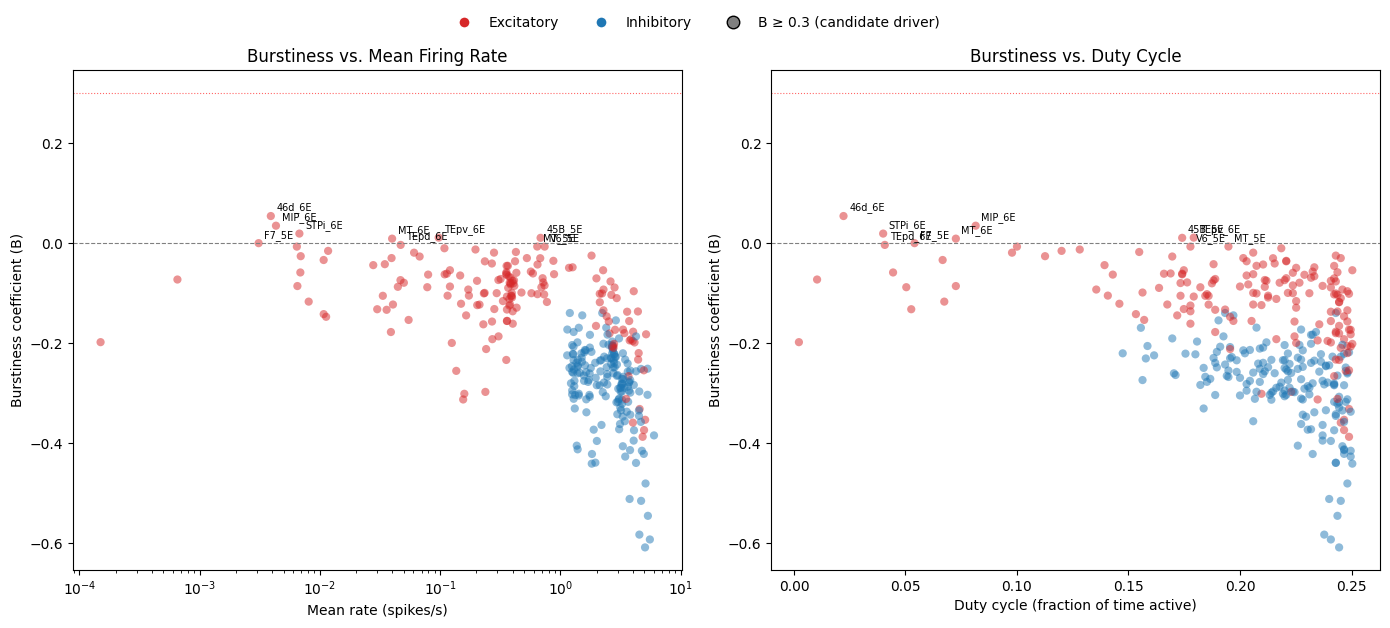

In [37]:
df = analyze_all_nodes(results, complete_area_list, population_list, transient_cut=50)

fig, axes = plot_burstiness_relationships(
    df,
    highlight_thresh_B=0.3,
    annotate_top_n=10,
    save_path='burstiness_scatter.eps'
)

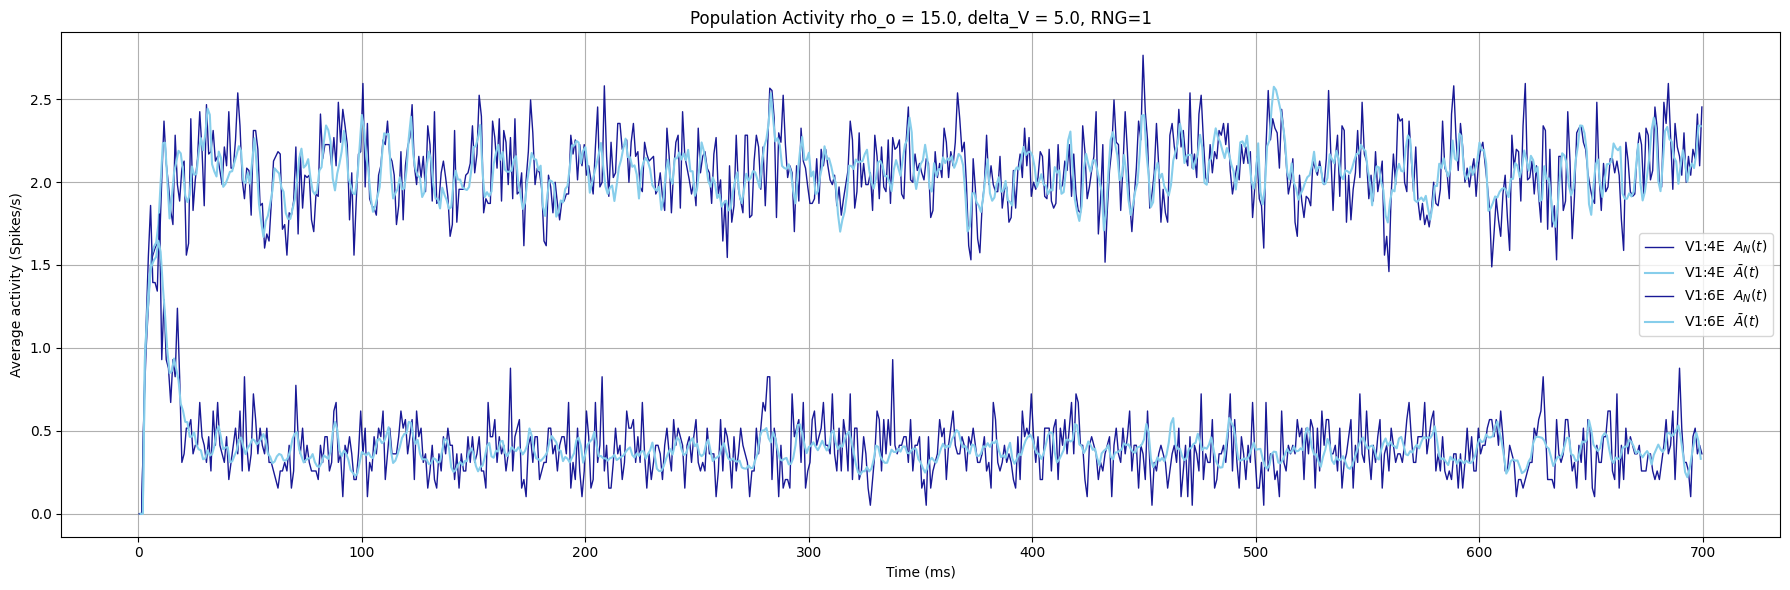

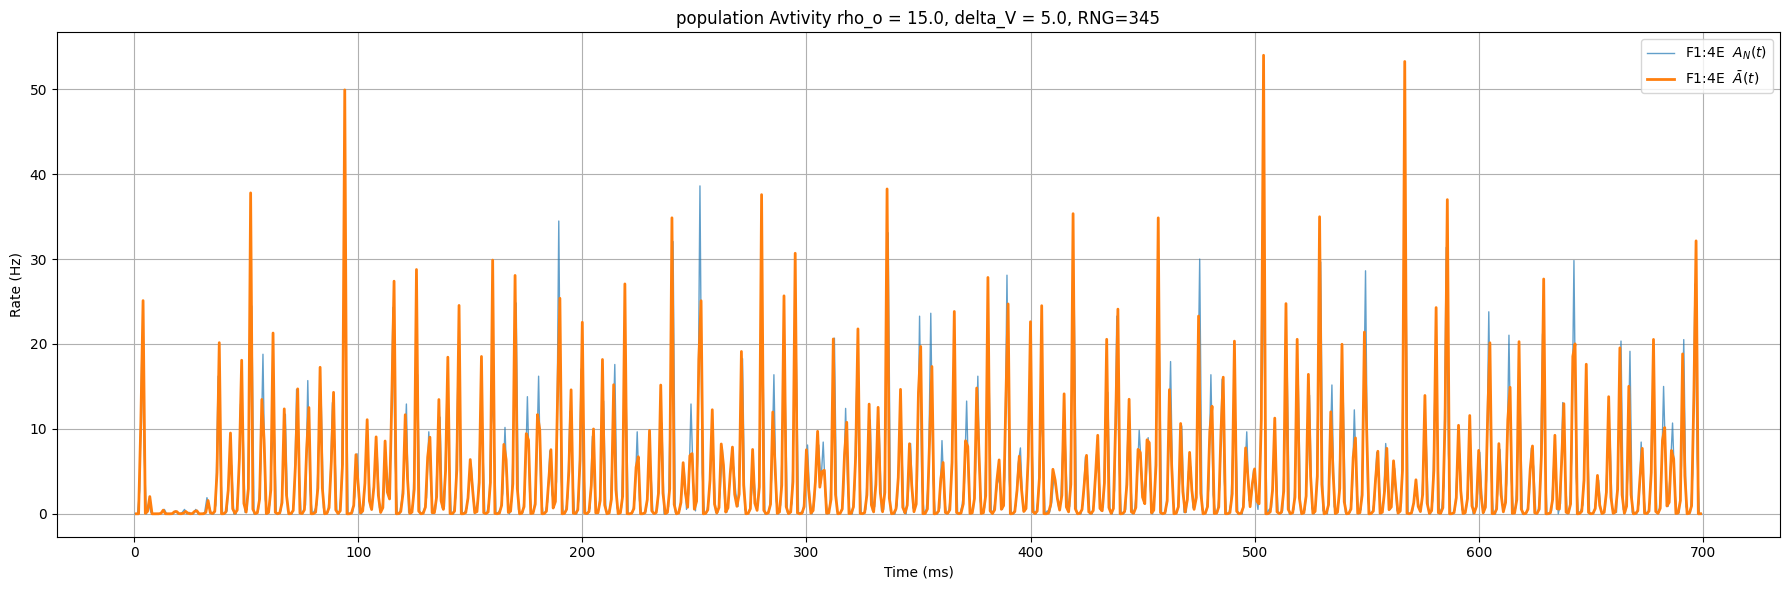

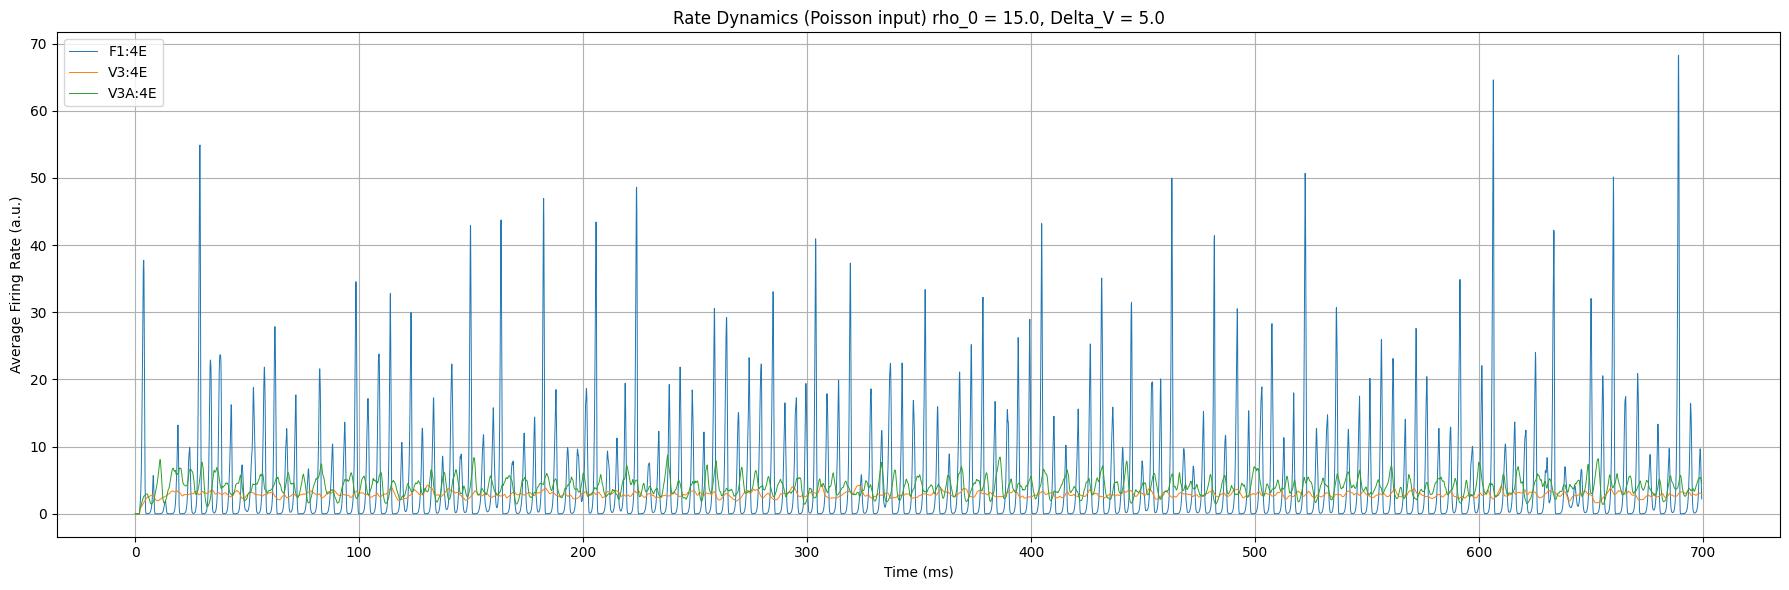

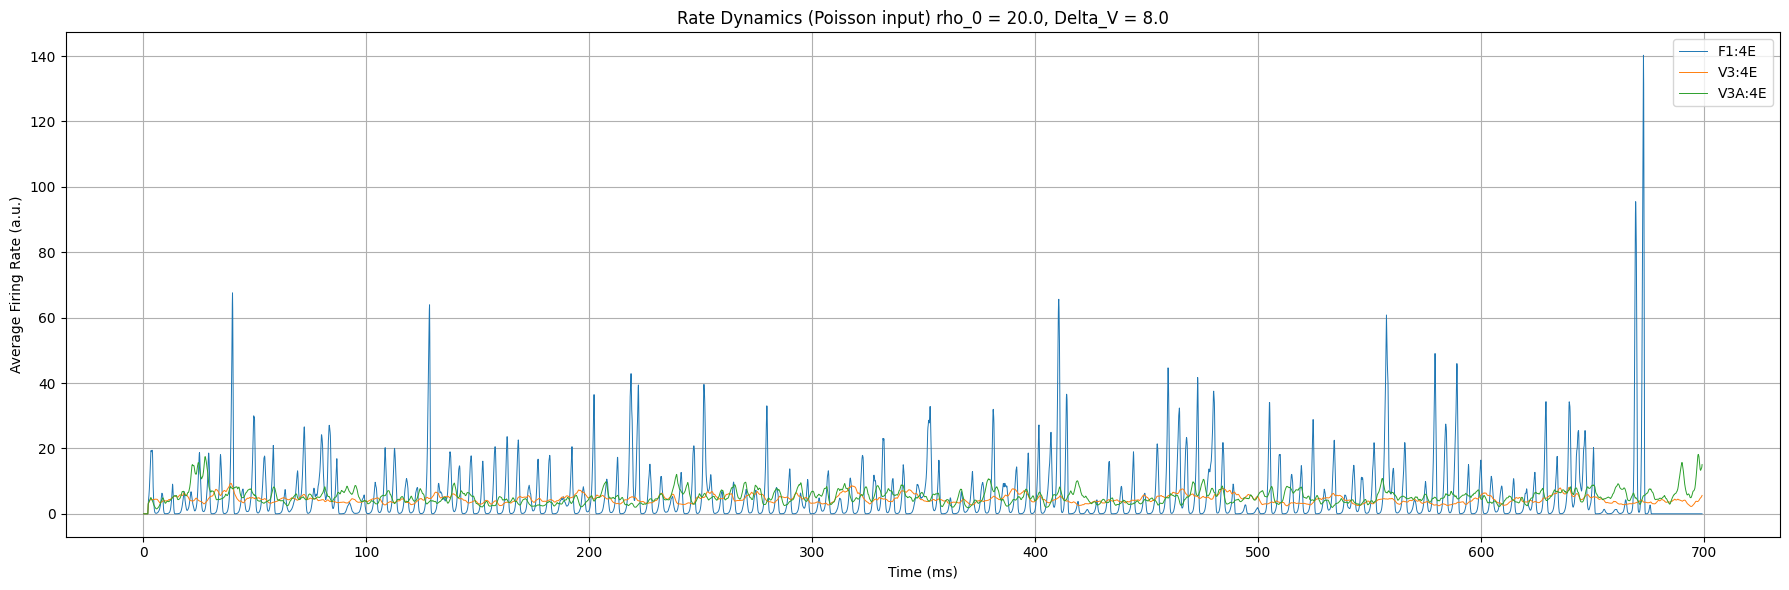

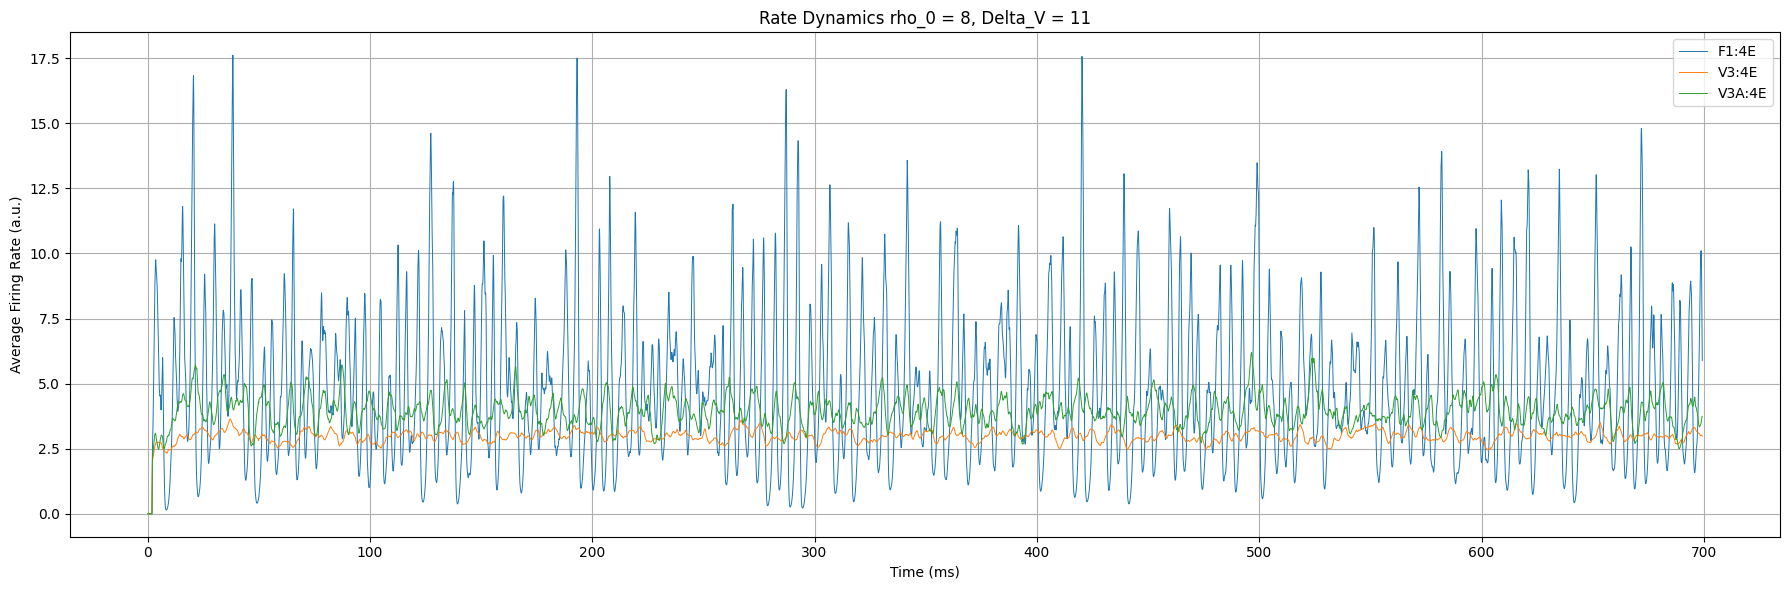

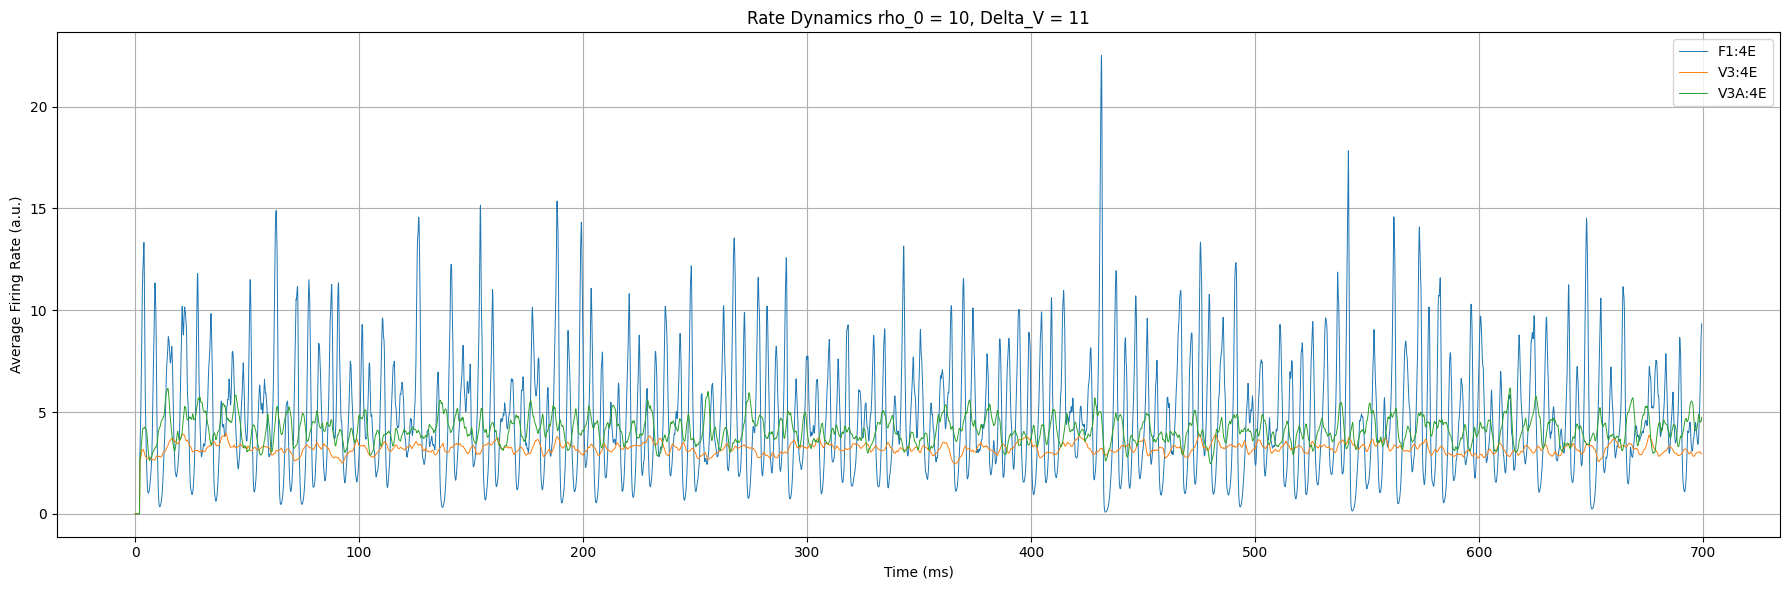

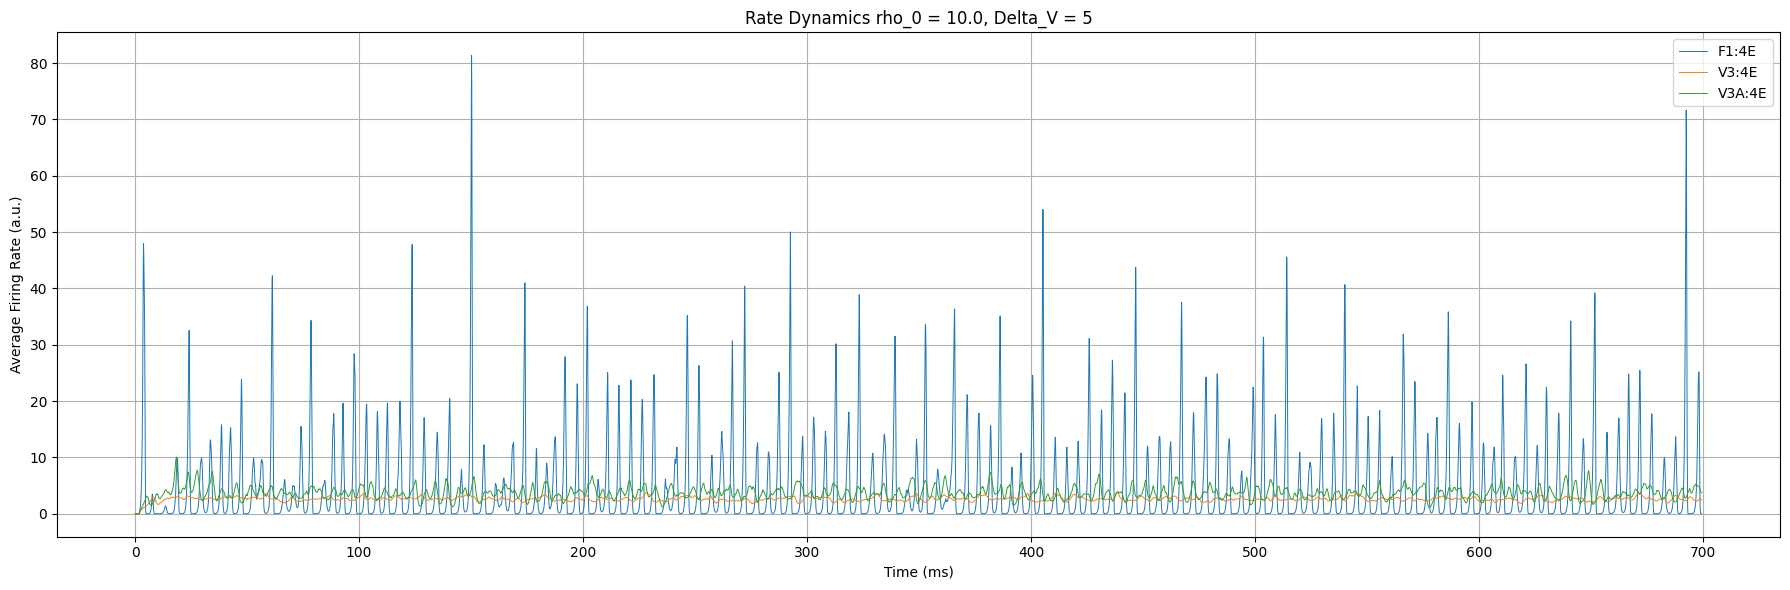

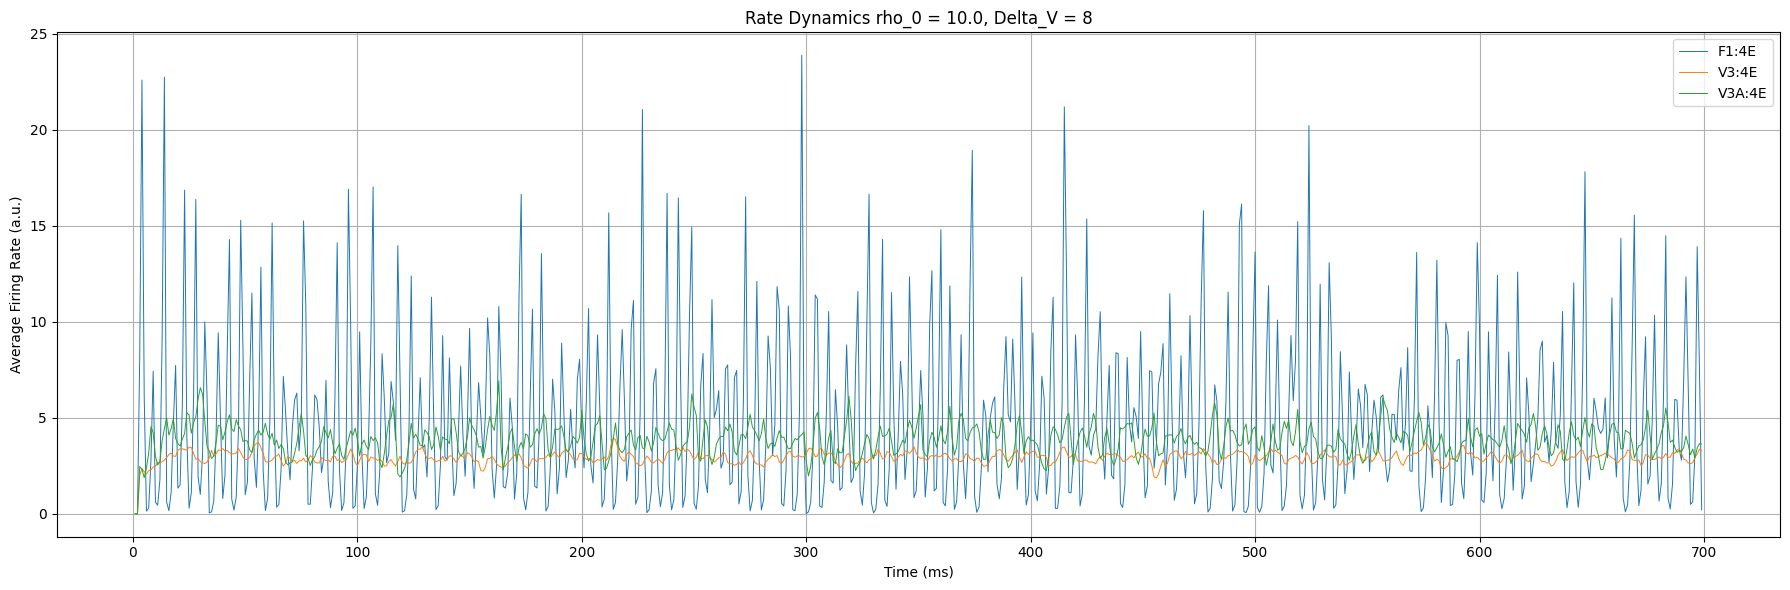

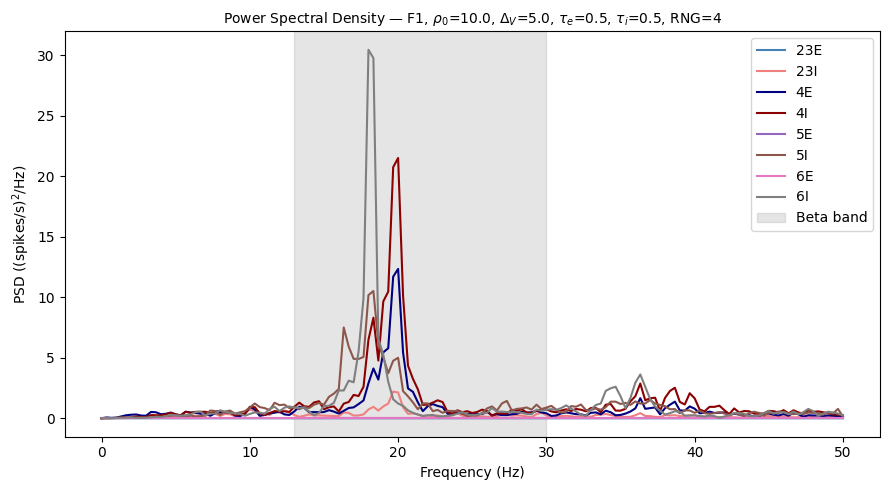

In [76]:
import numpy as np
from scipy.signal import welch
import matplotlib.pyplot as plt

def plot_power_spectrum(results, area, pops, fs, colors=None, nperseg=300,
                         beta_band=(13, 30), xlim=None, title=None,
                         rho_0=None, Delta_V=None, tau_syn_ex_ms=None,
                         tau_syn_in_ms=None, seed_val=None, log_x = False, log_y=False):
    """
    Plot Welch PSD for one area across multiple populations.

    Parameters
    ----------
    results : dict
        Simulation results dict, results[area][pop]['rate_from_spikes'].
    area : str
        Area name to plot.
    pops : list of str
        Populations to plot for this area, e.g. ['23E','23I','4E','4I'].
    fs : float
        Sampling frequency in Hz (1000/record_interval_ms).
    colors : dict, optional
        Mapping {pop_name: color}. If None, default matplotlib cycle is used.
    nperseg : int
        Segment length for Welch's method.
    beta_band : tuple
        (fmin, fmax) to shade as beta band.
    xlim : tuple, optional
        x-axis limits.
    title : str, optional
        Custom title; if None, builds one from provided parameters.
    log_y : bool
        Whether to use log scale on y-axis.
    """
    plt.figure(figsize=(9, 5))

    default_cycle = plt.rcParams['axes.prop_cycle'].by_key()['color']

    for i, pop in enumerate(pops):
        r = results[area][pop]['rate_from_spikes'][200:]
        f, Pxx = welch(r, fs=fs, nperseg=nperseg)

        color = colors[pop] if (colors is not None and pop in colors) else default_cycle[i % len(default_cycle)]
        plt.plot(f, Pxx, label=pop, color=color, linewidth=1.5)

    plt.axvspan(beta_band[0], beta_band[1], color='gray', alpha=0.2, label='Beta band')

    if xlim is not None:
        plt.xlim(xlim)
    if log_y:
        plt.yscale('log')
    if log_x:
        plt.xscale('log')

    plt.xlabel('Frequency (Hz)')
    plt.ylabel(r'PSD $((\mathrm{spikes/s})^2/\mathrm{Hz})$')

    if title is None:
        title = f'Power Spectral Density — {area}'
        params_str = []
        if rho_0 is not None: params_str.append(f'$\\rho_0$={rho_0}')
        if Delta_V is not None: params_str.append(f'$\\Delta_V$={Delta_V}')
        if tau_syn_ex_ms is not None: params_str.append(f'$\\tau_e$={tau_syn_ex_ms}')
        if tau_syn_in_ms is not None: params_str.append(f'$\\tau_i$={tau_syn_in_ms}')
        if seed_val is not None: params_str.append(f'RNG={seed_val}')
        if params_str:
            title += ', ' + ', '.join(params_str)

    plt.title(title, size=10)
    plt.legend()
    plt.tight_layout()
    #plt.savefig('output/power_spectrum_demo.png', dpi=200)
    #plt.close()
    plt.show()


plot_power_spectrum(
    results, area='F1', pops=population_list,
    fs=100,  # your actual sampling rate, e.g. 1000/record_interval_ms
    colors={'23E': 'steelblue', '23I': 'lightcoral', '4E': 'navy', '4I': 'darkred'},
    nperseg=300,
    rho_0=rho_0, Delta_V=Delta_V, tau_syn_ex_ms=tau_syn_ex_ms,
    tau_syn_in_ms=tau_syn_in_ms, seed_val=seed_val,
    #xlim=(0, 50),
    log_x=False,
    log_y=False)

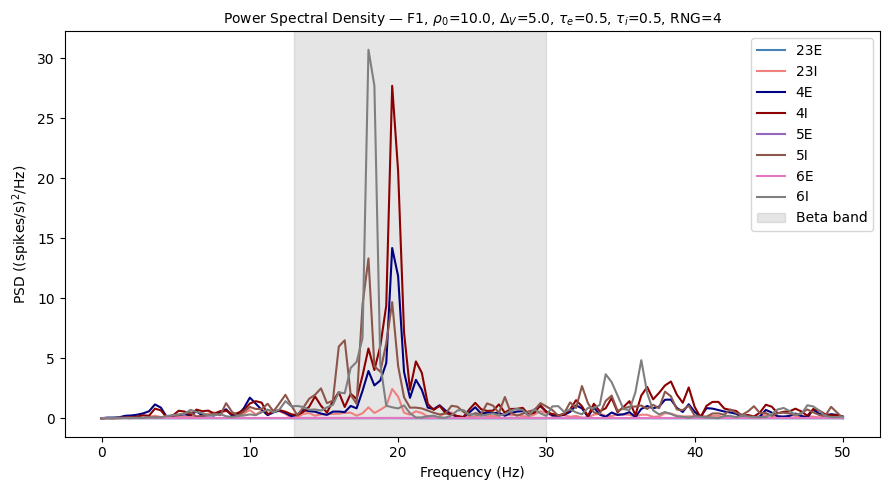

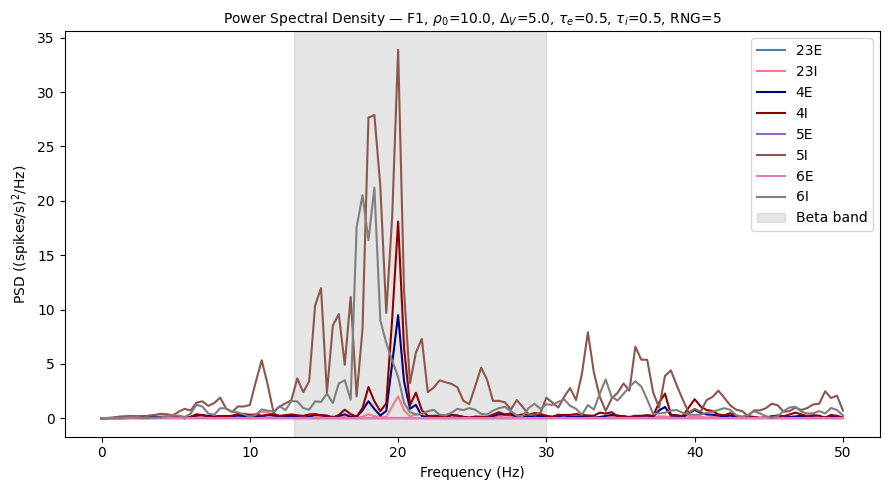

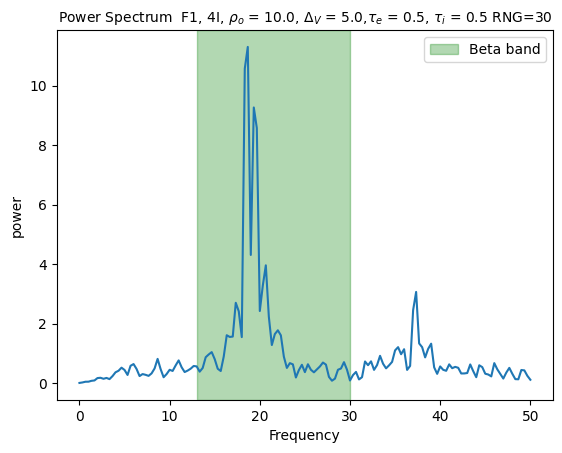 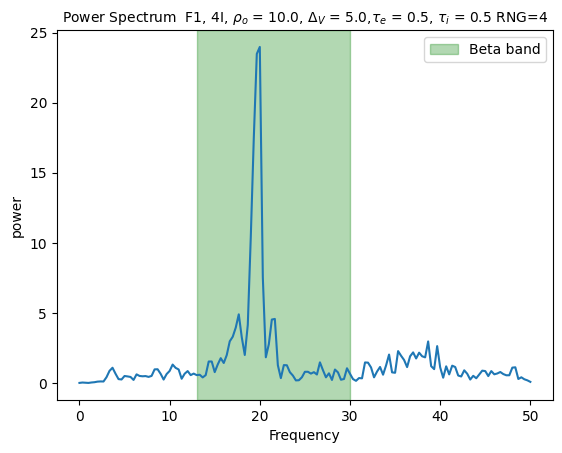

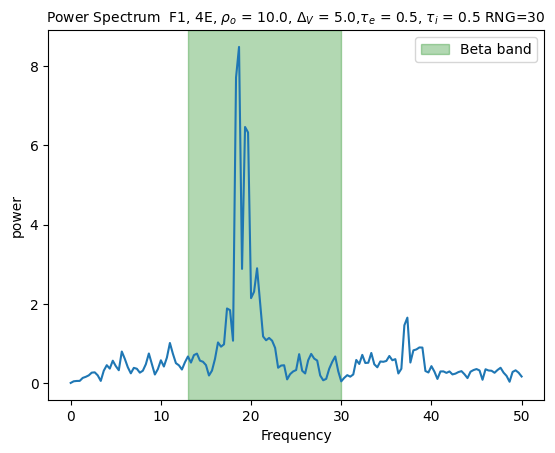 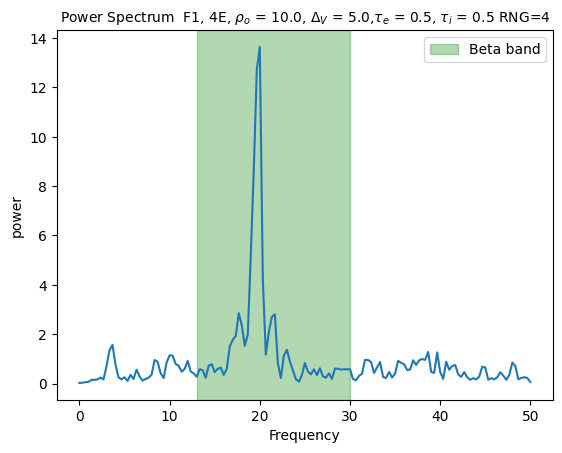

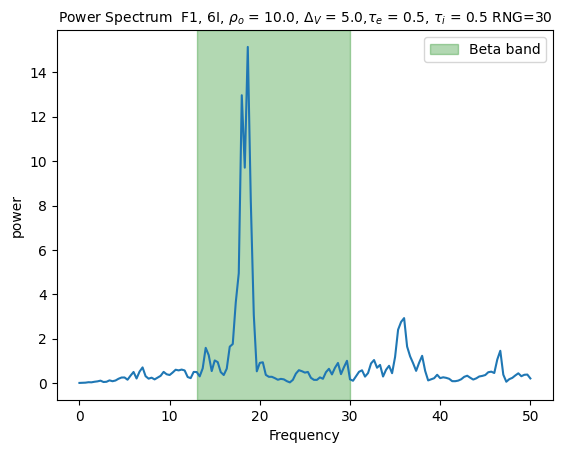   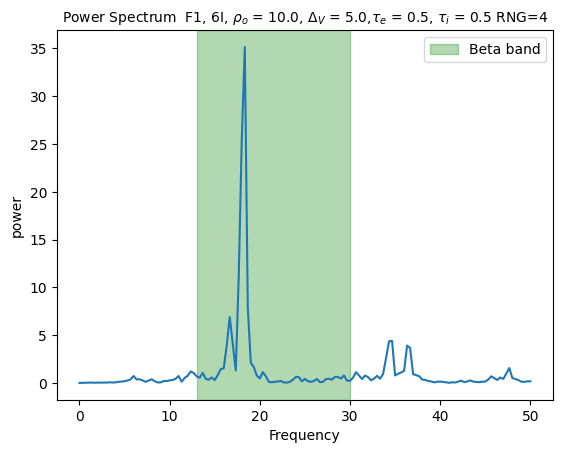



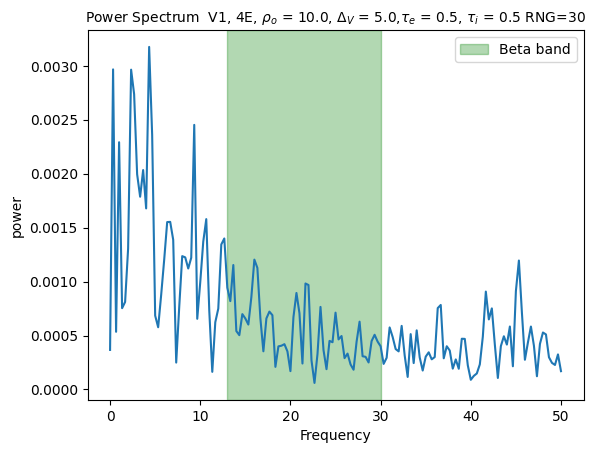 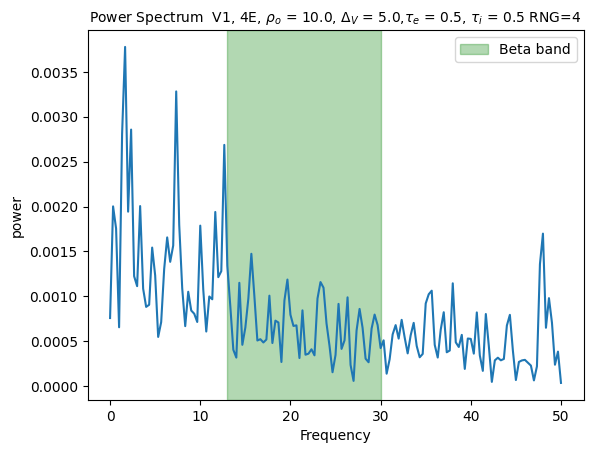

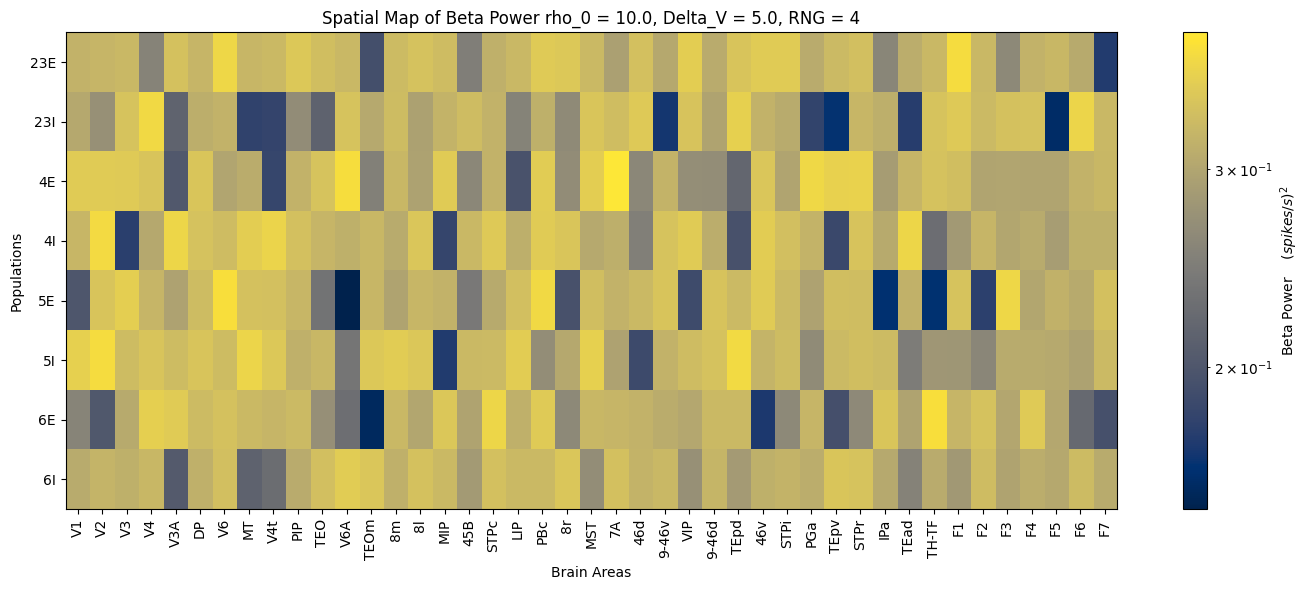

In [80]:
from matplotlib import colors
def band_power(freqs, psd, fmin, fmax):
    idx = (freqs >= fmin) & (freqs <= fmax)
    return np.trapz(psd[idx], freqs[idx])

fs = 100

   
n_pops = len(population_list)
n_areas = len(areas)

power_matrix = np.zeros((n_pops, n_areas))

for i, area in enumerate(areas):          # columns
    for j, pop in enumerate(population_list):          # rows
        
        r = results[area][pop]['rate_from_spikes']
        
        f, Pxx = welch(r, fs=fs, nperseg=200)
        
        power_matrix[j, i] = band_power(f, Pxx, 13, 30)



plt.figure(figsize=(14, 6))
# Using LogNorm reveals patterns in the low-power areas
plt.imshow(power_matrix, aspect='auto', origin='upper', 
           norm=colors.LogNorm(vmin=power_matrix[power_matrix > 0].min(), vmax=power_matrix.max()),
           cmap='cividis') # 'magma' or 'inferno' also work great for log scales

plt.colorbar(label='Beta Power $\quad(spikes/s)^2$')

plt.xticks(range(n_areas), areas, rotation=90)
plt.yticks(range(n_pops), population_list)

plt.xlabel("Brain Areas")
plt.ylabel("Populations")

plt.title(f"Spatial Map of Beta Power rho_0 = {rho_0}, Delta_V = {Delta_V}, RNG = {seed_val}")

plt.tight_layout()
plt.show()

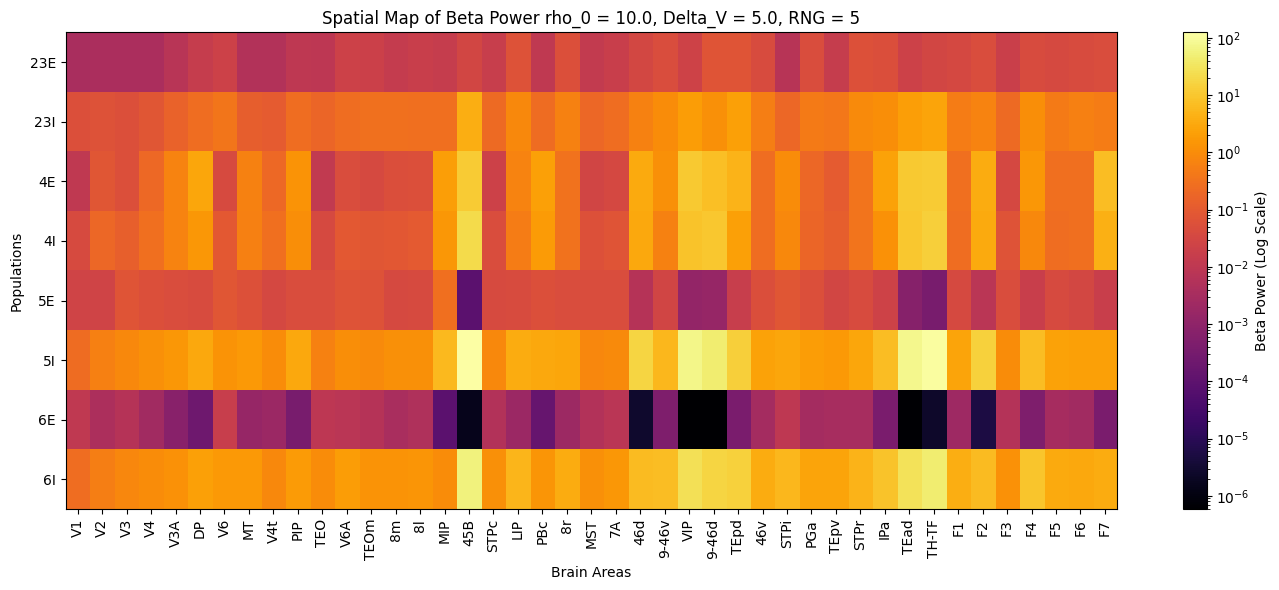

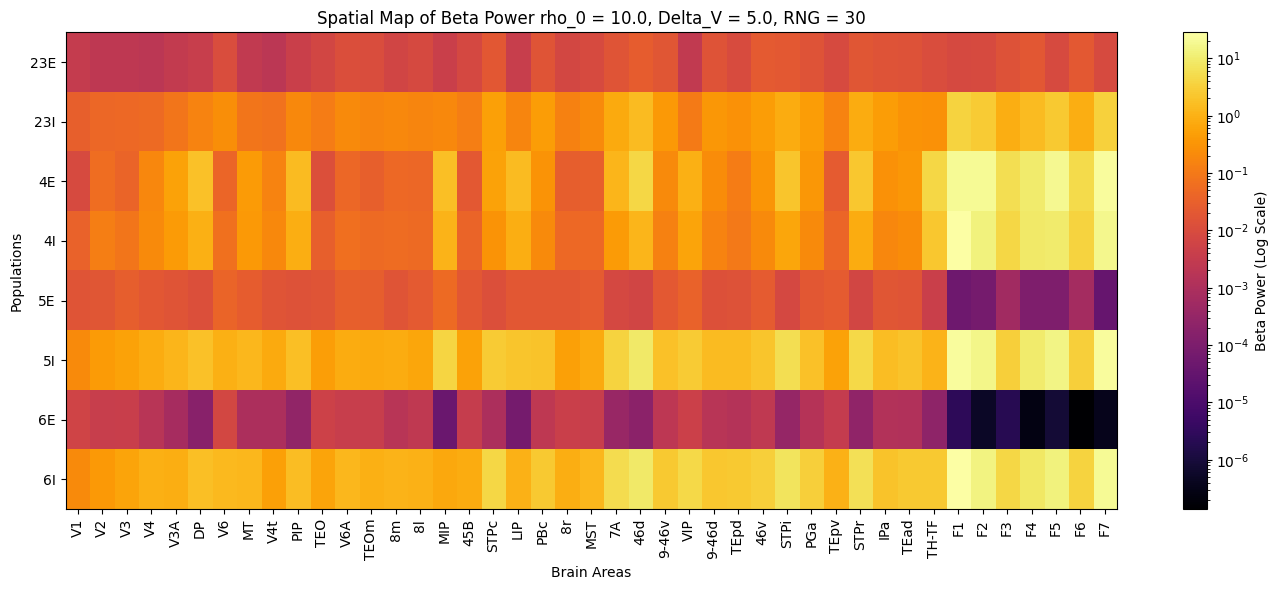

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


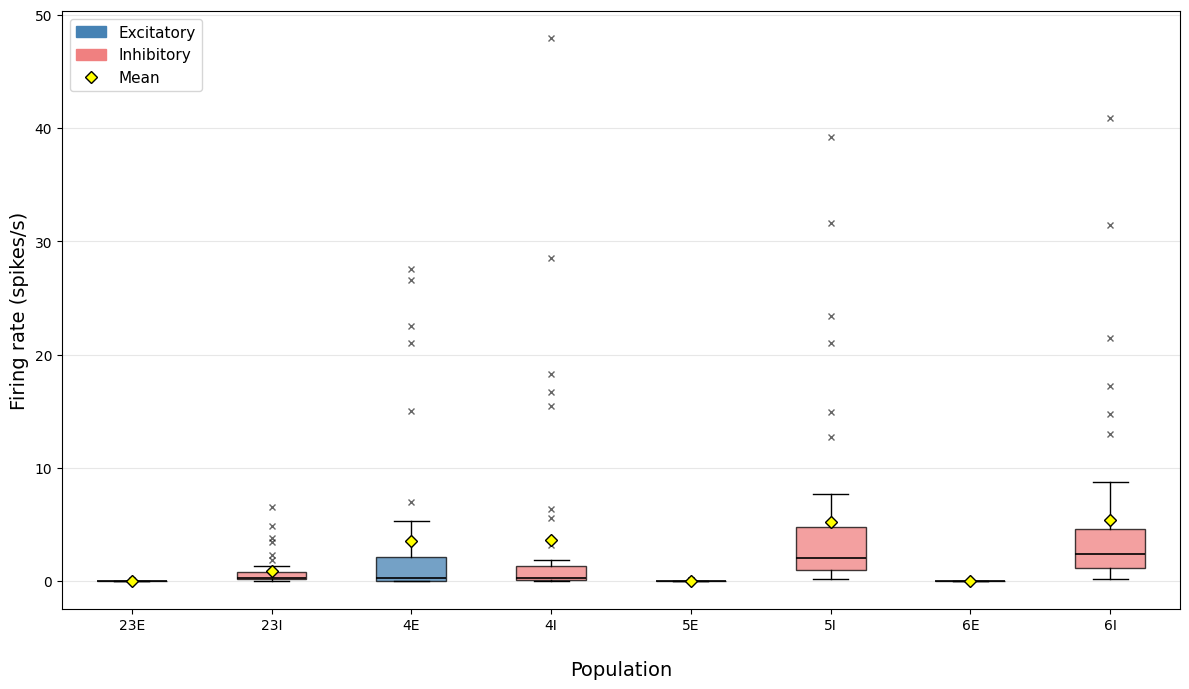

In [40]:
Mean_Rate_comparison_2(power_matrix, population_list, plot_type='box', log_scale=False)

In [ ]:
A = np.zeros((4,3))
A

array([[0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.]])

In [ ]:
def band_power(freqs, psd, fmin, fmax):
    idx = (freqs >= fmin) & (freqs <= fmax)
    return np.trapz(psd[idx], freqs[idx])

n_areas = len(complete_area_list)
area_beta_power = np.zeros(n_areas)

for i, area in enumerate(areas):
    # sum (or average) the rate time series across all populations in this area
    combined_rate = np.sum(
        [results[area][pop]['rate_from_spikes'] for pop in population_list], axis=0
    )
    f, Pxx = welch(combined_rate, fs=fs, nperseg=200)
    area_beta_power[i] = band_power(f, Pxx, 13, 30)

In [ ]:
len(area_beta_power)

43

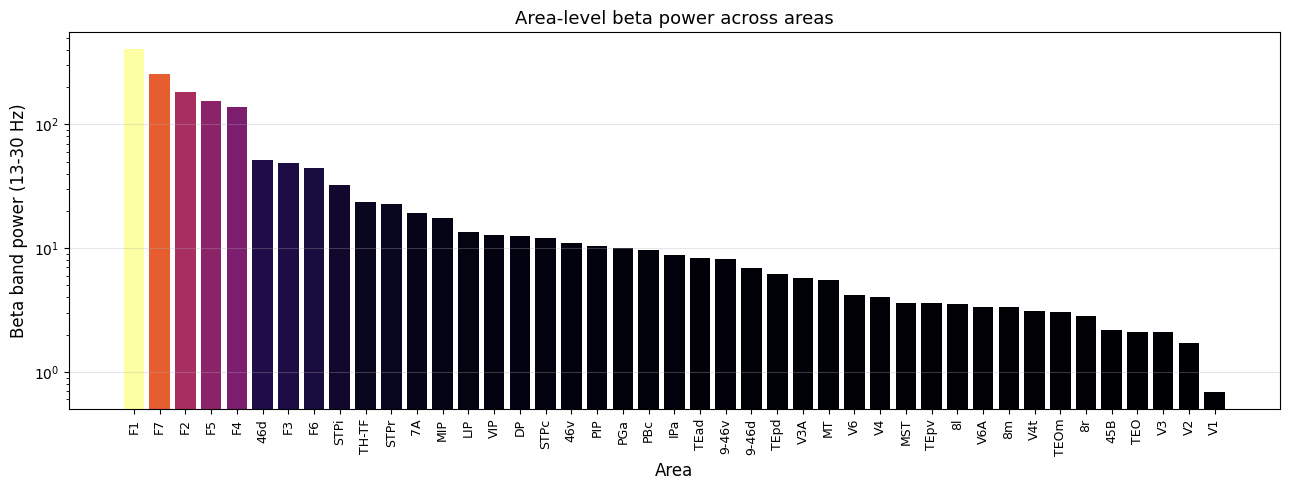

In [84]:
import numpy as np
from scipy.signal import welch
import matplotlib.pyplot as plt


fs = 100

def band_power(freqs, psd, fmin, fmax):
    idx = (freqs >= fmin) & (freqs <= fmax)
    return np.trapz(psd[idx], freqs[idx])

n_areas = len(complete_area_list)
area_beta_power = np.zeros(n_areas)

for i, area in enumerate(complete_area_list):
    combined_rate = np.sum(
        [results[area][pop]['rate_from_spikes'] for pop in population_list], axis=0
    )
    f, Pxx = welch(combined_rate, fs=fs, nperseg=300)  # set fs to your actual sampling rate
    area_beta_power[i] = band_power(f, Pxx, 13, 30)

order = np.argsort(area_beta_power)[::-1]
sorted_areas = [complete_area_list[i] for i in order]
sorted_power = area_beta_power[order]

fig, ax = plt.subplots(figsize=(13,5))
colors_bar = plt.cm.inferno((sorted_power - sorted_power.min())/(sorted_power.max()-sorted_power.min()))
ax.bar(range(n_areas), sorted_power, color=colors_bar)
ax.set_xticks(range(n_areas))
ax.set_xticklabels(sorted_areas, rotation=90, fontsize=9)
ax.set_ylabel('Beta band power (13-30 Hz)', fontsize=12)
ax.set_xlabel('Area', fontsize=12)
ax.set_title(f'Area-level beta power across areas', fontsize=13)
ax.set_yscale('log')
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('area_beta_power.png', dpi=200, bbox_inches='tight')

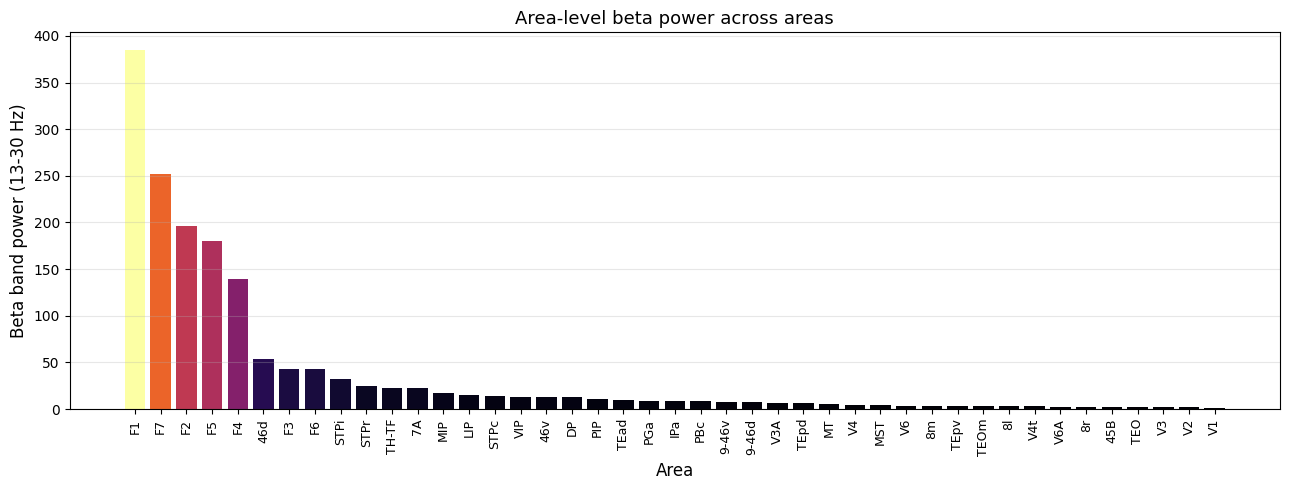

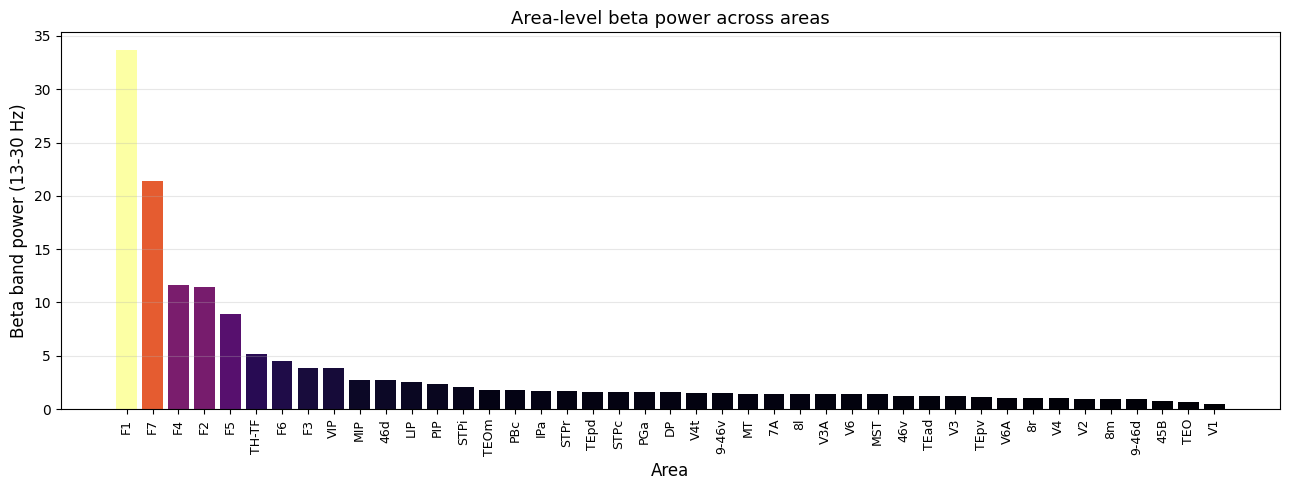

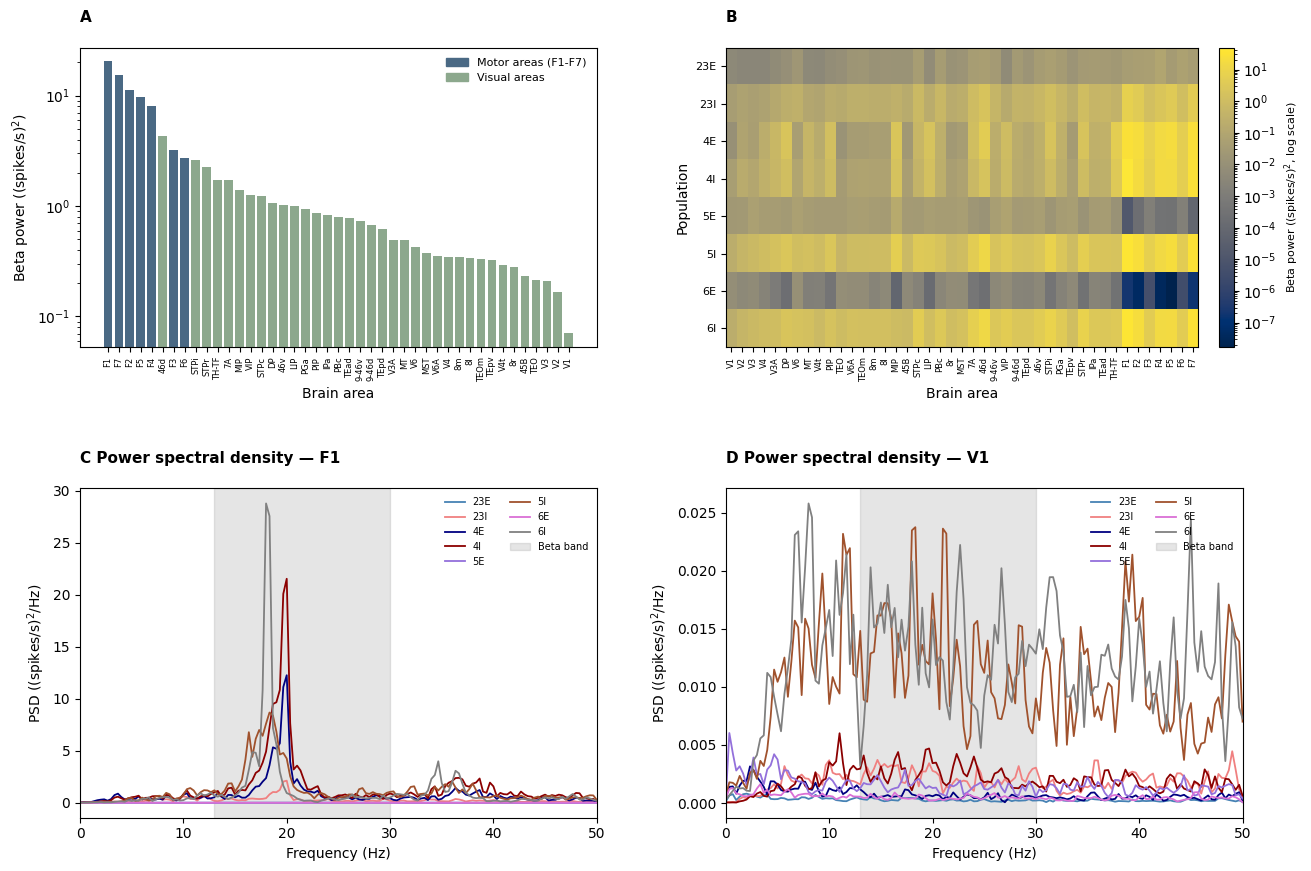

In [132]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors, gridspec
from scipy.signal import welch

np.random.seed(4)

area_list = areas
population_list = ['23E','23I','4E','4I','5E','5I','6E','6I']
motor_areas = ['F1','F2','F3','F4','F5','F6','F7']

fs = 100.0


def band_power(freqs, psd, fmin, fmax):
    idx = (freqs >= fmin) & (freqs <= fmax)
    return np.trapz(psd[idx], freqs[idx])

n_pops = len(population_list)
n_areas = len(area_list)
power_matrix = np.zeros((n_pops, n_areas))
for i, area in enumerate(area_list):
    for j, pop in enumerate(population_list):
        r = results[area][pop]['rate_from_spikes']
        f, Pxx = welch(r, fs=fs, nperseg=300)
        power_matrix[j, i] = band_power(f, Pxx, 13, 30)

area_mean_power = power_matrix.mean(axis=0)

rho_0, Delta_V, tau_e, tau_i, seed_val = 10.0, 5.0, 0.5, 0.5, 4
pop_colors = {'23E':'steelblue','23I':'lightcoral','4E':'navy','4I':'darkred',
              '5E':'mediumpurple','5I':'sienna','6E':'orchid','6I':'gray'}



fig = plt.figure(figsize=(15, 10))
gs = gridspec.GridSpec(2, 2, height_ratios=[1, 1.1], hspace=0.45, wspace=0.25)



# Panel 1

ax1 = fig.add_subplot(gs[0, 0])
order = np.argsort(area_mean_power)[::-1]
sorted_areas = np.array(area_list)[order]
sorted_power = area_mean_power[order]
bar_colors = ['#4A6984' if a in motor_areas else '#8CA88D' for a in sorted_areas]
ax1.bar(range(n_areas), sorted_power, color=bar_colors)
ax1.set_xticks(range(n_areas))
ax1.set_xticklabels(sorted_areas, rotation=90, fontsize=6)
ax1.set_yscale('log')
ax1.set_ylabel(r'Beta power ($(\mathrm{spikes/s})^2$)')
ax1.set_xlabel('Brain area')
ax1.set_title('A\n', fontweight='bold', fontsize=11, loc='left')
handles = [plt.Rectangle((0,0),1,1,color='#4A6984'), plt.Rectangle((0,0),1,1,color='#8CA88D')]
ax1.legend(handles, ['Motor areas (F1-F7)', 'Visual areas'], frameon=False, fontsize=8, loc='upper right')

# Panel 2

ax2 = fig.add_subplot(gs[0, 1])
im = ax2.imshow(power_matrix, aspect='auto', origin='upper',
                 norm=colors.LogNorm(vmin=power_matrix[power_matrix > 0].min(), vmax=power_matrix.max()),
                 cmap='cividis')
ax2.set_xticks(range(n_areas))
ax2.set_xticklabels(area_list, rotation=90, fontsize=6)
ax2.set_yticks(range(n_pops))
ax2.set_yticklabels(population_list, fontsize=8)
ax2.set_xlabel('Brain area')
ax2.set_ylabel('Population')
ax2.set_title('B\n', fontweight='bold', fontsize=11, loc='left')
cbar = fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)
cbar.set_label(r'Beta power ($(\mathrm{spikes/s})^2$, log scale)', fontsize=8)

def plot_psd_panel(ax, area, label):
    for pop in population_list:
        r = results[area][pop]['rate_from_spikes']
        f, Pxx = welch(r, fs=fs, nperseg=300)
        ax.plot(f, Pxx, label=pop, color=pop_colors[pop], linewidth=1.3)
    ax.axvspan(13, 30, color='grey', alpha=0.2, label='Beta band')
    ax.set_xlim(0, 50)
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel(r'PSD ($(\mathrm{spikes/s})^2/\mathrm{Hz}$)')
    ax.set_title(label, fontsize=11, loc='left', fontweight='bold')

# Panel 3

ax3 = fig.add_subplot(gs[1, 0])
plot_psd_panel(ax3, 'F1', 'C Power spectral density — F1 \n')
ax3.legend(fontsize=7, ncol=2, frameon=False)

# Panel 4

ax4 = fig.add_subplot(gs[1, 1])
plot_psd_panel(ax4, 'V1', 'D Power spectral density — V1 \n')
ax4.legend(fontsize=7, ncol=2, frameon=False)

#fig.suptitle(rf'Beta-band activity across the network ($\rho_0$={rho_0}, $\Delta_V$={Delta_V}, '
#             rf'$\tau_e$={tau_e}, $\tau_i$={tau_i}, RNG={seed_val})', fontsize=12, y=0.995)

plt.savefig('output/beta_power_4panel.png', dpi=300, bbox_inches='tight')
#plt.close()
#print("saved")
plt.show()


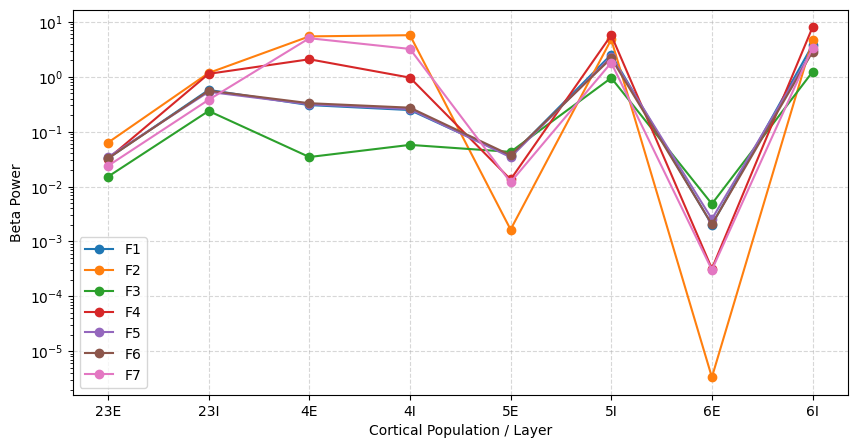

In [88]:
# Example: Plotting just a few selected areas to show the profile shapes
selected_areas = ['F1', 'F2', 'F3', 'F4', 'F5', 'F6', 'F7']
plt.figure(figsize=(10, 5))

for area in selected_areas:
    area_idx = areas.index(area)
    plt.plot(population_list, power_matrix[:, area_idx], marker='o', label=area)

plt.xlabel('Cortical Population / Layer')
plt.ylabel('Beta Power')
plt.yscale('log') # Use log scale here too due to the large scale differences!
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

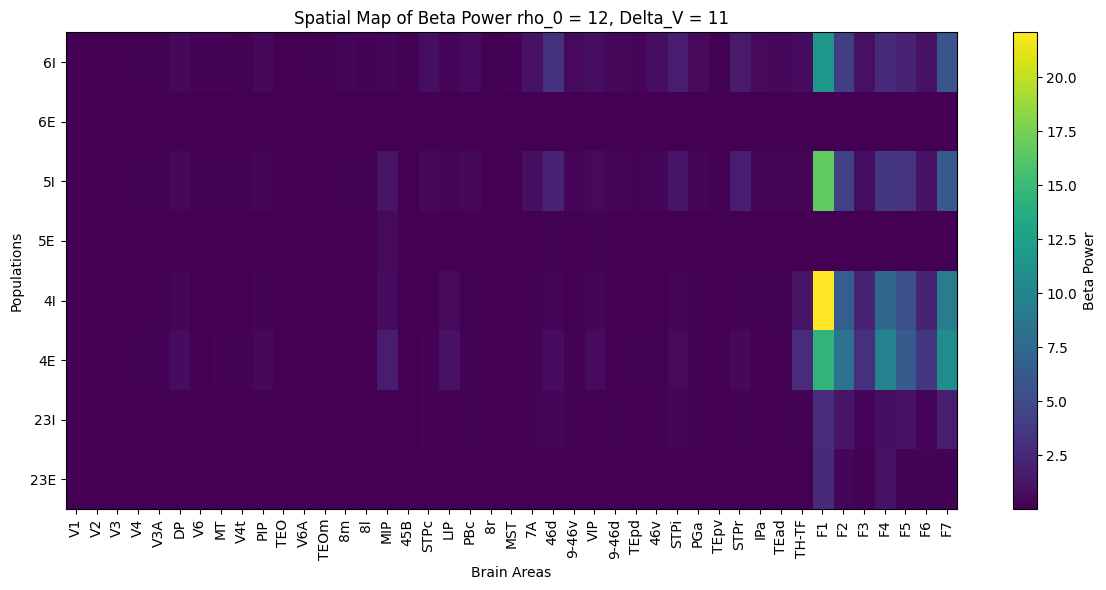

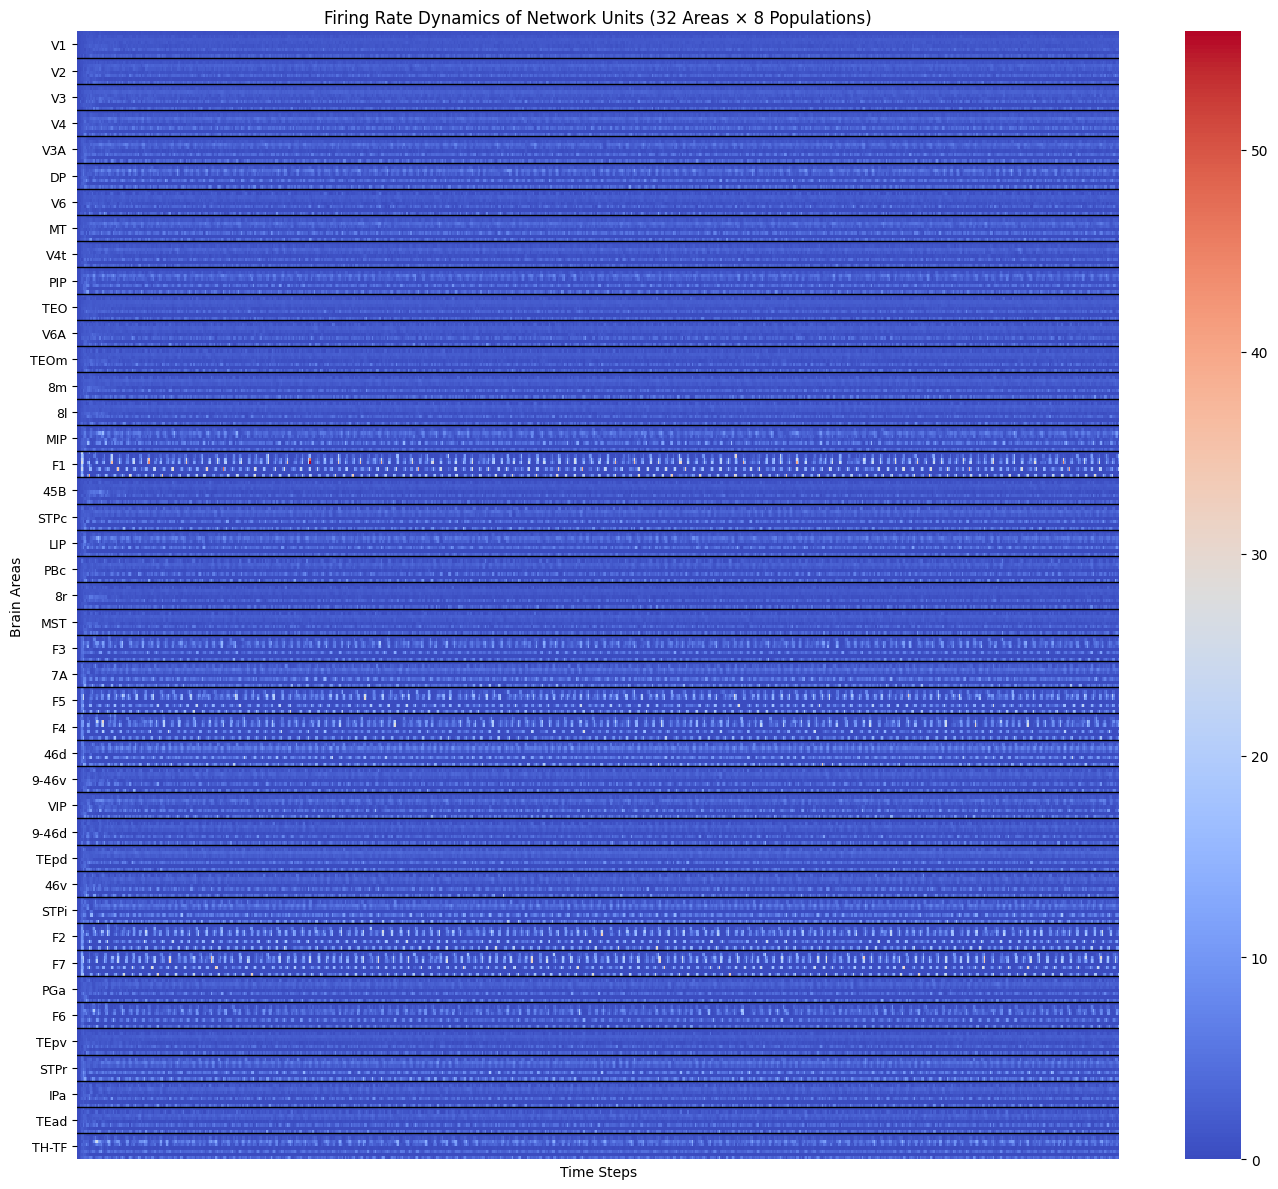

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming data is in the form: data[area][population] = np.array(time_series)
# And Mean_rates[1] = data

# Constants


population_list = ['23E', '23I', '4E', '4I', '5E', '5I', '6E', '6I']

populations_per_area = len(population_list)
num_areas = len(complete_area_list)
num_units = populations_per_area * num_areas

# Load your data
data = results # Replace this with your actual data dictionary



# Create a new transformed dictionary
#transformed_rate_dict = {}
#
#for area, pop_dict in data.items():
#    transformed_rate_dict[area] = {}
#    for pop, h in pop_dict.items():
#        transformed_rate_dict[area][pop] = sigmoidal_transfer_function(h, gain, beta, theta)


# Create the activity matrix: (num_units x num_time_steps)
# Flattened order: [V1_23E, V1_23I, ..., V1_6I, V2_23E, ..., TH_6I]
activity_matrix = []
for area in complete_area_list:
    for pop in population_list:
        activity_matrix.append(data[area][pop]['rate_from_spikes'])  # shape: (time_steps,)


# Convert to 2D NumPy array (neurons x time)
activity_matrix = np.array(activity_matrix)

# Infer time steps from data
num_time_steps = activity_matrix.shape[1]

# Calculate positions to place area names (center of 8-row blocks)
y_ticks_positions = [i * populations_per_area + populations_per_area / 2 for i in range(num_areas)]

# Plot Heatmap
plt.figure(figsize=(14, 12))
ax = sns.heatmap(activity_matrix, cmap="coolwarm", xticklabels=False, yticklabels=False, cbar=True)

# Draw horizontal separator lines between areas
for i in range(1, num_areas):
    plt.axhline(i * populations_per_area, color='black', linewidth=1)

# Add y-axis area names
plt.yticks(y_ticks_positions, complete_area_list, rotation=0, fontsize=9)

# Axis labels and title
plt.xlabel("Time Steps")
plt.ylabel("Brain Areas")
plt.title("Firing Rate Dynamics of Network Units (32 Areas × 8 Populations)")

plt.tight_layout()
plt.show()


# fixed point Analysis

In [ ]:
def Synaptic_weights( tau_syn_ex_ms, tau_syn_in_ms, C_m_pF, w_mean, g, conn_probs_dict, 
                                    cc_weights_factor, cc_weights_I_factor, scaling_factor, area_list, pop_list, meanfield_connectivity=True):

    synaptic_weights_dict = nested_dict()

    for target_area, target_pop, source_area, source_pop in product(area_list, pop_list, area_list, pop_list):

        p = conn_probs_dict[target_area][target_pop][source_area][source_pop]
        N = neuron_numbers[source_area][source_pop]
        # ------------------------------------------------------------------
        # 1. Base PSC weight (like original Potjans weight_matrix)
        # ------------------------------------------------------------------
        if 'E' in source_pop:
            J_psc = w_mean                      # pA
            tau_syn = tau_syn_ex_ms
        else:
            J_psc = g * w_mean                  # pA
            tau_syn = tau_syn_in_ms

        # ------------------------------------------------------------------
        # 2. PSC → PSP (exact original formula)
        # Js *= (tau_syn * 1e-3) / cm * 1e3
        # cm must be in nF → convert from pF
        # ------------------------------------------------------------------
        #C_m_nF = C_m_pF 

        J_psp = J_psc * tau_syn / C_m_pF        # mV

        # ------------------------------------------------------------------
        # 3. Scaling factor (network downscaling)
        # ------------------------------------------------------------------
        J_psp /= scaling_factor

        # ------------------------------------------------------------------
        # 4. Mean-field connectivity
        # ------------------------------------------------------------------
        if meanfield_connectivity:
            J_psp *= p
            effective_p = 1.0
        else:
            effective_p = p

        # ------------------------------------------------------------------
        # 5. Convert to NEST units (pA)
        # J_syn_nestfactor = C_m / tau_syn
        # ------------------------------------------------------------------
        J_pA = J_psp * (C_m_pF / tau_syn)

        # ------------------------------------------------------------------
        # 6. Apply CC scaling (if multi-area)
        # ------------------------------------------------------------------
        if source_area != target_area:
            J_pA *= cc_weights_factor
            if 'I' in target_pop:
                J_pA *= cc_weights_I_factor
        # ------------------------------------------------------------------
        # 7. SPECIAL RULE: L4E → L23E (intra-area only)
        # ------------------------------------------------------------------
        if (source_area == target_area and
            source_pop == '4E' and
            target_pop == '23E'):

            J_pA *= 2.0

        # -----
        # ------------------------------------------------------------------
        # 7. Store result
        # ------------------------------------------------------------------
        synaptic_weights_dict[target_area][target_pop][source_area][source_pop] = J_pA * N

    return synaptic_weights_dict

In [ ]:
W = Synaptic_weights(tau_syn_ex_ms, tau_syn_in_ms, C_m_pF, w_mean=w_mean, g=-14, conn_probs_dict=connection_probs_dict,
                    scaling_factor=1, area_list=complete_area_list, pop_list=population_list, cc_weights_factor=1, cc_weights_I_factor=1)

In [ ]:

def Calc_mean_input( input_dict, neuron_numbers, area_list, population_list):

    populations = {}
    Mean_inputs = {}

    for area in area_list:
        populations[area] = {}
        Mean_inputs[area] = {}

        for pop in population_list:

            # ------------------------------------------------------------------
            # Population size (REAL values now)
            # ------------------------------------------------------------------
            N_pop_float = neuron_numbers[area][pop]
            N_pop = int(np.round(N_pop_float))

            # ------------------------------------------------------------------
            # External input
            # ------------------------------------------------------------------
            mu_mV = input_dict[area][pop]
            I_e_pA = mu_mV * C_m_pF / tau_m_ms
            Mean_inputs[area][pop] = I_e_pA
    return Mean_inputs


In [ ]:
mean_input = Calc_mean_input(mu_sigma_dat, neuron_numbers, complete_area_list, population_list)

In [ ]:
n_pops = len(population_list)

def flat_idx(area, pop):
    return complete_area_list.index(area) * n_pops + population_list.index(pop)

def build_flat_weight_matrix(synaptic_weights_dict, areas, populations):
    n_total = len(areas) * len(populations)
    W_flat = np.zeros((n_total, n_total))
    for t_area in areas:
        for t_pop in populations:
            t_idx = flat_idx(t_area, t_pop)
            for s_area in areas:
                for s_pop in populations:
                    s_idx = flat_idx(s_area, s_pop)
                    W_flat[t_idx, s_idx] = synaptic_weights_dict[t_area][t_pop][s_area][s_pop]
    return W_flat

def build_flat_mu_vector(Mean_inputs, areas, populations):
    n_total = len(areas) * len(populations)
    mu_flat = np.zeros(n_total)
    for area in areas:
        for pop in populations:
            mu_flat[flat_idx(area, pop)] = Mean_inputs[area][pop]
    return mu_flat


# Build once, reuse for every g value
W_flat = build_flat_weight_matrix(W, complete_area_list, population_list)
mu_flat = build_flat_mu_vector(mean_input, complete_area_list, population_list)

print(W_flat.shape, mu_flat.shape)   # (344, 344)  (344,)

(344, 344) (344,)


In [ ]:
from scipy.optimize import fsolve

c_hazard = 10       # 10.0 Hz, same as before
DeltaV = 5.0                        # or per-population array if you have one, size 344
vth = 15
taum = 10           # assuming same tau_m for all — adjust if E/I differ

def hazard(u):
    return c_hazard * np.exp((u - vth) / DeltaV)

def stationary_eqs(A, W_flat, mu_flat, taum):
    u = mu_flat + taum * (W_flat @ A)
    return hazard(u) - A

fixed_points = []
rng = np.random.default_rng(0)
for _ in range(300):
    A0 = rng.uniform(0, 60, size=344)
    sol, info, ier, msg = fsolve(stationary_eqs, A0, args=(W_flat, mu_flat, taum),
                                  full_output=True, maxfev=2000)
    if ier == 1 and np.all(sol >= -1e-3):
        fixed_points.append(np.round(sol, 3))

unique_fps = np.unique(np.array(fixed_points), axis=0)
print(f"Number of distinct fixed points found: {unique_fps.shape[0]}")

/tmp/ipykernel_67249/184209332.py:9: RuntimeWarning:overflow encountered in exp


KeyboardInterrupt: 